# Bureau table: EDA and feature engineering

This notebook studies the credit bureau table and turns it into features, one row per applicant, that can be joined to the application model.

It follows `02_model_selection_training.ipynb`, which ended with a model built on the application table alone: ROC AUC 0.7685 in cross-validation, 0.7715 on the holdout and 0.7638 on Kaggle's private test set. That model's largest limit is that it never sees how an applicant has repaid credit before. The bureau table is the first source of that information.

## Inputs

| File | Rows | One row is | Key |
|---|---:|---|---|
| `data/raw/bureau.csv` | about 1.7 million | One past or current credit the applicant holds at **another** lender, as reported to the credit bureau | `SK_ID_BUREAU`, linked to the applicant by `SK_ID_CURR` |
| `data/raw/bureau_balance.csv` | about 27 million | One month of history for one of those credits. **Examined in stage 1 and then left out**, for the reasons in section 1.6 | `SK_ID_BUREAU` and `MONTHS_BALANCE` |
| `data/processed/application_split.parquet` | 307,511 | The frozen development and holdout split from notebook 02 | `SK_ID_CURR` |

## The problem this notebook solves

The application table has one row per applicant. `bureau` has many rows per applicant. A model needs one row per applicant, so the history has to be summarised: how many credits, how much debt, how recent, how often overdue. Choosing those summaries is the work of this notebook.

```
application (1 row per applicant)
   └── bureau (0 to many credits per applicant)
          └── bureau_balance (0 to many months per credit)   <- not used, see section 1.6
```

## What this notebook does

| # | Stage | Question it answers |
|---|---|---|
| 1 | Structure and keys | Is `SK_ID_BUREAU` unique, how many credits does an applicant have, and how do the tables link? |
| 2 | Coverage and target | Do applicants without a bureau record default at a different rate? Is coverage the same in train and test? |
| 3 | Column-by-column audit | Missing values, placeholders, impossible dates and amounts, and the cleaning rules that follow |
| 4 | Time audit | Does any column describe something after the application date? |
| 5 | Row-level signal | Which bureau columns relate to default? |
| 6 | Aggregation design | Which summaries per applicant are worth building? |
| 7 | Candidate features | Build the full candidate set for train and test |
| 8 | Screening | Signal, redundancy and train-test shift of each candidate, and a first cut of the list |
| 9 | Save | Write the train and test feature tables under `data/processed/` and verify them |

Each stage ends with a findings cell and the decisions taken.

## Rules followed throughout

- **The holdout stays closed.** The 61,503 holdout applicants were set aside in notebook 02. Whenever this notebook looks at `TARGET`, it uses the 246,008 development applicants only. The holdout's bureau rows are still summarised into features, because the model will need them, but their outcomes are never looked at.
- **A feature uses only the applicant's own history rows.** No summary is computed across applicants, so no feature can carry one applicant's outcome to another.
- **Nothing is learned from the target here.** If a feature needs the target (for example a default rate by credit type), it is not built in this notebook. It belongs inside the model pipeline in notebook 04, where it can be fitted on training folds only.
- **Only information available at the application date is used.** Every date in these tables is counted in days or months before the application. Stage 4 checks each one.
- **The test file has no target.** Its bureau rows are used only to build the same features and to compare distributions.

## What this notebook produces

- Cleaning rules for the bureau table.
- A feature table with one row per applicant, for train and test, saved under `data/processed/`.
- A screened list of candidate features, for notebook 04 to test in the model.

## Out of scope

- Whether the features improve the model. That is notebook 04, on the same five folds as before.
- `bureau_balance`. It is available for about a third of bureau credits in train and for nearly all of them in test, so features built from it would not mean the same thing in the two files (section 1.6).
- The other four history tables (`previous_application`, `POS_CASH_balance`, `installments_payments`, `credit_card_balance`).

## Stage 1: Structure and keys

What is in `bureau.csv`, what identifies a row, how many credits an applicant has, and how the table links to the application table above it and to `bureau_balance` below it.

No target is used in this stage.

In [1]:
import time
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)

SEED = 42
RAW = '../data/raw'
PROCESSED = '../data/processed'

started = time.time()
bureau = pd.read_csv(f'{RAW}/bureau.csv')
print(f"bureau.csv: {bureau.shape[0]:,} rows, {bureau.shape[1]} columns, {bureau.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory, read in {time.time() - started:.1f} seconds")
bureau.head()

bureau.csv: 1,716,428 rows, 17 columns, 285 MB in memory, read in 5.1 seconds


,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN


### 1.1 Columns and types

The 17 columns are grouped by what they describe. The descriptions come from `HomeCredit_columns_description.csv`.

In [2]:
COLUMN_GROUPS = {
    'keys': ['SK_ID_CURR', 'SK_ID_BUREAU'],
    'status and type': ['CREDIT_ACTIVE', 'CREDIT_CURRENCY', 'CREDIT_TYPE'],
    'dates (days relative to the application)': ['DAYS_CREDIT', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'DAYS_CREDIT_UPDATE'],
    'amounts': ['AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_OVERDUE', 'AMT_CREDIT_MAX_OVERDUE', 'AMT_ANNUITY'],
    'overdue and prolongation counts': ['CREDIT_DAY_OVERDUE', 'CNT_CREDIT_PROLONG'],
}
group_of = {c: g for g, cols in COLUMN_GROUPS.items() for c in cols}
assert sorted(group_of) == sorted(bureau.columns), set(bureau.columns) ^ set(group_of)

descriptions = pd.read_csv(f'{RAW}/HomeCredit_columns_description.csv', encoding='latin-1')
described = descriptions[descriptions['Table'] == 'bureau.csv'].set_index('Row')['Description']

overview = pd.DataFrame({
    'group': pd.Series(group_of),
    'dtype': bureau.dtypes.astype(str),
    'missing_pct': bureau.isna().mean() * 100,
    'distinct': bureau.nunique(),
    'description': described.reindex(bureau.columns).str.slice(0, 95),
}).loc[[c for cols in COLUMN_GROUPS.values() for c in cols]]
print(f"columns by type: {bureau.dtypes.astype(str).value_counts().to_dict()}")
print(f"columns with a description in the dictionary: {int(overview['description'].notna().sum())} of {len(overview)}")
overview.round(2)

columns by type: {'float64': 8, 'int64': 6, 'str': 3}
columns with a description in the dictionary: 16 of 17


,group,dtype,missing_pct,distinct,description
SK_ID_CURR,keys,int64,0.00,305811,ID of loan in our sample - one loan in our sam...
SK_ID_BUREAU,keys,int64,0.00,1716428,NaN
CREDIT_ACTIVE,status and type,str,0.00,4,Status of the Credit Bureau (CB) reported credits
CREDIT_CURRENCY,status and type,str,0.00,4,Recoded currency of the Credit Bureau credit
CREDIT_TYPE,status and type,str,0.00,15,"Type of Credit Bureau credit (Car, cash,...)"
DAYS_CREDIT,dates (days relative to the application),int64,0.00,2923,How many days before current application did c...
DAYS_CREDIT_ENDDATE,dates (days relative to the application),float64,6.15,14096,Remaining duration of CB credit (in days) at t...
DAYS_ENDDATE_FACT,dates (days relative to the application),float64,36.92,2917,Days since CB credit ended at the time of appl...
DAYS_CREDIT_UPDATE,dates (days relative to the application),int64,0.00,2982,How many days before loan application did last...
AMT_CREDIT_SUM,amounts,float64,0.00,236708,Current credit amount for the Credit Bureau cr...


### 1.2 Keys and duplicates

`SK_ID_BUREAU` should identify one credit, and each credit should belong to exactly one applicant. If either fails, every count built later would be wrong.

In [3]:
key_checks = {
    'no missing value in either key': bool(bureau[['SK_ID_CURR', 'SK_ID_BUREAU']].notna().all().all()),
    'SK_ID_BUREAU is unique (one row per credit)': bool(bureau['SK_ID_BUREAU'].is_unique),
    'each credit belongs to one applicant': bool((bureau.groupby('SK_ID_BUREAU')['SK_ID_CURR'].nunique() == 1).all()),
    'no fully duplicated row': int(bureau.duplicated().sum()) == 0,
}
for name, ok in key_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

# the same credit reported twice under two IDs would be identical in everything except SK_ID_BUREAU
content = [c for c in bureau.columns if c != 'SK_ID_BUREAU']
twins = bureau.duplicated(subset=content, keep=False)
twin_groups = bureau[twins].groupby(content, dropna=False).size()
print(f"\nrows identical to another row of the same applicant in every column except SK_ID_BUREAU: {int(twins.sum()):,} "
      f"({twins.mean():.2%} of rows), in {len(twin_groups):,} groups, largest group {int(twin_groups.max()) if len(twin_groups) else 0}")
print(f"applicants with at least one such group: {bureau.loc[twins, 'SK_ID_CURR'].nunique():,}")
if twins.any():
    print('\nwhat those rows look like:')
    print(bureau[twins].assign(n_missing=bureau[twins].isna().sum(axis=1))[['CREDIT_ACTIVE', 'CREDIT_TYPE']].value_counts().head(6).to_string())
    example_id = bureau.loc[twins, 'SK_ID_CURR'].value_counts().index[0]
    print(f"\nexample, applicant with the most such rows:")
    print(bureau[twins & (bureau['SK_ID_CURR'] == example_id)].head(4).to_string(index=False))

print(f"\nSK_ID_BUREAU range: {bureau['SK_ID_BUREAU'].min():,} to {bureau['SK_ID_BUREAU'].max():,}; "
      f"SK_ID_CURR range: {bureau['SK_ID_CURR'].min():,} to {bureau['SK_ID_CURR'].max():,}")
print(f"file is sorted by applicant: {bool(bureau['SK_ID_CURR'].is_monotonic_increasing)}; "
      f"an applicant's credits are stored together: {bool((bureau['SK_ID_CURR'] != bureau['SK_ID_CURR'].shift()).sum() == bureau['SK_ID_CURR'].nunique())}")

PASS  no missing value in either key
PASS  SK_ID_BUREAU is unique (one row per credit)
PASS  each credit belongs to one applicant
PASS  no fully duplicated row



rows identical to another row of the same applicant in every column except SK_ID_BUREAU: 4,002 (0.23% of rows), in 1,943 groups, largest group 7
applicants with at least one such group: 1,865

what those rows look like:
CREDIT_ACTIVE  CREDIT_TYPE    
Active         Credit card        2817
Closed         Credit card         644
               Consumer credit     299
Active         Consumer credit     124
Closed         Microloan            54
               Car loan             20

example, applicant with the most such rows:
 SK_ID_CURR  SK_ID_BUREAU CREDIT_ACTIVE CREDIT_CURRENCY  DAYS_CREDIT  CREDIT_DAY_OVERDUE  DAYS_CREDIT_ENDDATE  DAYS_ENDDATE_FACT  AMT_CREDIT_MAX_OVERDUE  CNT_CREDIT_PROLONG  AMT_CREDIT_SUM  AMT_CREDIT_SUM_DEBT  AMT_CREDIT_SUM_LIMIT  AMT_CREDIT_SUM_OVERDUE CREDIT_TYPE  DAYS_CREDIT_UPDATE  AMT_ANNUITY
     205360       6668263        Closed      currency 1          -53                   0                -53.0              -53.0                     NaN                

### 1.3 Link to the application table

Which applicants have a bureau record? Applicants are taken from the frozen split (train, divided into development and holdout) and from the processed test table. Only IDs are used here, no outcomes.

In [4]:
split = pd.read_parquet(f'{PROCESSED}/application_split.parquet')
test_ids = pd.read_parquet(f'{PROCESSED}/application_test_features.parquet', columns=[]).index
assert split.index.name == 'SK_ID_CURR' and split.index.is_unique and test_ids.is_unique and len(split.index.intersection(test_ids)) == 0

DEV_IDS = split.index[split['split'] == 'dev']
HOLDOUT_IDS = split.index[split['split'] == 'holdout']
TEST_IDS = test_ids
assert (len(DEV_IDS), len(HOLDOUT_IDS), len(TEST_IDS)) == (246008, 61503, 48744)

part_of = pd.Series('neither file', index=pd.Index(bureau['SK_ID_CURR'].unique(), name='SK_ID_CURR'))
part_of[part_of.index.isin(DEV_IDS)] = 'train: development'
part_of[part_of.index.isin(HOLDOUT_IDS)] = 'train: holdout'
part_of[part_of.index.isin(TEST_IDS)] = 'test'
bureau_part = bureau['SK_ID_CURR'].map(part_of)

n_credits = bureau.groupby('SK_ID_CURR').size()
coverage = {}
for label, ids in {'train: development': DEV_IDS, 'train: holdout': HOLDOUT_IDS, 'test': TEST_IDS}.items():
    has = ids.isin(n_credits.index)
    counts = n_credits.reindex(ids).fillna(0)
    coverage[label] = {'applicants': len(ids), 'with_bureau_record': int(has.sum()), 'with_record_pct': has.mean() * 100,
                       'bureau_rows': int((bureau_part == label).sum()), 'mean_credits_all_applicants': counts.mean(),
                       'mean_credits_if_any': counts[counts > 0].mean()}
coverage = pd.DataFrame(coverage).T
print(coverage.to_string(float_format=lambda v: f'{v:,.2f}'))

orphans = part_of == 'neither file'
print(f"\napplicants in bureau that are in neither application file: {int(orphans.sum()):,}, holding {int((bureau_part == 'neither file').sum()):,} rows "
      f"({(bureau_part == 'neither file').mean():.2%} of bureau)")
print(f"applicants in bureau in total: {len(part_of):,}; applicants in the two application files: {len(split) + len(TEST_IDS):,}")
train_has = split.index.isin(n_credits.index)
print(f"train applicants with a bureau record: {train_has.mean():.2%}; test: {TEST_IDS.isin(n_credits.index).mean():.2%}")

                    applicants  with_bureau_record  with_record_pct  bureau_rows  mean_credits_all_applicants  mean_credits_if_any
train: development  246,008.00          210,764.00            85.67 1,171,299.00                         4.76                 5.56
train: holdout       61,503.00           52,727.00            85.73   294,026.00                         4.78                 5.58
test                 48,744.00           42,320.00            86.82   251,103.00                         5.15                 5.93

applicants in bureau that are in neither application file: 0, holding 0 rows (0.00% of bureau)
applicants in bureau in total: 305,811; applicants in the two application files: 356,255
train applicants with a bureau record: 85.69%; test: 86.82%


### 1.4 Credits per applicant

How much history is there to summarise? The distribution matters for feature design: averages over two credits are noisy, and a few applicants with very long histories can dominate sums.

applicants with at least one bureau record (train and test):
                             count  mean   std  min    5%   25%   50%   75%    95%    99%    max
credits                   305811.0  5.61  4.43  1.0  1.00  2.00  4.00  8.00  14.00  21.00  116.0
active                    305811.0  2.06  1.79  0.0  0.00  1.00  2.00  3.00   5.00   8.00   32.0
closed                    305811.0  3.53  3.43  0.0  0.00  1.00  3.00  5.00  10.00  15.00  108.0
credit_types              305811.0  1.75  0.64  1.0  1.00  1.00  2.00  2.00   3.00   3.00    6.0
years_since_first_credit  305811.0  4.83  2.35  0.0  0.83  2.86  4.99  7.07   7.85   7.97    8.0

by number of credits:
          applicants  pct_of_applicants  pct_of_bureau_rows
credits                                                    
1              41520               13.6                 2.4
2              41004               13.4                 4.8
3 to 5        100208               32.8                22.8
6 to 10        84751              

CREDIT_ACTIVE values: {'Closed': 1079273, 'Active': 630607, 'Sold': 6527, 'Bad debt': 21}


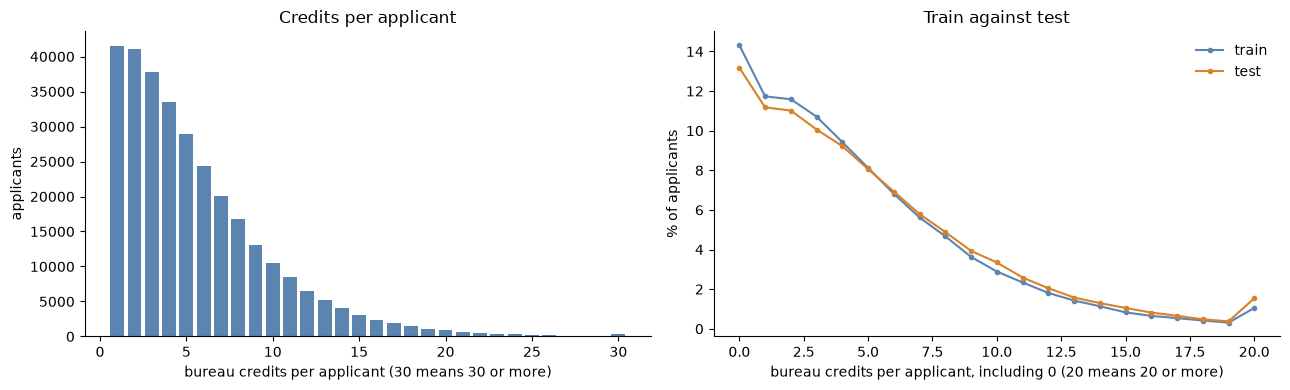

In [5]:
per_applicant = pd.DataFrame({
    'credits': n_credits,
    'active': bureau[bureau['CREDIT_ACTIVE'] == 'Active'].groupby('SK_ID_CURR').size().reindex(n_credits.index).fillna(0).astype(int),
    'closed': bureau[bureau['CREDIT_ACTIVE'] == 'Closed'].groupby('SK_ID_CURR').size().reindex(n_credits.index).fillna(0).astype(int),
    'credit_types': bureau.groupby('SK_ID_CURR')['CREDIT_TYPE'].nunique(),
    'years_since_first_credit': -bureau.groupby('SK_ID_CURR')['DAYS_CREDIT'].min() / 365.25,
})
known = per_applicant[per_applicant.index.isin(split.index) | per_applicant.index.isin(TEST_IDS)]
print('applicants with at least one bureau record (train and test):')
print(known.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T.round(2).to_string())

sizes = pd.cut(known['credits'], [0, 1, 2, 5, 10, 20, 200], labels=['1', '2', '3 to 5', '6 to 10', '11 to 20', 'over 20'])
size_table = pd.DataFrame({'applicants': sizes.value_counts().sort_index(), 'pct_of_applicants': sizes.value_counts(normalize=True).sort_index() * 100,
                           'pct_of_bureau_rows': known['credits'].groupby(sizes, observed=True).sum() / known['credits'].sum() * 100})
print('\nby number of credits:')
print(size_table.round(1).to_string())
print(f"\napplicants with no active credit: {(known['active'] == 0).mean():.1%}; with no closed credit: {(known['closed'] == 0).mean():.1%}")
print(f"CREDIT_ACTIVE values: {bureau['CREDIT_ACTIVE'].value_counts().to_dict()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
shown = known['credits'].clip(upper=30)
axes[0].bar(*np.unique(shown, return_counts=True), color='#5b84b1')
axes[0].set_xlabel('bureau credits per applicant (30 means 30 or more)'); axes[0].set_ylabel('applicants'); axes[0].set_title('Credits per applicant')
for label, ids, colour in [('train', split.index, '#5b84b1'), ('test', TEST_IDS, '#d9822b')]:
    counts = n_credits.reindex(ids).fillna(0).clip(upper=20)
    share = counts.value_counts(normalize=True).sort_index() * 100
    axes[1].plot(share.index, share.values, marker='o', markersize=3, label=label, color=colour)
axes[1].set_xlabel('bureau credits per applicant, including 0 (20 means 20 or more)'); axes[1].set_ylabel('% of applicants'); axes[1].set_title('Train against test')
axes[1].legend(frameon=False)
sns.despine(); plt.tight_layout(); plt.show()

### 1.5 Link to `bureau_balance`

`bureau_balance` holds a monthly status for some credits. It is too large to load in full just to check keys, so only its ID and month columns are read here. Section 1.6 decides whether the table is used.

In [6]:
started = time.time()
balance_keys = pd.read_csv(f'{RAW}/bureau_balance.csv', usecols=['SK_ID_BUREAU', 'MONTHS_BALANCE'], dtype={'SK_ID_BUREAU': 'int32', 'MONTHS_BALANCE': 'int16'})
print(f"bureau_balance.csv: {len(balance_keys):,} rows (two of its three columns read in {time.time() - started:.1f} seconds)")
months = balance_keys.groupby('SK_ID_BUREAU')['MONTHS_BALANCE'].agg(['size', 'min', 'max'])
print(f"credits with monthly history: {len(months):,}")
print(f"one row per credit and month: {bool(months['size'].sum() == len(balance_keys) and not balance_keys.duplicated().any())}")
print(f"MONTHS_BALANCE range: {int(months['min'].min())} to {int(months['max'].max())}; months of history per credit: median {months['size'].median():.0f}, "
      f"mean {months['size'].mean():.1f}, maximum {int(months['size'].max())}")
print(f"credits whose history has no gaps (consecutive months): {(months['size'] == months['max'] - months['min'] + 1).mean():.2%}")
print(f"credits whose history ends in the application month (0): {(months['max'] == 0).mean():.1%}")

has_balance = bureau['SK_ID_BUREAU'].isin(months.index)
print(f"\nbureau credits that have monthly history: {int(has_balance.sum()):,} of {len(bureau):,} ({has_balance.mean():.1%})")
print(f"credits in bureau_balance that are not in bureau: {int((~months.index.isin(bureau['SK_ID_BUREAU'])).sum()):,} of {len(months):,} "
      f"({(~months.index.isin(bureau['SK_ID_BUREAU'])).mean():.1%}), holding {int(months.loc[~months.index.isin(bureau['SK_ID_BUREAU']), 'size'].sum()):,} rows")

applicants_with_balance = pd.Index(bureau.loc[has_balance, 'SK_ID_CURR'].unique())
link = {}
for label, ids in {'train: development': DEV_IDS, 'train: holdout': HOLDOUT_IDS, 'test': TEST_IDS}.items():
    with_bureau = ids.isin(n_credits.index)
    with_balance = ids.isin(applicants_with_balance)
    rows = bureau_part == label
    link[label] = {'applicants': len(ids), 'with_bureau_record_pct': with_bureau.mean() * 100, 'with_any_monthly_history_pct': with_balance.mean() * 100,
                   'of_those_with_a_record_pct': with_balance.sum() / with_bureau.sum() * 100, 'credits_with_history_pct': has_balance[rows].mean() * 100}
print()
print(pd.DataFrame(link).T.to_string(float_format=lambda v: f'{v:,.1f}'))
print(f"\nby credit status, share of credits with monthly history: {has_balance.groupby(bureau['CREDIT_ACTIVE']).mean().mul(100).round(1).to_dict()}")
del balance_keys

bureau_balance.csv: 27,299,925 rows (two of its three columns read in 10.7 seconds)


credits with monthly history: 817,395


one row per credit and month: True
MONTHS_BALANCE range: -96 to 0; months of history per credit: median 26, mean 33.4, maximum 97
credits whose history has no gaps (consecutive months): 100.00%
credits whose history ends in the application month (0): 74.7%



bureau credits that have monthly history: 774,354 of 1,716,428 (45.1%)


credits in bureau_balance that are not in bureau: 43,041 of 817,395 (5.3%), holding 3,120,184 rows



                    applicants  with_bureau_record_pct  with_any_monthly_history_pct  of_those_with_a_record_pct  credits_with_history_pct
train: development   246,008.0                    85.7                          29.9                        35.0                      35.7
train: holdout        61,503.0                    85.7                          30.2                        35.2                      35.9
test                  48,744.0                    86.8                          86.8                       100.0                      99.9

by credit status, share of credits with monthly history: {'Active': 44.7, 'Bad debt': 14.3, 'Closed': 45.4, 'Sold': 44.9}


### 1.6 Decision: `bureau_balance` is left out

Section 1.5 found that monthly history exists for about a third of bureau credits in train and for nearly all of them in test. This section measures how large that difference is from a model's point of view, without using the target.

The test used is the one from the application EDA: can a classifier tell which file an applicant came from? An area under the curve of 0.5 means the two files look the same on that feature. Here the "classifier" is a single yes or no: does the applicant have any monthly history?

In [7]:
from sklearn.metrics import roc_auc_score

credits_with_history = has_balance.groupby(bureau['SK_ID_CURR']).mean()          # share of each applicant's credits that have monthly history
TRAIN_IDS = split.index

rows = {}
for label, ids in {'train (development and holdout)': TRAIN_IDS, 'test': TEST_IDS}.items():
    share = credits_with_history.reindex(ids)                                      # missing = applicant has no bureau record
    with_record = share.notna()
    rows[label] = {'applicants': len(ids), 'with a bureau record': int(with_record.sum()),
                   'no credit has monthly history (%)': (share[with_record] == 0).mean() * 100,
                   'some credits have it (%)': ((share[with_record] > 0) & (share[with_record] < 1)).mean() * 100,
                   'every credit has it (%)': (share[with_record] == 1).mean() * 100}
print('applicants with a bureau record, by how much of their history has monthly detail:')
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f'{v:,.1f}'))

# how well does each yes-or-no feature tell a test applicant from a train applicant? 0.5 = cannot tell
both = TRAIN_IDS.append(TEST_IDS)
is_test = np.r_[np.zeros(len(TRAIN_IDS)), np.ones(len(TEST_IDS))]
has_record = both.isin(n_credits.index)
flags = {
    'has a bureau record (all applicants)': (has_record.astype(float), np.ones(len(both), dtype=bool)),
    'has any monthly history (all applicants)': (both.isin(applicants_with_balance).astype(float), np.ones(len(both), dtype=bool)),
    'has any monthly history (applicants with a bureau record)': (both.isin(applicants_with_balance).astype(float), has_record),
}
print('\ntelling test applicants from train applicants with one yes-or-no feature (AUC):')
for label, (flag, rows_used) in flags.items():
    print(f"  {label:<60} {roc_auc_score(is_test[rows_used], flag[rows_used]):.4f}")

missing_train = 1 - TRAIN_IDS.isin(applicants_with_balance).mean()
missing_test = 1 - TEST_IDS.isin(applicants_with_balance).mean()
print(f"\na feature built from bureau_balance would be missing for {missing_train:.1%} of train applicants and {missing_test:.1%} of test applicants")
print(f"of that, missing only because the applicant has no bureau record at all: train {1 - TRAIN_IDS.isin(n_credits.index).mean():.1%}, test {1 - TEST_IDS.isin(n_credits.index).mean():.1%}")

applicants with a bureau record, by how much of their history has monthly detail:
                                 applicants  with a bureau record  no credit has monthly history (%)  some credits have it (%)  every credit has it (%)
train (development and holdout)   307,511.0             263,491.0                               65.0                       0.1                     34.9
test                               48,744.0              42,320.0                                0.0                       0.5                     99.4

telling test applicants from train applicants with one yes-or-no feature (AUC):


  has a bureau record (all applicants)                         0.5057
  has any monthly history (all applicants)                     0.7840
  has any monthly history (applicants with a bureau record)    0.8249



a feature built from bureau_balance would be missing for 70.0% of train applicants and 13.2% of test applicants
of that, missing only because the applicant has no bureau record at all: train 14.3%, test 13.2%


**The decision.** `bureau_balance` is not used: no features are built from it in this notebook, and it is not given to the model in notebook 04.

**Why**

1. **The table is not available on equal terms in the two files.** Among applicants with a bureau record, about 35% of those in train have any monthly history and all of those in test do. The output above puts a number on it: that single yes-or-no fact separates test applicants from train applicants far better than chance, where "has a bureau record" barely separates them at all.
2. **A model would learn something about the data collection, not about applicants.** In train, a `bureau_balance` feature would be missing for about 70% of applicants. Tree models treat "missing" as a value and split on it. Whatever the model learned that "missing" implies would then be applied to a test file where the feature is almost never missing for the same kind of applicant. The model would be used outside the conditions it was trained in, on its newest features.
3. **Cross-validation and the holdout cannot detect the damage.** Both are drawn from train, where the coverage is the same in every fold (35.7% in development, 35.9% in the holdout). A feature that fails for this reason would score well in every check this project has, and fail only on the test file. Notebook 02 relied on cross-validation carrying over to Kaggle, and it did (0.7685 against 0.7638). Using this table would put that at risk for features whose behaviour on the test file cannot be validated beforehand.
4. **Selecting on the Kaggle score is not an acceptable way round it.** The only way to find out whether `bureau_balance` features help on the test file would be to submit with and without them and keep the better one. That is tuning on the test set, which the rules of this project exclude.
5. **The cause is unknown.** Nothing in the documentation explains why monthly history was supplied for a third of train credits. If the missing two thirds were chosen in a way related to the applicant or the outcome, the features would also be biased inside train. Stage 2 checks whether having monthly history relates to default among development applicants.

**What is given up**
- The month-by-month record of whether each credit was paid on time, and for how long it was overdue. This is real information about repayment behaviour, and published solutions to this competition did use it.
- So this is a choice for a model whose validation can be trusted over a model that might score higher on this particular test file.

**What is kept**
- `bureau` itself carries overdue information for every credit, with no coverage gap: days currently overdue (`CREDIT_DAY_OVERDUE`), the amount currently overdue (`AMT_CREDIT_SUM_OVERDUE`), the largest amount ever overdue (`AMT_CREDIT_MAX_OVERDUE`) and the number of prolongations (`CNT_CREDIT_PROLONG`). Stages 3 to 6 build on those.

**How it could be revisited.** If the table were wanted later, the honest test would be to hide monthly history from a random two thirds of a validation fold's credits and see whether the features still help. That is a separate piece of work and is not done here.

### Stage 1 findings

**The table**
- `bureau.csv` has 1,716,428 rows and 17 columns: 2 keys, 3 text columns, 4 dates, 6 amounts and 2 counts.
- One row is one credit at another lender. `SK_ID_BUREAU` is unique, every credit belongs to exactly one applicant, and neither key has a missing value. No row is fully duplicated.
- Five columns have missing values, and three of them are mostly empty: `AMT_ANNUITY` (71%), `AMT_CREDIT_MAX_OVERDUE` (66%) and `DAYS_ENDDATE_FACT` (37%, expected, since an open credit has no closing date). Stage 3 looks at what the gaps mean.
- The file is not sorted, and an applicant's credits are not stored together. Nothing can rely on row order.
- The dictionary describes 16 of the 17 columns. The one it misses is `SK_ID_BUREAU`, which it lists under a different spelling.

**Near-duplicates**
- 4,002 rows (0.23%) are identical to another row of the same applicant in everything except `SK_ID_BUREAU`. They form 1,943 groups, the largest of 7 rows, across 1,865 applicants.
- Most are credit cards (3,461 of them). The example shown is several closed cards opened and closed on the same day with zero amounts.
- These could be the same credit reported more than once, or genuinely separate cards with no activity. The data cannot say which. They are too few to matter for most features but would inflate counts for those applicants. Stage 3 decides what to do with them.

**Link to the application table**

| | Applicants | With a bureau record | Credits per applicant with a record |
|---|---:|---:|---:|
| Train, development | 246,008 | 85.7% | 5.56 |
| Train, holdout | 61,503 | 85.7% | 5.58 |
| Test | 48,744 | 86.8% | 5.93 |

- Every applicant in `bureau` is in one of the two application files. There are no orphan rows.
- About 1 applicant in 7 has no bureau record at all. Every bureau feature will be missing for them, so "has no record" is itself a feature, and stage 2 checks whether it relates to default.
- Development and holdout match, as a random split should. Test applicants are slightly more likely to have a record and have slightly more credits. This is small, but it is in the same direction as the population difference found in notebook 01.

**How much history there is**
- Among applicants with a record, the median is 4 credits and the mean 5.6. 27% have only one or two, so averages for them rest on very little.
- At the other end, 1% have more than 20 credits and one has 116. Sums over credits will be dominated by this tail.
- 18% of applicants with a record have no active credit, and 12% have no closed credit. Features computed separately for active and closed credits will each be missing for those groups.
- Almost all credits are `Closed` (63%) or `Active` (37%). `Sold` has 6,527 rows and `Bad debt` only 21.
- The oldest credit is at most 8.0 years before the application. The bureau history has a fixed window of eight years, so "years since first credit" is cut off at 8 and does not measure the true length of a long credit history.

**Link to `bureau_balance`, and a large difference between train and test**
- `bureau_balance` has 27,299,925 rows for 817,395 credits: one row per credit and month, with no gaps, going back at most 96 months. The median credit has 26 months.
- 43,041 of those credits (5.3%, 3.1 million rows) are not in `bureau` at all, so they cannot be linked to an applicant and are unusable.
- Only 45% of the credits in `bureau` have monthly history. The share is the same for active and closed credits.
- **The coverage differs sharply between the files:**

| | Credits with monthly history | Applicants with a record who have any |
|---|---:|---:|
| Train, development | 35.7% | 35.0% |
| Train, holdout | 35.9% | 35.2% |
| Test | 99.9% | 100.0% |

- In the test file essentially every bureau credit has monthly history. In train about a third do. This is not a property of the applicants. It is how the data was assembled.
- Section 1.6 measures what this would do to a model and records the decision to leave the table out.

**Leakage check for this stage**
- No target was used. The split file was read for IDs only.

**Decisions**
- `SK_ID_BUREAU` and `SK_ID_CURR` are sound keys. Aggregation by `SK_ID_CURR` is safe.
- Applicants with no bureau record keep missing values for bureau features, plus an explicit count of credits that is 0 for them.
- Because histories are short for many applicants and very long for a few, stage 6 will prefer counts, shares and extremes over raw sums, and will consider capping.
- The near-duplicates are carried to stage 3.
- **`bureau_balance` is left out of this notebook and of the model.** Section 1.6 gives the reasons and what is given up.


## Stage 2: Coverage and target

Do applicants without a bureau record default at a different rate from those with one? Does the amount of history matter? And is "has no bureau record" new information, or something the application model already knows?

**This is the first stage that uses `TARGET`.** Only the 246,008 development applicants are used for anything involving outcomes. The holdout's outcomes are not loaded.

| Section | Question |
|---|---|
| 2.1 | Load the development outcomes |
| 2.2 | Default rate with and without a bureau record |
| 2.3 | Default rate by amount of history |
| 2.4 | Does the application model already know who has no record? |
| 2.5 | Is coverage the same in train and test? (no target) |
| 2.6 | Does having monthly history relate to default? (the check promised in section 1.6) |

### 2.1 Development outcomes

`TARGET` is read for the development applicants only, together with the few application columns that section 2.4 needs.

In [8]:
APPLICATION_COLUMNS = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'EXT_MEAN', 'AMT_REQ_CREDIT_BUREAU_YEAR', 'DAYS_BIRTH', 'DAYS_EMPLOYED']
dev = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet', columns=['TARGET'] + APPLICATION_COLUMNS).loc[DEV_IDS]
y_dev = dev['TARGET']
assert len(dev) == 246008 and dev.index.equals(DEV_IDS) and int(y_dev.sum()) == 19860
assert len(dev.index.intersection(HOLDOUT_IDS)) == 0 and len(dev.index.intersection(TEST_IDS)) == 0
BASE_RATE = y_dev.mean()
print(f"development applicants: {len(dev):,}, defaults {int(y_dev.sum()):,}, default rate {BASE_RATE:.2%}")
print('holdout outcomes loaded: none')

def rate_table(groups, y=None, order=None):
    # default rate per group with a 95% interval (Wilson), on development applicants
    y = y_dev if y is None else y
    g = pd.DataFrame({'group': np.asarray(groups), 'y': y.values}).groupby('group', observed=True)['y'].agg(['size', 'sum', 'mean'])
    n, k, z = g['size'], g['sum'], 1.96
    centre = (k + z * z / 2) / (n + z * z)
    half = z * np.sqrt(g['mean'] * (1 - g['mean']) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    out = pd.DataFrame({'applicants': n, 'pct_of_applicants': n / n.sum() * 100, 'defaults': k, 'default_pct': g['mean'] * 100,
                        'low_pct': (centre - half) * 100, 'high_pct': (centre + half) * 100, 'ratio_to_overall': g['mean'] / y.mean()})
    return out if order is None else out.reindex([o for o in order if o in out.index])

development applicants: 246,008, defaults 19,860, default rate 8.07%
holdout outcomes loaded: none


### 2.2 With and without a bureau record

In [9]:
dev_credits = n_credits.reindex(DEV_IDS).fillna(0).astype(int)
dev_has_record = dev_credits > 0

record_table = rate_table(np.where(dev_has_record, 'has a bureau record', 'no bureau record'))
print(record_table.round(2).to_string())
a, b = record_table.loc['no bureau record'], record_table.loc['has a bureau record']
difference = a['default_pct'] - b['default_pct']
se = np.sqrt(a['default_pct'] / 100 * (1 - a['default_pct'] / 100) / a['applicants'] + b['default_pct'] / 100 * (1 - b['default_pct'] / 100) / b['applicants']) * 100
print(f"\ndifference (no record minus record): {difference:+.2f} points, standard error {se:.2f}, z = {difference / se:.1f}")
auc_flag = roc_auc_score(y_dev, (~dev_has_record).astype(int))
print(f"'no bureau record' used alone as a score: AUC {max(auc_flag, 1 - auc_flag):.4f} ({'no record means higher risk' if auc_flag > 0.5 else 'no record means lower risk'})")

                     applicants  pct_of_applicants  defaults  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                         
has a bureau record      210764              85.67     16293         7.73     7.62      7.85              0.96
no bureau record          35244              14.33      3567        10.12     9.81     10.44              1.25

difference (no record minus record): +2.39 points, standard error 0.17, z = 14.0
'no bureau record' used alone as a score: AUC 0.5198 (no record means higher risk)


### 2.3 By amount of history

Three counts per applicant: all credits, active credits and closed credits. Applicants with no record are shown as their own group, because for them the count is zero for a different reason: the bureau knows nothing about them.


all credits:
                  applicants  pct_of_applicants  default_pct  low_pct  high_pct
group                                                                          
no bureau record       35244              14.33        10.12     9.81     10.44
1                      28773              11.70         8.50     8.18      8.83
2                      28610              11.63         7.85     7.54      8.17
3 to 5                 69574              28.28         7.43     7.24      7.63
6 to 10                58048              23.60         7.44     7.23      7.66
11 to 20               23780               9.67         7.93     7.59      8.28
over 20                 1979               0.80        11.37    10.04     12.84

active credits:
                  applicants  pct_of_applicants  default_pct  low_pct  high_pct
group                                                                          
no bureau record       35244              14.33        10.12     9.81     10.44
0        


each count used alone as a score:
                                 auc_among_applicants_with_a_record               direction
number of credits                                          0.504102   more means lower risk
number of active credits                                   0.560321  more means higher risk
number of closed credits                                   0.546193   more means lower risk
share of credits that are active                            0.58345  more means higher risk


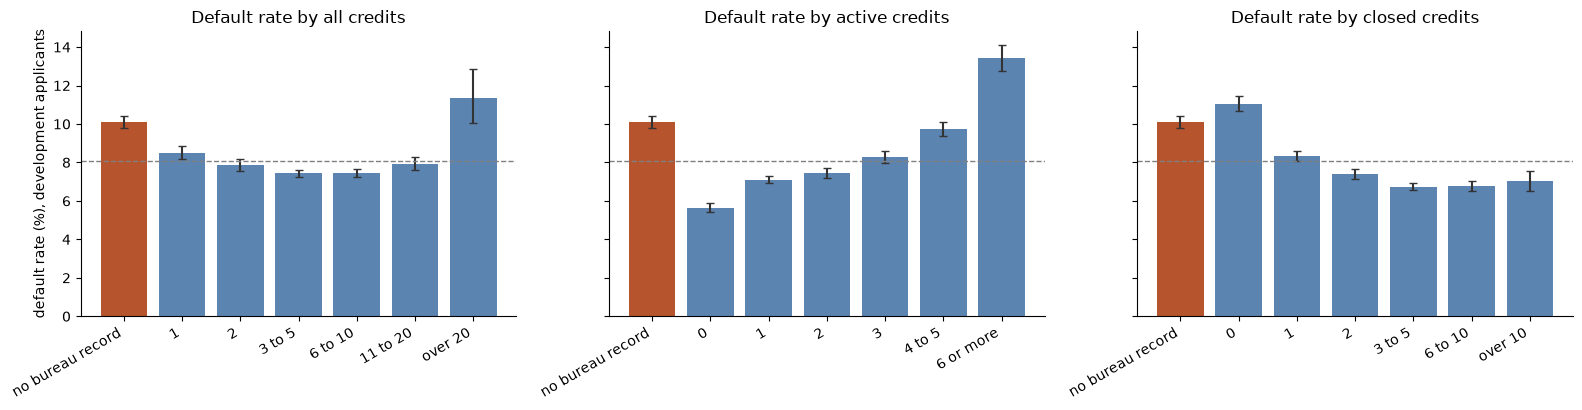

In [10]:
dev_active = per_applicant['active'].reindex(DEV_IDS).fillna(0).astype(int)
dev_closed = per_applicant['closed'].reindex(DEV_IDS).fillna(0).astype(int)

def bucket(counts, edges, labels):
    out = pd.cut(counts, edges, labels=labels).astype(object)
    out[~dev_has_record.values] = 'no bureau record'
    return out

views = {
    'all credits': (bucket(dev_credits, [0, 1, 2, 5, 10, 20, 500], ['1', '2', '3 to 5', '6 to 10', '11 to 20', 'over 20']),
                    ['no bureau record', '1', '2', '3 to 5', '6 to 10', '11 to 20', 'over 20']),
    'active credits': (bucket(dev_active, [-1, 0, 1, 2, 3, 5, 500], ['0', '1', '2', '3', '4 to 5', '6 or more']),
                       ['no bureau record', '0', '1', '2', '3', '4 to 5', '6 or more']),
    'closed credits': (bucket(dev_closed, [-1, 0, 1, 2, 5, 10, 500], ['0', '1', '2', '3 to 5', '6 to 10', 'over 10']),
                       ['no bureau record', '0', '1', '2', '3 to 5', '6 to 10', 'over 10']),
}
tables = {}
for label, (groups, order) in views.items():
    tables[label] = rate_table(groups, order=order)
    print(f"\n{label}:")
    print(tables[label][['applicants', 'pct_of_applicants', 'default_pct', 'low_pct', 'high_pct']].round(2).to_string())

# each count alone as a score, among applicants who have a record
with_record = dev_has_record.values
signal = {}
for label, counts in {'number of credits': dev_credits, 'number of active credits': dev_active, 'number of closed credits': dev_closed,
                      'share of credits that are active': dev_active / dev_credits.where(dev_credits > 0)}.items():
    auc = roc_auc_score(y_dev[with_record], counts[with_record])
    signal[label] = {'auc_among_applicants_with_a_record': max(auc, 1 - auc), 'direction': 'more means higher risk' if auc > 0.5 else 'more means lower risk'}
print('\neach count used alone as a score:')
print(pd.DataFrame(signal).T.to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, (label, table) in zip(axes, tables.items()):
    x = np.arange(len(table))
    colours = ['#b5542d' if i == 'no bureau record' else '#5b84b1' for i in table.index]
    ax.bar(x, table['default_pct'], color=colours, yerr=[table['default_pct'] - table['low_pct'], table['high_pct'] - table['default_pct']], capsize=3, ecolor='#333333')
    ax.axhline(BASE_RATE * 100, color='grey', linestyle='--', linewidth=1)
    ax.set_xticks(x); ax.set_xticklabels(table.index, rotation=30, ha='right'); ax.set_title(f'Default rate by {label}')
axes[0].set_ylabel('default rate (%), development applicants')
sns.despine(); plt.tight_layout(); plt.show()

### 2.4 Does the application model already know who has no record?

The application table has columns that come from the credit bureau: the number of bureau enquiries in the last year (`AMT_REQ_CREDIT_BUREAU_YEAR`) and, very probably, the external scores. If those are missing for exactly the applicants with no bureau record, then "no bureau record" is already in the application model and adds nothing new.

In [11]:
no_record = ~dev_has_record.values
known = pd.DataFrame({
    'AMT_REQ_CREDIT_BUREAU_YEAR is missing': dev['AMT_REQ_CREDIT_BUREAU_YEAR'].isna().values,
    'EXT_SOURCE_1 is missing': dev['EXT_SOURCE_1'].isna().values,
    'EXT_SOURCE_2 is missing': dev['EXT_SOURCE_2'].isna().values,
    'EXT_SOURCE_3 is missing': dev['EXT_SOURCE_3'].isna().values,
}, index=dev.index)
overlap = pd.DataFrame({c: {'missing_pct_overall': known[c].mean() * 100, 'missing_pct_if_no_record': known.loc[no_record, c].mean() * 100,
                            'missing_pct_if_record': known.loc[~no_record, c].mean() * 100,
                            'no_record_pct_if_missing': no_record[known[c].values].mean() * 100,
                            'agreement_with_no_record_pct': (known[c].values == no_record).mean() * 100} for c in known.columns}).T
print(overlap.round(1).to_string())

print('\ndefault rate by bureau record and by whether the enquiry count is missing:')
cross = rate_table(np.where(no_record, 'no record', 'record') + np.where(known['AMT_REQ_CREDIT_BUREAU_YEAR is missing'].values, ', enquiries missing', ', enquiries present'))
print(cross[['applicants', 'pct_of_applicants', 'default_pct', 'low_pct', 'high_pct']].round(2).to_string())

print('\ndefault rate by bureau record and by whether EXT_SOURCE_3 is missing:')
cross3 = rate_table(np.where(no_record, 'no record', 'record') + np.where(known['EXT_SOURCE_3 is missing'].values, ', EXT_SOURCE_3 missing', ', EXT_SOURCE_3 present'))
print(cross3[['applicants', 'pct_of_applicants', 'default_pct', 'low_pct', 'high_pct']].round(2).to_string())

# who are the applicants with no record?
profile = pd.DataFrame({'age_years': -dev['DAYS_BIRTH'] / 365.25, 'years_employed': -dev['DAYS_EMPLOYED'] / 365.25, 'EXT_MEAN': dev['EXT_MEAN'],
                        'EXT_SOURCE_2': dev['EXT_SOURCE_2']}).groupby(np.where(no_record, 'no bureau record', 'has a bureau record')).median()
print('\nmedians:')
print(profile.round(3).to_string())

                                       missing_pct_overall  missing_pct_if_no_record  missing_pct_if_record  no_record_pct_if_missing  agreement_with_no_record_pct
AMT_REQ_CREDIT_BUREAU_YEAR is missing                 13.5                      94.3                    0.0                     100.0                          99.2
EXT_SOURCE_1 is missing                               56.3                      60.6                   55.6                      15.4                          46.7
EXT_SOURCE_2 is missing                                0.2                       0.3                    0.2                      21.3                          85.5
EXT_SOURCE_3 is missing                               19.8                      96.9                    6.9                      70.0                          93.6

default rate by bureau record and by whether the enquiry count is missing:
                              applicants  pct_of_applicants  default_pct  low_pct  high_pct
group       

                                 applicants  pct_of_applicants  default_pct  low_pct  high_pct
group                                                                                         
no record, EXT_SOURCE_3 missing       34163              13.89        10.21     9.90     10.54
no record, EXT_SOURCE_3 present        1081               0.44         7.22     5.82      8.91
record, EXT_SOURCE_3 missing          14642               5.95         7.10     6.69      7.52
record, EXT_SOURCE_3 present         196122              79.72         7.78     7.66      7.90

medians:
                     age_years  years_employed  EXT_MEAN  EXT_SOURCE_2
has a bureau record     43.222           4.665     0.525         0.569
no bureau record        42.185           3.578     0.519         0.545


### 2.5 Coverage in train and test

No target is used here. The question is whether the amount of bureau history is distributed the same way in the test file, since features built on counts would shift with it.

In [12]:
def psi_counts(a, b, edges):
    pa = pd.cut(a, edges).value_counts(normalize=True).sort_index() + 1e-4
    pb = pd.cut(b, edges).value_counts(normalize=True).sort_index() + 1e-4
    return float(((pb - pa) * np.log(pb / pa)).sum())

edges = [-1, 0, 1, 2, 5, 10, 20, 500]
labels = ['0 (no record)', '1', '2', '3 to 5', '6 to 10', '11 to 20', 'over 20']
parts = {'train: development': DEV_IDS, 'train: holdout': HOLDOUT_IDS, 'test': TEST_IDS}
dist = pd.DataFrame({label: pd.cut(n_credits.reindex(ids).fillna(0), edges, labels=labels).value_counts(normalize=True).sort_index() * 100 for label, ids in parts.items()})
print('% of applicants by number of bureau credits:')
print(dist.round(2).to_string())

shift = {}
for label, series in {'credits': n_credits, 'active credits': per_applicant['active'], 'closed credits': per_applicant['closed']}.items():
    get = lambda ids: series.reindex(ids).fillna(0)
    shift[label] = {'mean_development': get(DEV_IDS).mean(), 'mean_holdout': get(HOLDOUT_IDS).mean(), 'mean_test': get(TEST_IDS).mean(),
                    'psi_development_vs_holdout': psi_counts(get(DEV_IDS), get(HOLDOUT_IDS), edges),
                    'psi_development_vs_test': psi_counts(get(DEV_IDS), get(TEST_IDS), edges)}
print('\nshift in the counts (PSI under 0.1 is usually called stable):')
print(pd.DataFrame(shift).T.round(4).to_string())

recent = bureau[bureau['DAYS_CREDIT'] >= -365].groupby('SK_ID_CURR').size()
print(f"\ncredits opened in the year before the application, per applicant: development {recent.reindex(DEV_IDS).fillna(0).mean():.2f}, "
      f"holdout {recent.reindex(HOLDOUT_IDS).fillna(0).mean():.2f}, test {recent.reindex(TEST_IDS).fillna(0).mean():.2f}")

% of applicants by number of bureau credits:
               train: development  train: holdout   test
0 (no record)               14.33           14.27  13.18
1                           11.70           11.87  11.18
2                           11.63           11.42  11.01
3 to 5                      28.28           28.14  27.34
6 to 10                     23.60           23.70  24.88
11 to 20                     9.67            9.80  11.16
over 20                      0.80            0.80   1.25



shift in the counts (PSI under 0.1 is usually called stable):
                mean_development  mean_holdout  mean_test  psi_development_vs_holdout  psi_development_vs_test
credits                   4.7612        4.7807     5.1515                      0.0001                   0.0066
active credits            1.7623        1.7623     1.8195                      0.0003                   0.0014
closed credits            2.9805        3.0001     3.3140                      0.0001                   0.0088



credits opened in the year before the application, per applicant: development 0.91, holdout 0.91, test 0.92


### 2.6 Does having monthly history relate to default?

Section 1.6 left one question open. About a third of train credits have monthly history in `bureau_balance`. If the applicants who have it default at a different rate from those who do not, then its absence is informative in train for a reason that does not exist in test, which would make the table more dangerous still. If the rates are the same, the gap is at least not biased inside train.

Development applicants with a bureau record only.

In [13]:
dev_share = credits_with_history.reindex(DEV_IDS)
has_rec = dev_share.notna().values
kind = np.select([dev_share[has_rec] == 0, dev_share[has_rec] == 1], ['no credit has monthly history', 'every credit has monthly history'], 'some credits have it')
history_table = rate_table(kind, y=y_dev[has_rec], order=['no credit has monthly history', 'some credits have it', 'every credit has monthly history'])
print(history_table[['applicants', 'pct_of_applicants', 'default_pct', 'low_pct', 'high_pct', 'ratio_to_overall']].round(2).to_string())

any_history = (dev_share[has_rec] > 0).astype(int)
auc_history = roc_auc_score(y_dev[has_rec], any_history)
t = rate_table(np.where(any_history == 1, 'any', 'none'), y=y_dev[has_rec])
gap = t.loc['any', 'default_pct'] - t.loc['none', 'default_pct']
gap_se = np.sqrt(sum(t.loc[g, 'default_pct'] / 100 * (1 - t.loc[g, 'default_pct'] / 100) / t.loc[g, 'applicants'] for g in ['any', 'none'])) * 100
print(f"\nany monthly history against none: {t.loc['any', 'default_pct']:.2f}% against {t.loc['none', 'default_pct']:.2f}%, "
      f"difference {gap:+.2f} points, standard error {gap_se:.2f}, z = {gap / gap_se:.1f}")
print(f"'has any monthly history' used alone as a score: AUC {max(auc_history, 1 - auc_history):.4f}")

# is it tied to the number of credits? compare within applicants of the same history size
same_size = pd.DataFrame({'credits': pd.cut(dev_credits[has_rec], [0, 2, 5, 10, 500], labels=['1 to 2', '3 to 5', '6 to 10', 'over 10']).values,
                          'any': np.where(any_history.values == 1, 'default_pct, any monthly history', 'default_pct, none'), 'y': y_dev[has_rec].values})
print('\nwithin applicants with a similar number of credits:')
print((same_size.groupby(['credits', 'any'], observed=True)['y'].mean().unstack() * 100).round(2).to_string())
print(f"\nmedian number of credits: with any monthly history {dev_credits[has_rec][any_history.values == 1].median():.0f}, with none {dev_credits[has_rec][any_history.values == 0].median():.0f}")

                                  applicants  pct_of_applicants  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                            
no credit has monthly history         137098              65.05         7.52     7.38      7.66              0.97
some credits have it                     159               0.08        22.01    16.27     29.07              2.85
every credit has monthly history       73507              34.88         8.09     7.90      8.29              1.05



any monthly history against none: 8.12% against 7.52%, difference +0.60 points, standard error 0.12, z = 4.9
'has any monthly history' used alone as a score: AUC 0.5096



within applicants with a similar number of credits:
any      default_pct, any monthly history  default_pct, none
credits                                                     
1 to 2                               8.54               7.99
3 to 5                               7.63               7.32
6 to 10                              8.00               7.14
over 10                              8.78               7.86



median number of credits: with any monthly history 5, with none 4


### Stage 2 findings

All figures involving default are from the 246,008 development applicants. The holdout's outcomes were not loaded.

**Having no bureau record is a risk signal**

| | Applicants | Default rate | 95% interval |
|---|---:|---:|---:|
| Has a bureau record | 210,764 (85.7%) | 7.73% | 7.62% to 7.85% |
| No bureau record | 35,244 (14.3%) | 10.12% | 9.81% to 10.44% |

- The difference is 2.39 points, 14 standard errors from zero. Applicants the bureau knows nothing about default about a third more often.
- As a score on its own it is weak (AUC 0.520), because it only splits applicants into two groups.

**The application model already knows most of it**
- `AMT_REQ_CREDIT_BUREAU_YEAR`, an application column, is missing for 94% of applicants with no bureau record and for none of those with one. The two agree for 99.2% of applicants.
- `EXT_SOURCE_3` is missing for 97% of applicants with no record and 7% of those with one. That strongly suggests `EXT_SOURCE_3` is built from credit bureau data. `EXT_SOURCE_1` and `EXT_SOURCE_2` show no such link.
- So a "no bureau record" flag will add little to the model from notebook 02, which has both of those columns and can see when they are missing. The gain from this table has to come from what is inside the records.
- The 2,000 applicants with no record but with an enquiry count default at 6.5%, below average. The higher risk belongs to applicants the bureau has not heard of at all, not to those merely without a credit.

**What matters is the kind of credit, not the number**

| Count | Lowest group | Highest group | AUC alone |
|---|---|---|---:|
| All credits | 3 to 10 credits: 7.4% | Over 20: 11.4%; one credit: 8.5% | 0.504 |
| Active credits | None: 5.6% | 6 or more: 13.4% | 0.560 |
| Closed credits | 3 or more: about 6.8% | None: 11.1% | 0.546 |
| Share of credits that are active | | | 0.583 |

- The total number of credits carries almost nothing (AUC 0.504). Its relationship with default is U-shaped, and the two halves cancel.
- Splitting it by status reveals two opposite effects. More **active** credits means more risk, rising steadily from 5.6% with none to 13.4% with six or more. More **closed** credits means less risk: applicants with a record but no closed credit default at 11.1%, those with three or more at about 6.8%.
- The reading is plain: closed credits are evidence of loans repaid, and active credits are current obligations. A simple ratio of the two (AUC 0.583) is already better than either count.
- This sets the direction for stage 6. Almost every summary should be computed separately for active and closed credits, and ratios between the two are likely to be among the best features.
- An applicant with a record but no closed credit (11.1%) is as risky as one with no record (10.1%). "No evidence of repayment" looks like the common factor.

**Coverage is stable between train and test**
- The distribution of credit counts barely moves: PSI of 0.007 for all credits, 0.001 for active and 0.009 for closed. Development and holdout are indistinguishable (0.0001 to 0.0003).
- Test applicants have slightly more closed credits (3.31 against 2.98 on average). The number opened in the year before the application is the same (0.91 and 0.92).
- Nothing here resembles the shift found for `ANNUITY_TO_CREDIT` in notebook 02. Features built from `bureau` start from a stable base.

**`bureau_balance`: the check promised in section 1.6 makes the case for leaving it out stronger**
- Monthly history is assigned per applicant, not per credit. Among applicants with a record, 65.0% have it for no credit and 34.9% have it for every credit. Only 0.1% are in between.
- Having it is related to default inside train. Applicants with monthly history default at 8.12%, those without at 7.52%: a difference of 0.60 points, 4.9 standard errors from zero. The difference has the same sign in every band of credit count, so it is not explained by those applicants having longer histories.
- So the third of train applicants who were given monthly history were not a random third. Whatever decided it is related to the outcome.
- That is the worst case section 1.6 described. In train, the mere presence of `bureau_balance` features would carry a small signal about default. In test every applicant with a record has them, so that signal would not exist there. A model would learn a pattern that is partly produced by how the data was assembled.
- The 159 applicants with partial history default at 22%, but that is too few to build on.

**Leakage check for this stage**
- Outcomes were read for development applicants only, and an assertion confirms that no holdout or test ID is among them.
- Nothing was fitted. Every figure is a count, a rate or the AUC of a raw count.
- Section 2.5 used no target.

**Decisions**
- Keep a count of credits that is 0 for applicants with no record, and leave all other bureau features missing for them. A separate "no record" flag is not needed: the count carries it, and the application model largely has it already.
- Build counts and summaries separately for active and closed credits, and ratios between them. The total alone is not worth keeping.
- `Sold` and `Bad debt` credits are too few for their own summaries (6,527 and 21 rows). Stage 3 decides how to group them.
- The exclusion of `bureau_balance` stands, now with evidence that its coverage in train is related to the target.


## Stage 3: Column-by-column audit

What is wrong with each column, and what should be done about it before any feature is built?

Stage 1 showed that a table can look healthy and still be unusable, because `bureau_balance` was supplied on different terms in train and test. So this audit asks two questions of every column, not one:

1. **Is the value believable?** Missing values, placeholders, impossible dates, negative amounts, contradictions between columns.
2. **Is the column supplied on the same terms in train and test?** If a column is filled in far more often in one file than the other, features built from it will not mean the same thing in both.

**No target is used in this stage.** Every check is on the values themselves or on which file a row belongs to. Whether a column relates to default is stage 5.

| Section | What it covers |
|---|---|
| 3.1 | The three text columns |
| 3.2 | Missing values: how much, and where |
| 3.3 | Is each column supplied equally in train and test? |
| 3.4 | A closer look at the columns that fail 3.3 |
| 3.5 | Dates |
| 3.6 | Amounts and currency |
| 3.7 | Contradictions between columns, and the near-duplicates from stage 1 |
| 3.8 | The cleaning rules, as one function, and their effect |

### 3.1 Text columns

Three columns hold text: the status of the credit, its currency, and its type. Shares are shown separately for the three parts of the data so that a difference between train and test is visible straight away.

In [14]:
PARTS = ['train: development', 'train: holdout', 'test']
NUMERIC = [c for c in bureau.columns if c not in ('SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'CREDIT_CURRENCY', 'CREDIT_TYPE')]
assert set(bureau_part.unique()) == set(PARTS)

for c in ['CREDIT_ACTIVE', 'CREDIT_CURRENCY', 'CREDIT_TYPE']:
    table = pd.crosstab(bureau[c], bureau_part, normalize='columns')[PARTS] * 100
    table.insert(0, 'rows', bureau[c].value_counts())
    table['applicants'] = bureau.groupby(c)['SK_ID_CURR'].nunique()
    table['test_to_development'] = table['test'] / table['train: development']
    print(f"\n{c}: {bureau[c].nunique()} values, {int(bureau[c].isna().sum())} missing (shares in % of each part's rows)")
    print(table.sort_values('rows', ascending=False).to_string(float_format=lambda v: f'{v:,.3f}'))

by_currency = bureau.groupby('CREDIT_CURRENCY')['AMT_CREDIT_SUM'].agg(['size', 'median'])
print('\nmedian credit amount by currency (the amounts are in different units):')
print(by_currency.to_string(float_format=lambda v: f'{v:,.0f}'))
print(f"applicants holding credits in more than one currency: {int((bureau.groupby('SK_ID_CURR')['CREDIT_CURRENCY'].nunique() > 1).sum()):,}")


CREDIT_ACTIVE: 4 values, 0 missing (shares in % of each part's rows)
SK_ID_CURR        rows  train: development  train: holdout   test  applicants  test_to_development
CREDIT_ACTIVE                                                                                     
Closed         1079273              62.599          62.754 64.332      267925                1.028
Active          630607              37.013          36.864 35.319      251815                0.954
Sold              6527               0.387           0.381  0.348        6021                0.899
Bad debt            21               0.001           0.001  0.000          21                0.292



CREDIT_CURRENCY: 4 values, 0 missing (shares in % of each part's rows)
SK_ID_CURR          rows  train: development  train: holdout   test  applicants  test_to_development
CREDIT_CURRENCY                                                                                     
currency 1       1715020              99.914          99.926 99.930      305773                1.000
currency 2          1224               0.075           0.067  0.061         970                0.809
currency 3           174               0.011           0.007  0.010         157                0.868
currency 4            10               0.001           0.000  0.000          10                0.583



CREDIT_TYPE: 15 values, 0 missing (shares in % of each part's rows)
SK_ID_CURR                                       rows  train: development  train: holdout   test  applicants  test_to_development
CREDIT_TYPE                                                                                                                      
Consumer credit                               1251615              72.985          73.032 72.482      286669                0.993
Credit card                                    402195              23.481          23.405 23.234      199965                0.989
Car loan                                        27690               1.618           1.634  1.566       22796                0.968
Mortgage                                        18391               1.067           1.057  1.109       16854                1.039
Microloan                                       12413               0.611           0.627  1.357        4565                2.220
Loan for business dev

applicants holding credits in more than one currency: 1,072


### 3.2 Missing values

How much is missing in each column, whether it depends on the status of the credit, and whether an applicant's credits are missing a value together (which would point to a reporting source, not to the credit).

In [15]:
has_missing = [c for c in NUMERIC if bureau[c].isna().any()]
missing = pd.DataFrame({'missing_rows': bureau[has_missing].isna().sum(), 'missing_pct': bureau[has_missing].isna().mean() * 100})
for status in ['Active', 'Closed', 'Sold']:
    missing[f'pct_if_{status.lower()}'] = bureau.loc[bureau['CREDIT_ACTIVE'] == status, has_missing].isna().mean() * 100
for label in PARTS:
    missing[label] = bureau.loc[bureau_part == label, has_missing].isna().mean() * 100
# per applicant: are the values of one applicant all present or all missing?
per_applicant_missing = bureau[has_missing].isna().groupby(bureau['SK_ID_CURR']).mean()
several = n_credits[n_credits >= 3].index
missing['all_or_nothing_pct'] = ((per_applicant_missing.loc[several] == 0) | (per_applicant_missing.loc[several] == 1)).mean() * 100
print('missing values (%). The last column is the share of applicants with 3 or more credits whose credits are either all missing or all present.')
print(missing.sort_values('missing_pct', ascending=False).to_string(float_format=lambda v: f'{v:,.1f}'))

# if missingness were independent between an applicant's credits, how often would it be all-or-nothing?
expected = {}
for c in has_missing:
    q = bureau[c].isna().mean()
    k = n_credits.loc[several]
    expected[c] = float((q ** k + (1 - q) ** k).mean() * 100)
print('\nall-or-nothing share expected if each credit were missing independently (%):')
print(pd.Series(expected).round(1).to_string())
print(f"\ncolumns never missing: {[c for c in NUMERIC if c not in has_missing]}")

missing values (%). The last column is the share of applicants with 3 or more credits whose credits are either all missing or all present.
                        missing_rows  missing_pct  pct_if_active  pct_if_closed  pct_if_sold  train: development  train: holdout  test  all_or_nothing_pct
AMT_ANNUITY                  1226791         71.5           68.4           73.3         70.0                77.2            76.9  38.5                67.1
AMT_CREDIT_MAX_OVERDUE       1124488         65.5           65.4           65.5         76.7                64.7            64.7  70.1                24.4
DAYS_ENDDATE_FACT             633653         36.9           99.7            0.0         74.8                37.2            37.0  35.4                12.1
AMT_CREDIT_SUM_LIMIT          591780         34.5           27.5           38.3         75.5                33.4            33.6  40.7                23.8
AMT_CREDIT_SUM_DEBT           257669         15.0           11.7           16.7       


all-or-nothing share expected if each credit were missing independently (%):
DAYS_CREDIT_ENDDATE        65.6
DAYS_ENDDATE_FACT          10.6
AMT_CREDIT_MAX_OVERDUE     11.9
AMT_CREDIT_SUM            100.0
AMT_CREDIT_SUM_DEBT        37.2
AMT_CREDIT_SUM_LIMIT       11.9
AMT_ANNUITY                16.5

columns never missing: ['DAYS_CREDIT', 'CREDIT_DAY_OVERDUE', 'CNT_CREDIT_PROLONG', 'AMT_CREDIT_SUM_OVERDUE', 'DAYS_CREDIT_UPDATE']


### 3.3 Is each column supplied equally in train and test?

The test that exposed `bureau_balance` in section 1.6, applied to every column. For each applicant with a bureau record, compute the share of their credits where the value is present (or non-zero, or of a given kind). Then ask how well that one number tells a test applicant from a train applicant.

An AUC of 0.50 means the column is supplied on the same terms in both files. `bureau_balance` scored 0.82. As a guide, anything above about 0.55 deserves a closer look.

In [16]:
TRAIN_WITH_RECORD = TRAIN_IDS[TRAIN_IDS.isin(n_credits.index)]
TEST_WITH_RECORD = TEST_IDS[TEST_IDS.isin(n_credits.index)]
order_ids = TRAIN_WITH_RECORD.append(TEST_WITH_RECORD)
from_test = np.r_[np.zeros(len(TRAIN_WITH_RECORD)), np.ones(len(TEST_WITH_RECORD))]

def supply_auc(row_flag):
    # row_flag: one True or False per bureau row. Returns the train and test rates and the AUC of the per-applicant share.
    share = row_flag.astype(float).groupby(bureau['SK_ID_CURR']).mean().reindex(order_ids).values
    auc = roc_auc_score(from_test, share)
    train_rows, test_rows = bureau_part != 'test', bureau_part == 'test'
    return {'pct_of_train_rows': row_flag[train_rows].mean() * 100, 'pct_of_test_rows': row_flag[test_rows].mean() * 100,
            'applicants_with_any_train_pct': (share[from_test == 0] > 0).mean() * 100, 'applicants_with_any_test_pct': (share[from_test == 1] > 0).mean() * 100,
            'auc_test_vs_train': max(auc, 1 - auc), 'more_common_in': 'test' if auc > 0.5 else 'train'}

flags = {f'{c} is present': bureau[c].notna() for c in has_missing}
flags.update({f'{c} is above zero': bureau[c] > 0 for c in ['AMT_ANNUITY', 'AMT_CREDIT_MAX_OVERDUE', 'AMT_CREDIT_SUM_OVERDUE', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT',
                                                           'CREDIT_DAY_OVERDUE', 'CNT_CREDIT_PROLONG']})
flags.update({f'{c} is exactly zero': bureau[c] == 0 for c in ['AMT_ANNUITY', 'AMT_CREDIT_MAX_OVERDUE', 'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT']})
flags.update({f'status is {v}': bureau['CREDIT_ACTIVE'] == v for v in ['Active', 'Closed', 'Sold']})
flags.update({f'type is {v}': bureau['CREDIT_TYPE'] == v for v in ['Consumer credit', 'Credit card', 'Car loan', 'Mortgage', 'Microloan']})
flags['currency is not currency 1'] = bureau['CREDIT_CURRENCY'] != 'currency 1'
flags['has monthly history in bureau_balance (for reference)'] = has_balance

supply = pd.DataFrame({label: supply_auc(flag) for label, flag in flags.items()}).T.sort_values('auc_test_vs_train', ascending=False)
print(f"applicants with a bureau record: train {len(TRAIN_WITH_RECORD):,}, test {len(TEST_WITH_RECORD):,}\n")
print(supply.to_string(float_format=lambda v: f'{v:,.3f}'))

# the same question for the size of the values: per-applicant median of each numeric column
levels = {}
for c in NUMERIC:
    med = bureau.groupby('SK_ID_CURR')[c].median().reindex(order_ids)
    ok = med.notna().values
    auc = roc_auc_score(from_test[ok], med.values[ok])
    levels[c] = {'median_of_applicant_medians_train': med[from_test == 0].median(), 'median_of_applicant_medians_test': med[from_test == 1].median(),
                 'auc_test_vs_train': max(auc, 1 - auc), 'higher_in': 'test' if auc > 0.5 else 'train'}
print("\nthe same test on the values themselves (each applicant's median):")
print(pd.DataFrame(levels).T.sort_values('auc_test_vs_train', ascending=False).to_string(float_format=lambda v: f'{v:,.3f}'))
SUPPLY_FLAGGED = [label for label in supply.index if supply.loc[label, 'auc_test_vs_train'] >= 0.55 and 'bureau_balance' not in label]
print(f"\nflagged at 0.55 or above: {SUPPLY_FLAGGED}")

applicants with a bureau record: train 263,491, test 42,320

                                                      pct_of_train_rows pct_of_test_rows applicants_with_any_train_pct applicants_with_any_test_pct auc_test_vs_train more_common_in
has monthly history in bureau_balance (for reference)            35.727           99.895                        35.003                       99.979             0.824           test
AMT_ANNUITY is present                                           22.883           61.459                        30.365                       90.300             0.780           test
AMT_ANNUITY is exactly zero                                      11.416           35.694                        20.130                       72.172             0.756           test
AMT_ANNUITY is above zero                                        11.467           25.765                        22.874                       70.640             0.719           test
AMT_CREDIT_SUM_LIMIT is present   


the same test on the values themselves (each applicant's median):
                       median_of_applicant_medians_train median_of_applicant_medians_test auc_test_vs_train higher_in
AMT_ANNUITY                                    3,915.000                          110.250             0.550     train
DAYS_CREDIT                                     -958.000                         -981.000             0.509     train
AMT_CREDIT_SUM                               133,600.500                      135,000.000             0.508      test
DAYS_CREDIT_UPDATE                              -361.000                         -320.250             0.508      test
DAYS_ENDDATE_FACT                               -873.500                         -862.500             0.507      test
AMT_CREDIT_MAX_OVERDUE                             0.000                            0.000             0.507     train
AMT_CREDIT_SUM_DEBT                                0.000                            0.000             0.506

### 3.4 A closer look at the columns flagged in 3.3

For each flagged column: how it is supplied per applicant in each part of the data, and whether its supply follows the same pattern as `bureau_balance`.

In [17]:
def supply_profile(row_flag, name):
    share = row_flag.astype(float).groupby(bureau['SK_ID_CURR']).mean()
    out = {}
    for label, ids in {'train: development': DEV_IDS, 'train: holdout': HOLDOUT_IDS, 'test': TEST_IDS}.items():
        s = share.reindex(ids).dropna()
        out[label] = {'applicants with a record': len(s), 'for no credit (%)': (s == 0).mean() * 100, 'for some credits (%)': ((s > 0) & (s < 1)).mean() * 100,
                      'for every credit (%)': (s == 1).mean() * 100, 'average share of credits (%)': s.mean() * 100}
    print(f"\n{name}: applicants by how many of their credits have it")
    print(pd.DataFrame(out).T.to_string(float_format=lambda v: f'{v:,.1f}'))

annuity_present = bureau['AMT_ANNUITY'].notna()
supply_profile(annuity_present, 'AMT_ANNUITY is present')
supply_profile(bureau['AMT_ANNUITY'] > 0, 'AMT_ANNUITY is above zero')
supply_profile(bureau['AMT_CREDIT_MAX_OVERDUE'].notna(), 'AMT_CREDIT_MAX_OVERDUE is present')
supply_profile(bureau['AMT_CREDIT_SUM_LIMIT'].notna(), 'AMT_CREDIT_SUM_LIMIT is present')
supply_profile(bureau['CNT_CREDIT_PROLONG'] > 0, 'CNT_CREDIT_PROLONG is above zero')
supply_profile(bureau['CREDIT_TYPE'] == 'Microloan', 'type is Microloan')

print('\nAMT_ANNUITY presence against monthly history in bureau_balance (% of rows with AMT_ANNUITY present):')
print((pd.crosstab([bureau_part, has_balance.rename('has monthly history')], annuity_present.rename('AMT_ANNUITY present'), normalize='index') * 100).round(1).to_string())
print('\nAMT_ANNUITY by credit status and part (% present, then % above zero):')
print(pd.DataFrame({'present_pct': annuity_present.groupby([bureau_part, bureau['CREDIT_ACTIVE']]).mean() * 100,
                    'above_zero_pct': (bureau['AMT_ANNUITY'] > 0).groupby([bureau_part, bureau['CREDIT_ACTIVE']]).mean() * 100}).unstack(0).round(1).loc[['Active', 'Closed']].to_string())

# does it depend on when the record was last updated?
update_band = pd.cut(-bureau['DAYS_CREDIT_UPDATE'], [-400, 30, 90, 365, 730, 1460, 50000], labels=['last 30 days', '31 to 90', '91 to 365', '1 to 2 years', '2 to 4 years', 'over 4 years'])
by_update = pd.DataFrame({'rows': update_band.value_counts().sort_index(),
                          'AMT_ANNUITY present, train (%)': annuity_present[bureau_part != 'test'].groupby(update_band[bureau_part != 'test'], observed=True).mean() * 100,
                          'AMT_ANNUITY present, test (%)': annuity_present[bureau_part == 'test'].groupby(update_band[bureau_part == 'test'], observed=True).mean() * 100,
                          'CNT_CREDIT_PROLONG above zero, train (%)': (bureau['CNT_CREDIT_PROLONG'] > 0)[bureau_part != 'test'].groupby(update_band[bureau_part != 'test'], observed=True).mean() * 100,
                          'CNT_CREDIT_PROLONG above zero, test (%)': (bureau['CNT_CREDIT_PROLONG'] > 0)[bureau_part == 'test'].groupby(update_band[bureau_part == 'test'], observed=True).mean() * 100})
print('\nby when the bureau record was last updated:')
print(by_update.round(2).to_string())


AMT_ANNUITY is present: applicants by how many of their credits have it
                    applicants with a record  for no credit (%)  for some credits (%)  for every credit (%)  average share of credits (%)
train: development                 210,764.0               69.7                  18.9                  11.4                          22.1
train: holdout                      52,727.0               69.4                  19.1                  11.5                          22.3
test                                42,320.0                9.7                  70.1                  20.2                          60.8



AMT_ANNUITY is above zero: applicants by how many of their credits have it
                    applicants with a record  for no credit (%)  for some credits (%)  for every credit (%)  average share of credits (%)
train: development                 210,764.0               77.2                  17.8                   5.0                          12.1
train: holdout                      52,727.0               76.8                  18.0                   5.1                          12.3
test                                42,320.0               29.4                  64.9                   5.8                          27.7



AMT_CREDIT_MAX_OVERDUE is present: applicants by how many of their credits have it
                    applicants with a record  for no credit (%)  for some credits (%)  for every credit (%)  average share of credits (%)
train: development                 210,764.0               30.3                  59.6                  10.1                          34.9
train: holdout                      52,727.0               29.9                  59.9                  10.2                          35.1
test                                42,320.0               31.3                  60.7                   8.0                          30.9



AMT_CREDIT_SUM_LIMIT is present: applicants by how many of their credits have it
                    applicants with a record  for no credit (%)  for some credits (%)  for every credit (%)  average share of credits (%)
train: development                 210,764.0                8.0                  59.0                  33.0                          68.3
train: holdout                      52,727.0                8.0                  59.4                  32.6                          68.1
test                                42,320.0               10.1                  66.0                  23.9                          60.9



CNT_CREDIT_PROLONG is above zero: applicants by how many of their credits have it
                    applicants with a record  for no credit (%)  for some credits (%)  for every credit (%)  average share of credits (%)
train: development                 210,764.0               96.8                   3.1                   0.1                           0.7
train: holdout                      52,727.0               96.8                   3.1                   0.1                           0.7
test                                42,320.0               99.3                   0.7                   0.0                           0.1



type is Microloan: applicants by how many of their credits have it
                    applicants with a record  for no credit (%)  for some credits (%)  for every credit (%)  average share of credits (%)
train: development                 210,764.0               98.7                   1.3                   0.1                           0.4
train: holdout                      52,727.0               98.7                   1.3                   0.1                           0.4
test                                42,320.0               97.5                   2.4                   0.1                           0.8

AMT_ANNUITY presence against monthly history in bureau_balance (% of rows with AMT_ANNUITY present):


AMT_ANNUITY present                     False  True 
SK_ID_CURR         has monthly history              
test               False                 24.6   75.4
                   True                  38.6   61.4
train: development False                100.0    0.0
                   True                  36.1   63.9
train: holdout     False                100.0    0.0
                   True                  35.7   64.3

AMT_ANNUITY by credit status and part (% present, then % above zero):


              present_pct                                   above_zero_pct                                  
SK_ID_CURR           test train: development train: holdout           test train: development train: holdout
CREDIT_ACTIVE                                                                                               
Active               77.3               24.0           24.3           63.5               15.4           15.6
Closed               52.7               22.1           22.3            5.0                9.1            9.3



by when the bureau record was last updated:
                      rows  AMT_ANNUITY present, train (%)  AMT_ANNUITY present, test (%)  CNT_CREDIT_PROLONG above zero, train (%)  CNT_CREDIT_PROLONG above zero, test (%)
DAYS_CREDIT_UPDATE                                                                                                                                                          
last 30 days        409297                           27.47                          78.07                                      1.04                                     0.22
31 to 90            176724                           21.04                          70.61                                      0.75                                     0.14
91 to 365           249224                           23.20                          48.07                                      0.48                                     0.07
1 to 2 years        306917                           19.03                          41.42 

### 3.5 Dates

Four columns count days relative to the application: negative is before it, positive is after. The bureau history covers eight years (2,922 days), so a date far outside that range is either a placeholder or an error.

                        count   mean   std     min   0.1%     1%    25%  50%  75%    99%  99.9%    max
DAYS_CREDIT         1,716,428 -1,142   795  -2,922 -2,917 -2,867 -1,666 -987 -474    -38    -10      0
DAYS_CREDIT_ENDDATE 1,610,875    511 4,994 -42,060 -2,737 -2,571 -1,138 -330  474 31,029 31,184 31,199
DAYS_ENDDATE_FACT   1,082,775 -1,017   714 -42,023 -2,789 -2,639 -1,489 -897 -425    -24     -5      0
DAYS_CREDIT_UPDATE  1,716,428   -594   721 -41,947 -2,742 -2,531   -908 -395  -33     -3     -1    372

earliest DAYS_CREDIT: -2,922 days (8.00 years)

rows:
DAYS_CREDIT after the application (above 0)               0
DAYS_CREDIT on the application day (0)                   25
DAYS_CREDIT_ENDDATE before the eight-year window        150
DAYS_CREDIT_ENDDATE before the credit was opened        164
DAYS_CREDIT_ENDDATE more than 30 years ahead          42687
   of which credit cards                              42497
   of which between 84 and 86 years ahead             30174
DAYS_ENDDA

share of each part's rows: {'train: development': 2.47, 'train: holdout': 2.44, 'test': 2.63}
planned end missing: credit cards 21.1%, other types 1.6%


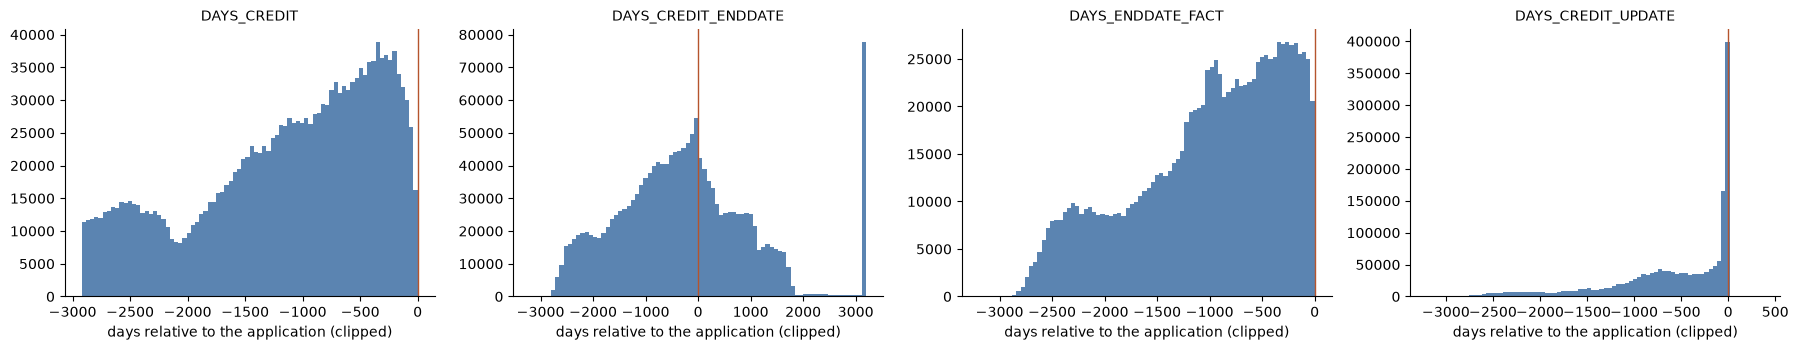

In [18]:
DATES = ['DAYS_CREDIT', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'DAYS_CREDIT_UPDATE']
print(bureau[DATES].describe(percentiles=[0.001, 0.01, 0.25, 0.5, 0.75, 0.99, 0.999]).T.to_string(float_format=lambda v: f'{v:,.0f}'))

WINDOW = int(-bureau['DAYS_CREDIT'].min())
print(f"\nearliest DAYS_CREDIT: -{WINDOW:,} days ({WINDOW / 365.25:.2f} years)")
is_card = bureau['CREDIT_TYPE'] == 'Credit card'
date_checks = pd.Series({
    'DAYS_CREDIT after the application (above 0)': int((bureau['DAYS_CREDIT'] > 0).sum()),
    'DAYS_CREDIT on the application day (0)': int((bureau['DAYS_CREDIT'] == 0).sum()),
    'DAYS_CREDIT_ENDDATE before the eight-year window': int((bureau['DAYS_CREDIT_ENDDATE'] < -WINDOW).sum()),
    'DAYS_CREDIT_ENDDATE before the credit was opened': int((bureau['DAYS_CREDIT_ENDDATE'] < bureau['DAYS_CREDIT']).sum()),
    'DAYS_CREDIT_ENDDATE more than 30 years ahead': int((bureau['DAYS_CREDIT_ENDDATE'] > 365.25 * 30).sum()),
    '   of which credit cards': int(((bureau['DAYS_CREDIT_ENDDATE'] > 365.25 * 30) & is_card).sum()),
    '   of which between 84 and 86 years ahead': int(bureau['DAYS_CREDIT_ENDDATE'].between(365.25 * 84, 365.25 * 86).sum()),
    'DAYS_ENDDATE_FACT before the eight-year window': int((bureau['DAYS_ENDDATE_FACT'] < -WINDOW).sum()),
    'DAYS_ENDDATE_FACT before the credit was opened': int((bureau['DAYS_ENDDATE_FACT'] < bureau['DAYS_CREDIT']).sum()),
    'DAYS_ENDDATE_FACT after the application (above 0)': int((bureau['DAYS_ENDDATE_FACT'] > 0).sum()),
    'DAYS_CREDIT_UPDATE before the eight-year window': int((bureau['DAYS_CREDIT_UPDATE'] < -WINDOW).sum()),
    'DAYS_CREDIT_UPDATE before the credit was opened': int((bureau['DAYS_CREDIT_UPDATE'] < bureau['DAYS_CREDIT']).sum()),
    'DAYS_CREDIT_UPDATE after the application (above 0)': int((bureau['DAYS_CREDIT_UPDATE'] > 0).sum()),
})
print('\nrows:')
print(date_checks.to_string())

far = bureau['DAYS_CREDIT_ENDDATE'] > 365.25 * 30
print(f"\nplanned end more than 30 years ahead: {far.mean():.2%} of rows; by type: {bureau.loc[far, 'CREDIT_TYPE'].value_counts().head(4).to_dict()}; "
      f"by status: {bureau.loc[far, 'CREDIT_ACTIVE'].value_counts().to_dict()}")
print(f"most common values among them: {bureau.loc[far, 'DAYS_CREDIT_ENDDATE'].round(-2).value_counts().head(4).to_dict()}")
print(f"share of each part's rows: { {label: round(float(far[bureau_part == label].mean() * 100), 2) for label in PARTS} }")
print(f"planned end missing: credit cards {bureau.loc[is_card, 'DAYS_CREDIT_ENDDATE'].isna().mean():.1%}, other types {bureau.loc[~is_card, 'DAYS_CREDIT_ENDDATE'].isna().mean():.1%}")

fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, c in zip(axes, DATES):
    values = bureau[c].dropna()
    ax.hist(values.clip(-3200, 3200 if c == 'DAYS_CREDIT_ENDDATE' else 400), bins=80, color='#5b84b1')
    ax.axvline(0, color='#b5542d', linewidth=1); ax.set_title(c, fontsize=10); ax.set_xlabel('days relative to the application (clipped)')
sns.despine(); plt.tight_layout(); plt.show()

### 3.6 Amounts and currency

Six amount columns and two counts. The questions are whether negative values and zeros mean something, how extreme the largest values are, and whether amounts in different currencies can be added together.

In [19]:
AMOUNTS = ['AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_OVERDUE', 'AMT_CREDIT_MAX_OVERDUE', 'AMT_ANNUITY']
COUNTS = ['CREDIT_DAY_OVERDUE', 'CNT_CREDIT_PROLONG']
profile = pd.DataFrame({
    'present': bureau[AMOUNTS + COUNTS].notna().sum(), 'negative': (bureau[AMOUNTS + COUNTS] < 0).sum(), 'zero_pct_of_present': (bureau[AMOUNTS + COUNTS] == 0).sum() / bureau[AMOUNTS + COUNTS].notna().sum() * 100,
    'median_if_positive': bureau[AMOUNTS + COUNTS].where(bureau[AMOUNTS + COUNTS] > 0).median(), 'p99': bureau[AMOUNTS + COUNTS].quantile(0.99),
    'p99.9': bureau[AMOUNTS + COUNTS].quantile(0.999), 'max': bureau[AMOUNTS + COUNTS].max(),
})
profile['max_over_p99.9'] = profile['max'] / profile['p99.9'].where(profile['p99.9'] > 0)
print(profile.to_string(float_format=lambda v: f'{v:,.1f}'))

negative_debt = bureau['AMT_CREDIT_SUM_DEBT'] < 0
negative_limit = bureau['AMT_CREDIT_SUM_LIMIT'] < 0
print(f"\nnegative debt: {int(negative_debt.sum()):,} rows; by type {bureau.loc[negative_debt, 'CREDIT_TYPE'].value_counts().head(3).to_dict()}; "
      f"median {bureau.loc[negative_debt, 'AMT_CREDIT_SUM_DEBT'].median():,.0f}, smallest {bureau.loc[negative_debt, 'AMT_CREDIT_SUM_DEBT'].min():,.0f}")
print(f"negative limit: {int(negative_limit.sum()):,} rows; by type {bureau.loc[negative_limit, 'CREDIT_TYPE'].value_counts().head(3).to_dict()}")
zero_sum = bureau['AMT_CREDIT_SUM'] == 0
print(f"credit amount of zero: {int(zero_sum.sum()):,} rows ({zero_sum.mean():.1%}); by type {bureau.loc[zero_sum, 'CREDIT_TYPE'].value_counts().head(3).to_dict()}; "
      f"of credit cards {zero_sum[is_card].mean():.1%}, of other types {zero_sum[~is_card].mean():.2%}")
print(f"credit limit present: credit cards {bureau.loc[is_card, 'AMT_CREDIT_SUM_LIMIT'].notna().mean():.1%} (above zero {(bureau.loc[is_card, 'AMT_CREDIT_SUM_LIMIT'] > 0).mean():.1%}), "
      f"other types {bureau.loc[~is_card, 'AMT_CREDIT_SUM_LIMIT'].notna().mean():.1%} (above zero {(bureau.loc[~is_card, 'AMT_CREDIT_SUM_LIMIT'] > 0).mean():.2%})")

over = bureau['AMT_CREDIT_SUM_DEBT'] > bureau['AMT_CREDIT_SUM']
print(f"\ndebt larger than the credit amount: {int(over.sum()):,} rows ({over.mean():.2%}); credit cards {over[is_card].mean():.2%}, other types {over[~is_card].mean():.2%}; "
      f"more than double: {int((bureau['AMT_CREDIT_SUM_DEBT'] > 2 * bureau['AMT_CREDIT_SUM']).sum()):,}")
print(f"annuity larger than the credit amount: {int((bureau['AMT_ANNUITY'] > bureau['AMT_CREDIT_SUM']).sum()):,} rows")

# how much of each column's total sits in its largest values
concentration = pd.DataFrame({c: {'largest 10 rows hold (% of the total)': bureau[c].nlargest(10).sum() / bureau[c].clip(lower=0).sum() * 100,
                                  'largest 0.1% of rows hold (%)': bureau[c].nlargest(int(bureau[c].notna().sum() * 0.001)).sum() / bureau[c].clip(lower=0).sum() * 100}
                              for c in AMOUNTS}).T
print('\nconcentration of each amount in its largest values:')
print(concentration.round(1).to_string())

foreign = bureau['CREDIT_CURRENCY'] != 'currency 1'
print(f"\ncredits not in currency 1: {int(foreign.sum()):,} rows ({foreign.mean():.3%}), {bureau.loc[foreign, 'SK_ID_CURR'].nunique():,} applicants")
print(f"median credit amount: currency 1 {bureau.loc[~foreign, 'AMT_CREDIT_SUM'].median():,.0f}, other currencies {bureau.loc[foreign, 'AMT_CREDIT_SUM'].median():,.0f}")
print(f"\nCNT_CREDIT_PROLONG values: {bureau['CNT_CREDIT_PROLONG'].value_counts().sort_index().to_dict()}")
print(f"CREDIT_DAY_OVERDUE above zero: {int((bureau['CREDIT_DAY_OVERDUE'] > 0).sum()):,} rows ({(bureau['CREDIT_DAY_OVERDUE'] > 0).mean():.2%}), "
      f"{bureau.loc[bureau['CREDIT_DAY_OVERDUE'] > 0, 'SK_ID_CURR'].nunique():,} applicants; median {bureau.loc[bureau['CREDIT_DAY_OVERDUE'] > 0, 'CREDIT_DAY_OVERDUE'].median():.0f} days, max {bureau['CREDIT_DAY_OVERDUE'].max():,}")

                        present  negative  zero_pct_of_present  median_if_positive         p99        p99.9           max  max_over_p99.9
AMT_CREDIT_SUM          1716415         0                  3.9           135,000.0 3,700,916.1 11,021,003.7 585,000,000.0            53.1
AMT_CREDIT_SUM_DEBT     1458759      8418                 69.7           163,674.0 2,259,728.5  8,841,941.7 170,100,000.0            19.2
AMT_CREDIT_SUM_LIMIT    1124648       351                 93.4            38,260.8   199,620.6    562,500.0   4,705,600.3             8.4
AMT_CREDIT_SUM_OVERDUE  1716428         0                 99.8               283.5         0.0        450.0   3,756,681.0         8,348.2
AMT_CREDIT_MAX_OVERDUE   591940         0                 79.5             7,374.1    41,988.7    211,324.2 115,987,185.0           548.9
AMT_ANNUITY              489637         0                 52.5            14,229.0   118,451.9    950,008.5 118,453,423.5           124.7
CREDIT_DAY_OVERDUE      1716428   


debt larger than the credit amount: 29,642 rows (1.73%); credit cards 5.36%, other types 0.62%; more than double: 3,752
annuity larger than the credit amount: 12,474 rows



concentration of each amount in its largest values:
                        largest 10 rows hold (% of the total)  largest 0.1% of rows hold (%)
AMT_CREDIT_SUM                                            0.4                            5.1
AMT_CREDIT_SUM_DEBT                                       0.4                            9.5
AMT_CREDIT_SUM_LIMIT                                      0.5                           13.1
AMT_CREDIT_SUM_OVERDUE                                   29.9                           99.5
AMT_CREDIT_MAX_OVERDUE                                   14.0                           35.5
AMT_ANNUITY                                               7.8                           24.9

credits not in currency 1: 1,408 rows (0.082%), 1,110 applicants
median credit amount: currency 1 125,224, other currencies 1,956,069

CNT_CREDIT_PROLONG values: {0: 1707314, 1: 7620, 2: 1222, 3: 191, 4: 54, 5: 21, 6: 2, 7: 1, 8: 1, 9: 2}
CREDIT_DAY_OVERDUE above zero: 4,217 rows (0.25%), 3,864

### 3.7 Contradictions between columns, and the near-duplicates

Columns that describe the same credit should agree. A closed credit should have a closing date and no debt. An overdue credit should have both days overdue and an amount overdue.

In [20]:
active, closed = bureau['CREDIT_ACTIVE'] == 'Active', bureau['CREDIT_ACTIVE'] == 'Closed'
day_over, amount_over = bureau['CREDIT_DAY_OVERDUE'] > 0, bureau['AMT_CREDIT_SUM_OVERDUE'] > 0
contradictions = pd.DataFrame({
    'closed, but no closing date': (closed & bureau['DAYS_ENDDATE_FACT'].isna(), closed),
    'closed, but debt above zero': (closed & (bureau['AMT_CREDIT_SUM_DEBT'] > 0), closed),
    'closed, but currently overdue': (closed & (day_over | amount_over), closed),
    'active, but has a closing date': (active & bureau['DAYS_ENDDATE_FACT'].notna(), active),
    'active, planned end already passed': (active & (bureau['DAYS_CREDIT_ENDDATE'] < 0), active),
    'active, debt of exactly zero': (active & (bureau['AMT_CREDIT_SUM_DEBT'] == 0), active),
    'active, debt missing': (active & bureau['AMT_CREDIT_SUM_DEBT'].isna(), active),
    'days overdue above zero, amount overdue zero': (day_over & ~amount_over, day_over),
    'amount overdue above zero, days overdue zero': (amount_over & ~day_over, amount_over),
    'largest overdue ever below the amount overdue now': (bureau['AMT_CREDIT_MAX_OVERDUE'] < bureau['AMT_CREDIT_SUM_OVERDUE'], bureau['AMT_CREDIT_MAX_OVERDUE'].notna()),
    'overdue now, largest overdue ever missing or zero': (amount_over & ~(bureau['AMT_CREDIT_MAX_OVERDUE'] > 0), amount_over),
}).T
contradictions.columns = ['flag', 'base']
summary = pd.DataFrame({'rows': contradictions['flag'].map(lambda f: int(f.sum())), 'out_of': contradictions['base'].map(lambda b: int(b.sum()))})
summary['pct'] = summary['rows'] / summary['out_of'] * 100
for label in PARTS:
    summary[label] = [float(contradictions.loc[i, 'flag'][bureau_part == label].sum() / max(contradictions.loc[i, 'base'][bureau_part == label].sum(), 1) * 100) for i in summary.index]
print(summary.to_string(float_format=lambda v: f'{v:,.2f}'))

passed = active & (bureau['DAYS_CREDIT_ENDDATE'] < 0)
print(f"\nactive credits whose planned end has passed: median {-bureau.loc[passed, 'DAYS_CREDIT_ENDDATE'].median():.0f} days ago; "
      f"debt above zero for {(bureau.loc[passed, 'AMT_CREDIT_SUM_DEBT'] > 0).mean():.1%}; currently overdue for {(day_over | amount_over)[passed].mean():.1%}; "
      f"record updated in the last 90 days for {(bureau.loc[passed, 'DAYS_CREDIT_UPDATE'] >= -90).mean():.1%}")

# the near-duplicates from stage 1: what would removing them change?
n_twin_extra = int(bureau.duplicated(subset=content, keep='first').sum())
affected = bureau.loc[twins, 'SK_ID_CURR'].unique()
extra_per_applicant = bureau[bureau.duplicated(subset=content, keep='first')].groupby('SK_ID_CURR').size()
print(f"\nnear-duplicate rows: {int(twins.sum()):,}; removing all but one of each group would drop {n_twin_extra:,} rows ({n_twin_extra / len(bureau):.2%}) from {len(affected):,} applicants ({len(affected) / n_credits.size:.2%})")
print(f"credits removed per affected applicant: median {extra_per_applicant.median():.0f}, largest {int(extra_per_applicant.max())}; "
      f"as a share of that applicant's credits: median {(extra_per_applicant / n_credits.reindex(extra_per_applicant.index)).median():.0%}")
print(f"share of each part's rows: { {label: round(float(twins[bureau_part == label].mean() * 100), 3) for label in PARTS} }")
twin_rows = bureau[twins]
print(f"of the near-duplicate rows: credit amount zero {(twin_rows['AMT_CREDIT_SUM'] == 0).mean():.1%}, debt zero or missing {(~(twin_rows['AMT_CREDIT_SUM_DEBT'] > 0)).mean():.1%}, "
      f"credit cards {(twin_rows['CREDIT_TYPE'] == 'Credit card').mean():.1%}, consecutive SK_ID_BUREAU within a group "
      f"{(twin_rows.sort_values('SK_ID_BUREAU').groupby(content, dropna=False)['SK_ID_BUREAU'].agg(lambda s: (s.diff().dropna() == 1).all())).mean():.1%}")

                                                     rows   out_of   pct  train: development  train: holdout  test
closed, but no closing date                           125  1079273  0.01                0.01            0.01  0.02
closed, but debt above zero                          6618  1079273  0.61                0.62            0.64  0.56
closed, but currently overdue                         190  1079273  0.02                0.02            0.01  0.02
active, but has a closing date                       1969   630607  0.31                0.28            0.28  0.52
active, planned end already passed                  76359   630607 12.11               12.61           12.54  9.13
active, debt of exactly zero                       123842   630607 19.64               19.79           19.69 18.83
active, debt missing                                73547   630607 11.66               12.05           12.07  9.28
days overdue above zero, amount overdue zero          306     4217  7.26        


near-duplicate rows: 4,002; removing all but one of each group would drop 2,059 rows (0.12%) from 1,865 applicants (0.61%)
credits removed per affected applicant: median 1, largest 11; as a share of that applicant's credits: median 11%
share of each part's rows: {'train: development': 0.213, 'train: holdout': 0.236, 'test': 0.323}


of the near-duplicate rows: credit amount zero 66.1%, debt zero or missing 95.9%, credit cards 86.5%, consecutive SK_ID_BUREAU within a group 75.5%


### 3.8 The cleaning rules

The rules that follow from sections 3.1 to 3.7, written as one function so that the same cleaning is applied to every part of the data and can be reused outside this notebook.

Every rule is a fixed statement about a single row, or about rows of one applicant. None of them uses the target, and none of them is a number estimated from the data (there are no percentile caps and no imputed values), so the function behaves identically on train and test and has nothing to fit.

| # | Rule | Why |
|---|---|---|
| 1 | Where rows of one applicant are identical in every column except `SK_ID_BUREAU`, keep one | Section 3.7: they are mostly empty credit cards with consecutive IDs, which looks like the same record reported more than once |
| 2 | Status becomes `Active`, `Closed` or `Sold or bad debt` | `Bad debt` has 21 rows |
| 3 | Type keeps its five common values; the other ten become `Other` | The ten together are 0.24% of rows |
| 4 | For credits not in currency 1, every amount becomes missing. The credit is still counted | Amounts in other currencies are in different units and cannot be added to the rest |
| 5 | `AMT_ANNUITY` is dropped | Section 3.4: it is supplied on different terms in train and test |
| 6 | A planned end date more than 30 years ahead becomes missing | A placeholder for "no fixed end", almost only on credit cards |
| 7 | A planned end, a closing date or an update date that falls before the credit was opened becomes missing | Impossible |
| 8 | Negative debt becomes 0 | An overpaid credit card: nothing is owed |
| 9 | A credit limit that is zero, negative or missing becomes missing | Only a positive limit says anything, and whether a zero or a blank is reported differs between train and test |


In [21]:

MAIN_TYPES = ['Consumer credit', 'Credit card', 'Car loan', 'Mortgage', 'Microloan']
AMOUNT_COLUMNS = ['AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_OVERDUE', 'AMT_CREDIT_MAX_OVERDUE']
FAR_FUTURE_DAYS = 365.25 * 30

def clean_bureau(raw, report=None):
    # Applies the nine rules of section 3.8. Uses only each row's own values, plus the other rows of the same applicant for rule 1.
    df = raw.copy()
    note = (lambda rule, n: report.__setitem__(rule, int(n))) if report is not None else (lambda rule, n: None)

    # 1. repeated reports of the same credit: keep the one with the lowest SK_ID_BUREAU
    df = df.sort_values('SK_ID_BUREAU')
    repeated = df.duplicated(subset=[c for c in df.columns if c != 'SK_ID_BUREAU'], keep='first')
    note('1. repeated rows removed', repeated.sum())
    df = df[~repeated].copy()

    # 2. status
    df['STATUS'] = df['CREDIT_ACTIVE'].where(df['CREDIT_ACTIVE'].isin(['Active', 'Closed']), 'Sold or bad debt')
    note('2. rows with status grouped as Sold or bad debt', (df['STATUS'] == 'Sold or bad debt').sum())

    # 3. type
    df['TYPE'] = df['CREDIT_TYPE'].where(df['CREDIT_TYPE'].isin(MAIN_TYPES), 'Other')
    note('3. rows with type grouped as Other', (df['TYPE'] == 'Other').sum())

    # 4. amounts in other currencies cannot be compared
    foreign = df['CREDIT_CURRENCY'] != 'currency 1'
    df.loc[foreign, AMOUNT_COLUMNS] = np.nan
    note('4. rows in another currency, amounts set to missing', foreign.sum())

    # 5. supplied on different terms in train and test
    note('5. AMT_ANNUITY values dropped', df['AMT_ANNUITY'].notna().sum())
    df = df.drop(columns=['AMT_ANNUITY'])

    # 6. placeholder for a credit with no fixed end
    far = df['DAYS_CREDIT_ENDDATE'] > FAR_FUTURE_DAYS
    df.loc[far, 'DAYS_CREDIT_ENDDATE'] = np.nan
    note('6. planned end more than 30 years ahead, set to missing', far.sum())

    # 7. dates before the credit was opened
    for c in ['DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'DAYS_CREDIT_UPDATE']:
        impossible = df[c] < df['DAYS_CREDIT']
        df[c] = df[c].astype(float).where(~impossible)
        note(f'7. {c} before the credit was opened, set to missing', impossible.sum())

    # 8. overpaid credit cards owe nothing
    negative = df['AMT_CREDIT_SUM_DEBT'] < 0
    df.loc[negative, 'AMT_CREDIT_SUM_DEBT'] = 0.0
    note('8. negative debt set to zero', negative.sum())

    # 9. only a positive credit limit is information
    no_limit = df['AMT_CREDIT_SUM_LIMIT'] <= 0
    df.loc[no_limit, 'AMT_CREDIT_SUM_LIMIT'] = np.nan
    note('9. credit limit of zero or below, set to missing', no_limit.sum())

    return df.drop(columns=['CREDIT_ACTIVE', 'CREDIT_TYPE', 'CREDIT_CURRENCY']).reset_index(drop=True)

rule_report = {}
bureau_clean = clean_bureau(bureau, rule_report)
print(pd.Series(rule_report, name='rows').to_string())

clean_part = bureau_clean['SK_ID_CURR'].map(part_of)
clean_checks = {
    'the raw table is unchanged': bureau.shape == (1716428, 17),
    'rows removed equal the repeated rows': len(bureau) - len(bureau_clean) == rule_report['1. repeated rows removed'],
    'SK_ID_BUREAU is still unique': bool(bureau_clean['SK_ID_BUREAU'].is_unique),
    'no applicant lost every credit': bureau_clean['SK_ID_CURR'].nunique() == bureau['SK_ID_CURR'].nunique(),
    'no negative amount is left': not (bureau_clean[AMOUNT_COLUMNS] < 0).any().any(),
    'no date falls before the credit was opened': not any((bureau_clean[c] < bureau_clean['DAYS_CREDIT']).any() for c in ['DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'DAYS_CREDIT_UPDATE']),
    'no planned end more than 30 years ahead': not (bureau_clean['DAYS_CREDIT_ENDDATE'] > FAR_FUTURE_DAYS).any(),
    'status and type have no missing value': bool(bureau_clean[['STATUS', 'TYPE']].notna().all().all()),
    'the order of the rows in the file does not matter': clean_bureau(bureau.sample(frac=1, random_state=SEED)).equals(bureau_clean),
    'cleaning one part alone gives the same rows as cleaning everything': clean_bureau(bureau[bureau_part == 'test']).sort_values('SK_ID_BUREAU').reset_index(drop=True).equals(
        bureau_clean[clean_part == 'test'].sort_values('SK_ID_BUREAU').reset_index(drop=True)),
}
print()
for name, ok in clean_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(clean_checks.values())

print(f"\ncleaned table: {bureau_clean.shape[0]:,} rows, {bureau_clean.shape[1]} columns: {list(bureau_clean.columns)}")
print('\nstatus:', bureau_clean['STATUS'].value_counts().to_dict())
print('type:  ', bureau_clean['TYPE'].value_counts().to_dict())
kept = [c for c in bureau_clean.columns if c in bureau.columns]
after = pd.DataFrame({'missing_pct_before': bureau[kept].isna().mean() * 100, 'missing_pct_after': bureau_clean[kept].isna().mean() * 100})
after = after[(after['missing_pct_after'] > 0) | (after['missing_pct_before'] > 0)].dropna()
print('\nmissing values before and after (%):')
print(after.round(2).to_string())

# the supply test of section 3.3, repeated on the cleaned columns
clean_order = TRAIN_WITH_RECORD.append(TEST_WITH_RECORD)
recheck = {}
for c in ['DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_MAX_OVERDUE']:
    share = bureau_clean[c].notna().astype(float).groupby(bureau_clean['SK_ID_CURR']).mean().reindex(clean_order).values
    auc = roc_auc_score(from_test, share)
    recheck[f'{c} is present'] = {'before': supply.loc[f'{c} is present', 'auc_test_vs_train'], 'after': max(auc, 1 - auc)}
print('\ntelling test from train by how often each column is present (AUC):')
print(pd.DataFrame(recheck).T.round(3).to_string())


1. repeated rows removed                                                  2059
2. rows with status grouped as Sold or bad debt                           6545
3. rows with type grouped as Other                                        4120
4. rows in another currency, amounts set to missing                       1408
5. AMT_ANNUITY values dropped                                           489417
6. planned end more than 30 years ahead, set to missing                  42661
7. DAYS_CREDIT_ENDDATE before the credit was opened, set to missing        164
7. DAYS_ENDDATE_FACT before the credit was opened, set to missing           20
7. DAYS_CREDIT_UPDATE before the credit was opened, set to missing         135
8. negative debt set to zero                                              8337
9. credit limit of zero or below, set to missing                       1048691



PASS  the raw table is unchanged
PASS  rows removed equal the repeated rows
PASS  SK_ID_BUREAU is still unique
PASS  no applicant lost every credit
PASS  no negative amount is left
PASS  no date falls before the credit was opened
PASS  no planned end more than 30 years ahead
PASS  status and type have no missing value
PASS  the order of the rows in the file does not matter
PASS  cleaning one part alone gives the same rows as cleaning everything

cleaned table: 1,714,369 rows, 15 columns: ['SK_ID_CURR', 'SK_ID_BUREAU', 'DAYS_CREDIT', 'CREDIT_DAY_OVERDUE', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'AMT_CREDIT_MAX_OVERDUE', 'CNT_CREDIT_PROLONG', 'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_OVERDUE', 'DAYS_CREDIT_UPDATE', 'STATUS', 'TYPE']

status: {'Closed': 1078738, 'Active': 629086, 'Sold or bad debt': 6545}
type:   {'Consumer credit': 1251400, 'Credit card': 400410, 'Car loan': 27673, 'Mortgage': 18384, 'Microloan': 12382, 'Other': 4120}



missing values before and after (%):
                        missing_pct_before  missing_pct_after
DAYS_CREDIT_ENDDATE                   6.15               8.65
DAYS_ENDDATE_FACT                    36.92              36.87
AMT_CREDIT_MAX_OVERDUE               65.51              65.53
AMT_CREDIT_SUM                        0.00               0.08
AMT_CREDIT_SUM_DEBT                  15.01              15.09
AMT_CREDIT_SUM_LIMIT                 34.48              95.69
AMT_CREDIT_SUM_OVERDUE                0.00               0.08
DAYS_CREDIT_UPDATE                    0.00               0.01



telling test from train by how often each column is present (AUC):
                                   before  after
DAYS_CREDIT_ENDDATE is present      0.509  0.512
DAYS_ENDDATE_FACT is present        0.519  0.519
AMT_CREDIT_SUM_DEBT is present      0.510  0.511
AMT_CREDIT_SUM_LIMIT is present     0.571  0.503
AMT_CREDIT_MAX_OVERDUE is present   0.533  0.533


### Stage 3 findings

No target was used in this stage.

**A second column is supplied on different terms in train and test: `AMT_ANNUITY`**

| | Train | Test |
|---|---:|---:|
| Rows where it is present | 22.9% | 61.5% |
| Applicants with a record who have it for at least one credit | 30.4% | 90.3% |
| Present, among credits **without** monthly history in `bureau_balance` | 0.0% | 75.4% |
| Present, among credits **with** monthly history | 64% | 61.4% |

- How often the column is filled in tells a test applicant from a train applicant with an AUC of 0.78. `bureau_balance` scored 0.82 on the same test, and every other column is at 0.57 or below.
- The third row of the table is decisive. In train, `AMT_ANNUITY` is never present for a credit that has no monthly history. In test it is present for three quarters of them. So in train the column was supplied only together with `bureau_balance`, and it carries the same collection artefact.
- The values differ too. Among active credits it is above zero for 15% in train and 64% in test.
- **`AMT_ANNUITY` is dropped**, for the same reasons as `bureau_balance` in section 1.6. The loss is the monthly payment on existing credits, which would have given a direct measure of the applicant's existing payment burden.

**Smaller differences in supply**
- `AMT_CREDIT_SUM_LIMIT` is filled in for 66.6% of train rows and 59.3% of test rows (AUC 0.57). The difference is entirely in whether "no limit" is reported as a zero or as a blank: positive limits are equally common in both files (AUC 0.503), and only credit cards have them. Treating zero and blank alike removes the difference (0.571 to 0.503 after cleaning).
- `AMT_CREDIT_MAX_OVERDUE` is slightly more often present in train (AUC 0.533), and above zero for 7.3% of train rows against 5.6% of test rows. This is small and is kept. Stage 5 looks at whether a blank and a zero mean the same thing.
- **Two rare items shift by a large factor and are flagged, not dropped.** A prolongation (`CNT_CREDIT_PROLONG` above zero) appears for 3.2% of train applicants and 0.7% of test applicants, and the gap holds whatever the age of the record. Microloans are held by 1.3% of train applicants and 2.5% of test applicants. Both are too rare to move the AUC of the supply test (0.51), which is a weakness of that test for rare events. They go forward as candidates with a warning, and stage 8 screens them for shift.
- Everything else is level: status, the main credit types, currency, debt, overdue amounts and all four dates score between 0.50 and 0.52.

**Text columns**
- Status: `Closed` 63%, `Active` 37%, `Sold` 0.4%, `Bad debt` 21 rows. The last two are merged.
- Type: consumer credit (73%) and credit cards (23%) make up 96% of rows. Five types are kept and ten, totalling 0.24% of rows, become `Other`.
- Currency: 99.92% of credits are in currency 1. The other three have amounts on a different scale (a median of about 2 million against 125,000), so they cannot be added to the rest. 1,408 credits are affected.

**Missing values**
- `DAYS_ENDDATE_FACT` is missing for 99.7% of active credits and 0.0% of closed ones. It is not missing data. It is the status restated.
- `AMT_CREDIT_SUM_DEBT` is missing for 15% of rows, and an applicant's credits tend to be missing it together (50% all-or-nothing, where 37% would be expected by chance). That points to reporting source more than to the credit.
- `DAYS_CREDIT_ENDDATE` is missing for 21% of credit cards and 1.6% of other types. A card has no planned end.
- Five columns are never missing: the opening date, the update date, days overdue, amount overdue and prolongations.

**Dates**
- No credit was opened after the application, and none closed after it.
- 42,687 planned end dates lie more than 30 years ahead, 30,174 of them about 85 years. Nearly all (42,497) are credit cards. This is a placeholder for "no fixed end" and becomes missing.
- A few hundred dates fall before the credit was opened (164 planned ends, 20 closing dates, 135 update dates), some by more than a century. These are errors and become missing.
- 17 update dates are after the application. Stage 4 deals with those.

**Amounts**
- Negative debt occurs on 8,418 rows, all credit cards, with a median of -198. It is an overpaid card and becomes zero.
- A credit amount of zero occurs on 16% of credit cards and almost never elsewhere. For a card the "amount" is not a loan principal. It is kept, but any ratio of debt to amount must allow for it.
- Debt exceeds the credit amount on 1.7% of rows, again mostly cards.
- The overdue amounts are extremely concentrated. Ten rows hold 30% of all `AMT_CREDIT_SUM_OVERDUE` and 14% of all `AMT_CREDIT_MAX_OVERDUE`, and the largest values are hundreds of times the 99.9th percentile. Sums and means of these columns would be decided by a handful of credits. They are not capped here, because a cap is a number estimated from the data. Stage 6 will use them as yes-or-no facts, counts and medians instead.
- Being overdue at the application date is rare: 4,217 credits (0.25%), from 3,864 applicants.

**Contradictions**
- Status and the other columns agree almost everywhere. Of closed credits, 0.6% still show debt and 0.01% have no closing date. Of active credits, 0.3% have a closing date. These are left as they are.
- 12% of active credits have a planned end that has already passed, by a median of 474 days. 41% of them still carry debt. This is not an error. It is a credit that has run past its term, and stage 6 will count it.

**The near-duplicates from stage 1**
- Removing all but one of each group drops 2,059 rows (0.12%) from 1,865 applicants.
- 87% are credit cards, 66% have a credit amount of zero, 96% carry no debt, and in 75% of groups the IDs are consecutive. That is what one record reported several times looks like, not several separate cards in use.
- They are removed. The cost if this is wrong is small: the rows carry no debt, so only credit counts change, for 0.6% of applicants.

**The cleaning function**
- `clean_bureau` applies nine rules and returns 1,714,369 rows and 15 columns. All ten checks pass, including that row order does not matter and that cleaning the test rows alone gives the same result as cleaning everything together.
- No rule uses the target, and no rule contains a number estimated from the data. There are no caps and no imputed values, so nothing in it can be fitted to particular rows.

**Decisions**
- Dropped: `AMT_ANNUITY` and `CREDIT_CURRENCY`. With `bureau_balance`, that is two sources removed because they are not supplied on equal terms.
- Flagged for stage 8: `CNT_CREDIT_PROLONG` and microloans.
- Carried to stage 4: the 17 update dates after the application, and whether "current" columns such as debt and days overdue really describe the application date.
- Carried to stage 5: whether a blank `AMT_CREDIT_MAX_OVERDUE` means the same as a zero.
- Carried to stage 6: no sums or means of overdue amounts, and guard ratios against a credit amount of zero.


## Stage 4: Time audit

Does any column describe something that happened after the application?

This is the leakage question specific to history tables. The model will be used at the moment someone applies. A feature built from information that only existed later would look excellent in validation and be unavailable in use. In this table the risk is not in the dates themselves but in the columns that say "current": current debt, days currently overdue, current status. Current as of when?

| Column | What it is measured from | The risk |
|---|---|---|
| `DAYS_CREDIT` | Days from the application back to when the credit was opened | None if it is never positive |
| `DAYS_CREDIT_ENDDATE` | Days from the application to the **planned** end | A future value is a plan known at the time, not a leak |
| `DAYS_ENDDATE_FACT` | Days from the application back to when the credit actually closed | A positive value would be a closure seen from the future |
| `DAYS_CREDIT_UPDATE` | Days from the application back to when the bureau last received information on the credit | A positive value means the row was refreshed after the application |
| Debt, overdue amounts, days overdue, status | "Current" | They describe the credit as of the last update, whenever that was |

| Section | Question |
|---|---|
| 4.1 | Was the bureau snapshot taken at the application date, or later? |
| 4.2 | The rows updated after the application |
| 4.3 | How old is "current"? |
| 4.4 | The eight-year window |
| 4.5 | A leak screen: does any simple bureau summary predict default implausibly well? (development applicants only) |
| 4.6 | The time rule, and the final preparation function |

Sections 4.1 to 4.4 use no target. Section 4.5 uses the outcomes of development applicants only.

### 4.1 When was the snapshot taken?

If Home Credit had pulled each applicant's bureau file some months after the application, the file would contain credits opened after it and closures after it. If it was pulled on the application date, both dates stop at zero, and the last days before the application should look like any other days.

credits opened after the application (DAYS_CREDIT above 0)              0
credits closed after the application (DAYS_ENDDATE_FACT above 0)        0
credits opened on the application day                                  25
credits closed on the application day                                  64
records updated on the application day                                604
records updated after the application (DAYS_CREDIT_UPDATE above 0)     17



events per week, counting back from the application:
                        credits opened  credits closed  records updated
0 to 6 days before                 601            1672            62048
7 to 13 days before               2377            3354           120156
14 to 20 days before              3432            3818           107334
21 to 27 days before              3940            3963            86943
28 to 34 days before              4597            4149            65546
35 to 41 days before              4550            4139            38919
42 to 48 days before              4761            4343            26066
49 to 55 days before              4809            4183            20153
56 to 62 days before              5225            4339            15688
63 to 69 days before              4984            4383            12618
70 to 76 days before              5116            4480            10944
77 to 83 days before              5624            4531             9456
84 to 90 d

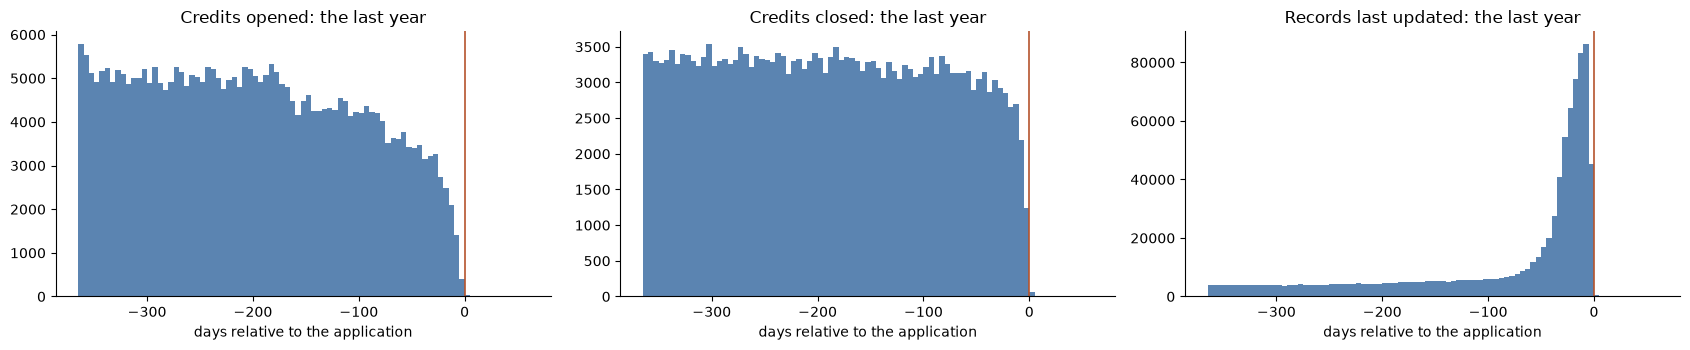

In [22]:
bc = bureau_clean
snapshot = pd.Series({
    'credits opened after the application (DAYS_CREDIT above 0)': int((bc['DAYS_CREDIT'] > 0).sum()),
    'credits closed after the application (DAYS_ENDDATE_FACT above 0)': int((bc['DAYS_ENDDATE_FACT'] > 0).sum()),
    'credits opened on the application day': int((bc['DAYS_CREDIT'] == 0).sum()),
    'credits closed on the application day': int((bc['DAYS_ENDDATE_FACT'] == 0).sum()),
    'records updated on the application day': int((bc['DAYS_CREDIT_UPDATE'] == 0).sum()),
    'records updated after the application (DAYS_CREDIT_UPDATE above 0)': int((bc['DAYS_CREDIT_UPDATE'] > 0).sum()),
})
print(snapshot.to_string())

# Are the last weeks before the application as busy as earlier weeks? A file pulled later would show no thinning; a reporting delay would.
weeks = pd.DataFrame({
    'credits opened': (-bc['DAYS_CREDIT']).floordiv(7).value_counts().sort_index().head(16),
    'credits closed': (-bc['DAYS_ENDDATE_FACT']).dropna().floordiv(7).value_counts().sort_index().head(16),
    'records updated': (-bc.loc[bc['DAYS_CREDIT_UPDATE'] <= 0, 'DAYS_CREDIT_UPDATE']).floordiv(7).value_counts().sort_index().head(16),
})
weeks.index = [f'{int(w) * 7} to {int(w) * 7 + 6} days before' for w in weeks.index]
print('\nevents per week, counting back from the application:')
print(weeks.to_string())
typical = weeks.iloc[8:16].mean()
print('\nthe most recent week as a share of a typical week two to four months earlier:')
print((weeks.iloc[0] / typical * 100).round(0).astype(int).astype(str).add('%').to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
for ax, (label, column) in zip(axes, {'Credits opened': 'DAYS_CREDIT', 'Credits closed': 'DAYS_ENDDATE_FACT', 'Records last updated': 'DAYS_CREDIT_UPDATE'}.items()):
    values = bc[column].dropna()
    ax.hist(values[(values >= -365) & (values <= 60)], bins=np.arange(-365, 62, 5), color='#5b84b1')
    ax.axvline(0, color='#b5542d', linewidth=1.2); ax.set_title(f'{label}: the last year'); ax.set_xlabel('days relative to the application')
sns.despine(); plt.tight_layout(); plt.show()

### 4.2 Rows updated after the application

A handful of rows have a positive `DAYS_CREDIT_UPDATE`. For those, the "current" columns may describe the credit as it stood after the applicant applied.

In [23]:
late = bc['DAYS_CREDIT_UPDATE'] > 0
print(f"rows updated after the application: {int(late.sum())}, from {bc.loc[late, 'SK_ID_CURR'].nunique()} applicants")
print(f"by part: {clean_part[late].value_counts().to_dict()}")
print(f"days after the application: {sorted(bc.loc[late, 'DAYS_CREDIT_UPDATE'].astype(int).tolist())}")
print(f"status: {bc.loc[late, 'STATUS'].value_counts().to_dict()}; type: {bc.loc[late, 'TYPE'].value_counts().to_dict()}")
print(f"applicants who would be left with no credit if these rows were removed: "
      f"{int((bc.loc[late].groupby('SK_ID_CURR').size() == bc[bc['SK_ID_CURR'].isin(bc.loc[late, 'SK_ID_CURR'])].groupby('SK_ID_CURR').size()).sum())}")
print()
print(bc.loc[late, ['SK_ID_CURR', 'STATUS', 'TYPE', 'DAYS_CREDIT', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'DAYS_CREDIT_UPDATE', 'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT',
                    'CREDIT_DAY_OVERDUE']].sort_values('DAYS_CREDIT_UPDATE', ascending=False).head(8).to_string(index=False))

rows updated after the application: 17, from 17 applicants
by part: {'train: development': 15, 'train: holdout': 2}
days after the application: [10, 11, 12, 13, 13, 13, 13, 14, 15, 16, 19, 20, 20, 22, 23, 23, 372]
status: {'Active': 17}; type: {'Car loan': 16, 'Mortgage': 1}
applicants who would be left with no credit if these rows were removed: 1

 SK_ID_CURR STATUS     TYPE  DAYS_CREDIT  DAYS_CREDIT_ENDDATE  DAYS_ENDDATE_FACT  DAYS_CREDIT_UPDATE  AMT_CREDIT_SUM  AMT_CREDIT_SUM_DEBT  CREDIT_DAY_OVERDUE
     438963 Active Mortgage        -2555               4005.0                NaN               372.0       7470000.0           7456589.55                   0
     392821 Active Car loan         -293                803.0                NaN                23.0       1546794.0           1212030.00                   0
     271171 Active Car loan         -419               1042.0                NaN                23.0       2206138.5           1767573.00                   0
     315469 Activ

### 4.3 How old is "current"?

`DAYS_CREDIT_UPDATE` says when the bureau last heard about a credit. For a closed credit an old update is fine: nothing has changed since. For an active credit it matters. If the last update was two years ago, "current debt" is the debt of two years ago, and the credit may since have been repaid or gone bad without the bureau being told.

In [24]:
age = -bc['DAYS_CREDIT_UPDATE']
bands = pd.cut(age, [-1, 7, 30, 90, 365, 730, 3000], labels=['0 to 7 days', '8 to 30', '31 to 90', '91 to 365', '1 to 2 years', 'over 2 years'])
is_active, is_closed = bc['STATUS'] == 'Active', bc['STATUS'] == 'Closed'
fresh = pd.DataFrame({
    'active credits (%)': bands[is_active].value_counts(normalize=True).sort_index() * 100,
    'closed credits (%)': bands[is_closed].value_counts(normalize=True).sort_index() * 100,
    'active: debt above zero (%)': (bc['AMT_CREDIT_SUM_DEBT'] > 0)[is_active].groupby(bands[is_active], observed=True).mean() * 100,
    'active: debt missing (%)': bc['AMT_CREDIT_SUM_DEBT'].isna()[is_active].groupby(bands[is_active], observed=True).mean() * 100,
    'active: planned end already passed (%)': (bc['DAYS_CREDIT_ENDDATE'] < 0)[is_active].groupby(bands[is_active], observed=True).mean() * 100,
    'active: credit card (%)': (bc['TYPE'] == 'Credit card')[is_active].groupby(bands[is_active], observed=True).mean() * 100,
})
print('time since the bureau record was last updated:')
print(fresh.round(1).to_string())
print(f"\nactive credits: median {age[is_active].median():.0f} days since the last update; not updated for over a year: {(age[is_active] > 365).mean():.1%}")
stale_done = is_active & (age > 365) & (bc['DAYS_CREDIT_ENDDATE'] < -365)
print(f"active, not updated for over a year, and planned end more than a year ago: {int(stale_done.sum()):,} rows ({stale_done[is_active].mean():.1%} of active credits)")

# closed credits: when was the record updated relative to the closing date?
lag = (bc['DAYS_CREDIT_UPDATE'] - bc['DAYS_ENDDATE_FACT'])[is_closed].dropna()
print(f"\nclosed credits, days from closing to the last update: median {lag.median():.0f}; updated on the closing day {(lag == 0).mean():.1%}; "
      f"within 30 days {lag.between(0, 30).mean():.1%}; update dated before the closing {(lag < 0).mean():.1%} ({int((lag < 0).sum()):,} rows)")

# the same between train and test (no target)
by_part = pd.DataFrame({label: {'active: median days since update': age[is_active & (clean_part == label)].median(),
                                'active: not updated for over a year (%)': (age[is_active & (clean_part == label)] > 365).mean() * 100,
                                'closed: median days since update': age[is_closed & (clean_part == label)].median(),
                                'applicants whose most recent update is within 30 days (%)': (age[clean_part == label].groupby(bc.loc[clean_part == label, 'SK_ID_CURR']).min() <= 30).mean() * 100}
                        for label in PARTS}).T
print('\nby part of the data:')
print(by_part.round(1).to_string())

overdue_longer = bc['CREDIT_DAY_OVERDUE'] > -bc['DAYS_CREDIT']
print(f"\ncredits overdue for longer than they have existed: {int(overdue_longer.sum())}")

time since the bureau record was last updated:
                    active credits (%)  closed credits (%)  active: debt above zero (%)  active: debt missing (%)  active: planned end already passed (%)  active: credit card (%)
DAYS_CREDIT_UPDATE                                                                                                                                                                
0 to 7 days                       11.7                 0.7                         75.8                      15.2                                     4.1                     39.3
8 to 30                           48.5                 2.1                         78.3                      10.7                                     3.5                     39.0
31 to 90                          20.3                 4.5                         70.0                      10.2                                     8.9                     43.5
91 to 365                          7.0                18.9


closed credits, days from closing to the last update: median 4; updated on the closing day 28.7%; within 30 days 70.2%; update dated before the closing 0.2% (2,206 rows)



by part of the data:
                    active: median days since update  active: not updated for over a year (%)  closed: median days since update  applicants whose most recent update is within 30 days (%)
train: development                              24.0                                     13.5                             734.0                                                       65.8
train: holdout                                  24.0                                     13.5                             735.0                                                       66.2
test                                            24.0                                      7.0                             719.0                                                       69.4

credits overdue for longer than they have existed: 2


### 4.4 The eight-year window

Stage 1 found that no credit was opened more than eight years before the application. This section checks whether that is a hard cut-off and what it removes.

In [25]:
years_back = -bc['DAYS_CREDIT'] / 365.25
by_year = pd.DataFrame({'credits opened': pd.cut(years_back, np.arange(0, 9), right=False).value_counts().sort_index(),
                        'still active (%)': is_active.groupby(pd.cut(years_back, np.arange(0, 9), right=False), observed=True).mean() * 100,
                        'closed, median years open': ((bc['DAYS_ENDDATE_FACT'] - bc['DAYS_CREDIT']) / 365.25)[is_closed].groupby(pd.cut(years_back[is_closed], np.arange(0, 9), right=False), observed=True).median()})
by_year.index = [f'{int(i.left)} to {int(i.right)} years before' for i in by_year.index]
print(by_year.round(2).to_string())
last_month = int((bc['DAYS_CREDIT'] <= -2892).sum())
print(f"\ncredits opened in the final 30 days of the window (2,892 to 2,922 days before): {last_month:,}; in the 30 days before that: {int(bc['DAYS_CREDIT'].between(-2891, -2862).sum()):,}")
print(f"earliest closing date: {int(-bc['DAYS_ENDDATE_FACT'].min()):,} days before; earliest update: {int(-bc['DAYS_CREDIT_UPDATE'].min()):,} days before")

first = -bc.groupby('SK_ID_CURR')['DAYS_CREDIT'].min() / 365.25
print(f"\napplicants whose oldest credit is 7 to 8 years old: {(first >= 7).mean():.1%} of applicants with a record. For them the true length of credit history is unknown.")
print(f"by part: { {label: round(float((first.reindex(ids).dropna() >= 7).mean() * 100), 1) for label, ids in {'train: development': DEV_IDS, 'train: holdout': HOLDOUT_IDS, 'test': TEST_IDS}.items()} }")

                     credits opened  still active (%)  closed, median years open
0 to 1 years before          323791             77.97                       0.25
1 to 2 years before          333175             49.74                       0.58
2 to 3 years before          279071             32.75                       0.76
3 to 4 years before          239612             23.32                       0.85
4 to 5 years before          176830             15.59                       0.93
5 to 6 years before          102377              9.20                       0.96
6 to 7 years before          132706              9.70                       1.00
7 to 8 years before          126529             10.85                       0.92

credits opened in the final 30 days of the window (2,892 to 2,922 days before): 9,530; in the 30 days before that: 9,435
earliest closing date: 2,922 days before; earliest update: 2,917 days before



applicants whose oldest credit is 7 to 8 years old: 26.6% of applicants with a record. For them the true length of credit history is unknown.
by part: {'train: development': 26.7, 'train: holdout': 26.4, 'test': 26.6}


### 4.5 A leak screen

If any bureau column carried information from after the application, some simple summary of it would predict default far better than honest history can. This section computes a broad set of crude per-applicant summaries (the largest, smallest, mean and most recent value of every numeric column, and the share of credits in each status and type) and scores each one alone against the outcome.

For scale: the best single feature in the application table was `EXT_MEAN`, at 0.716. That is a purpose-built credit score. A raw bureau column approaching it would need explaining.

Development applicants only. Nothing is fitted: each summary is used as a score exactly as it is.

In [26]:
dev_rows = bc[bc['SK_ID_CURR'].isin(DEV_IDS)]
numeric_cols = ['DAYS_CREDIT', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'DAYS_CREDIT_UPDATE', 'CREDIT_DAY_OVERDUE', 'CNT_CREDIT_PROLONG',
                'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_OVERDUE', 'AMT_CREDIT_MAX_OVERDUE']
grouped = dev_rows.groupby('SK_ID_CURR')
crude = grouped[numeric_cols].agg(['min', 'max', 'mean'])
crude.columns = [f'{c}: {how}' for c, how in crude.columns]
latest = dev_rows.sort_values('DAYS_CREDIT').groupby('SK_ID_CURR')[numeric_cols].last()          # the most recently opened credit
crude = crude.join(latest.add_suffix(': most recent credit'))
for column, values in {'STATUS': ['Active', 'Closed', 'Sold or bad debt'], 'TYPE': MAIN_TYPES + ['Other']}.items():
    for v in values:
        crude[f'share of credits: {v}'] = (dev_rows[column] == v).groupby(dev_rows['SK_ID_CURR']).mean()
crude['number of credits'] = grouped.size()

y_rec = y_dev.reindex(crude.index)
screen = {}
for c in crude.columns:
    ok = crude[c].notna()
    if ok.sum() < 1000 or crude.loc[ok, c].nunique() < 2:
        continue
    auc = roc_auc_score(y_rec[ok], crude.loc[ok, c])
    screen[c] = {'auc': max(auc, 1 - auc), 'higher_value_means': 'more risk' if auc > 0.5 else 'less risk', 'applicants': int(ok.sum())}
screen = pd.DataFrame(screen).T.sort_values('auc', ascending=False)
print(f"development applicants with a bureau record: {len(crude):,}; summaries screened: {len(screen)}")
print(f"highest AUC of any single summary: {screen['auc'].max():.4f}; summaries above 0.60: {int((screen['auc'] > 0.60).sum())}; above 0.65: {int((screen['auc'] > 0.65).sum())}")
print('\nthe fifteen strongest:')
print(screen.head(15).to_string())

# the "current" columns, which are the ones a look-ahead would inflate
current = ['CREDIT_DAY_OVERDUE: max', 'AMT_CREDIT_SUM_OVERDUE: max', 'AMT_CREDIT_SUM_DEBT: max', 'share of credits: Sold or bad debt', 'DAYS_CREDIT_UPDATE: max']
print('\nthe summaries of "current" state:')
print(screen.loc[current].to_string())
overdue_now = (crude['CREDIT_DAY_OVERDUE: max'] > 0)
print(f"\napplicants with a credit overdue at the application: {int(overdue_now.sum()):,} ({overdue_now.mean():.2%}); default rate {y_rec[overdue_now].mean():.1%} against {y_rec[~overdue_now].mean():.1%} for the rest")

development applicants with a bureau record: 210,764; summaries screened: 54
highest AUC of any single summary: 0.6106; summaries above 0.60: 5; above 0.65: 0

the fifteen strongest:
                                               auc higher_value_means applicants
AMT_CREDIT_SUM_LIMIT: most recent credit  0.610584          less risk      38859
AMT_CREDIT_SUM_LIMIT: mean                0.610318          less risk      38859
AMT_CREDIT_SUM_LIMIT: min                 0.605333          less risk      38859
AMT_CREDIT_SUM_LIMIT: max                 0.603313          less risk      38859
DAYS_CREDIT: mean                         0.601418          more risk     210764
DAYS_CREDIT_UPDATE: mean                  0.587521          more risk     210763
share of credits: Closed                   0.58547          less risk     210764
share of credits: Active                  0.583413          more risk     210764
DAYS_CREDIT: most recent credit           0.581509          more risk     210764
DAYS_CR

### 4.6 The time rule, and the final preparation function

One rule is added to the nine from stage 3.

| # | Rule | Why |
|---|---|---|
| 10 | Where a record was updated after the application, every column that describes the credit's state at the last update becomes missing: the update date, debt, credit limit, amount overdue, largest amount overdue, days overdue and prolongations. The credit itself, its opening date, planned end, type and status are kept | Those values may describe the credit as it stood after the applicant applied. The opening date and the plan were fixed before. The status is safe because all of these credits are `Active`: a credit opened before the application and still open after it was open on the day |

The rows are kept, not removed, because removing them would leave one applicant with no bureau record at all, which would misdescribe that applicant.

`prepare_bureau` applies all ten rules. It is the only function later stages use.


In [27]:

STATE_AT_LAST_UPDATE = ['DAYS_CREDIT_UPDATE', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_OVERDUE', 'AMT_CREDIT_MAX_OVERDUE', 'CREDIT_DAY_OVERDUE', 'CNT_CREDIT_PROLONG']

def prepare_bureau(raw, report=None):
    # rules 1 to 9 (section 3.8), then rule 10: nothing recorded after the application is used
    df = clean_bureau(raw, report)
    after_application = df['DAYS_CREDIT_UPDATE'] > 0
    assert (df.loc[after_application, 'STATUS'] == 'Active').all(), 'rule 10 keeps the status only because these credits are all active'
    for c in STATE_AT_LAST_UPDATE:
        df[c] = df[c].astype(float).where(~after_application)
    if report is not None:
        report['10. rows updated after the application, state columns set to missing'] = int(after_application.sum())
    return df

final_report = {}
bureau_ready = prepare_bureau(bureau, final_report)
print(pd.Series(final_report, name='rows').to_string())

ready_part = bureau_ready['SK_ID_CURR'].map(part_of)
time_checks = {
    'no credit opened after the application': not (bureau_ready['DAYS_CREDIT'] > 0).any(),
    'no credit closed after the application': not (bureau_ready['DAYS_ENDDATE_FACT'] > 0).any(),
    'no record updated after the application': not (bureau_ready['DAYS_CREDIT_UPDATE'] > 0).any(),
    'the 17 rows are still there': len(bureau_ready) == len(bureau_clean),
    'no applicant lost every credit': bureau_ready['SK_ID_CURR'].nunique() == bureau['SK_ID_CURR'].nunique(),
    'nothing else changed': bureau_ready.loc[~late.values].astype({c: float for c in STATE_AT_LAST_UPDATE}).equals(bureau_clean.loc[~late.values].astype({c: float for c in STATE_AT_LAST_UPDATE})),
    'row order in the file does not matter': prepare_bureau(bureau.sample(frac=1, random_state=SEED)).equals(bureau_ready),
    'preparing the test rows alone gives the same result': prepare_bureau(bureau[bureau_part == 'test']).sort_values('SK_ID_BUREAU').reset_index(drop=True).equals(
        bureau_ready[ready_part == 'test'].sort_values('SK_ID_BUREAU').reset_index(drop=True)),
}
print()
for name, ok in time_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(time_checks.values())
print(f"\nprepared table: {bureau_ready.shape[0]:,} rows, {bureau_ready.shape[1]} columns, {bureau_ready['SK_ID_CURR'].nunique():,} applicants")
print(bureau_ready.dtypes.astype(str).to_string())


1. repeated rows removed                                                   2059
2. rows with status grouped as Sold or bad debt                            6545
3. rows with type grouped as Other                                         4120
4. rows in another currency, amounts set to missing                        1408
5. AMT_ANNUITY values dropped                                            489417
6. planned end more than 30 years ahead, set to missing                   42661
7. DAYS_CREDIT_ENDDATE before the credit was opened, set to missing         164
7. DAYS_ENDDATE_FACT before the credit was opened, set to missing            20
7. DAYS_CREDIT_UPDATE before the credit was opened, set to missing          135
8. negative debt set to zero                                               8337
9. credit limit of zero or below, set to missing                        1048691
10. rows updated after the application, state columns set to missing         17



PASS  no credit opened after the application
PASS  no credit closed after the application
PASS  no record updated after the application
PASS  the 17 rows are still there
PASS  no applicant lost every credit
PASS  nothing else changed
PASS  row order in the file does not matter
PASS  preparing the test rows alone gives the same result

prepared table: 1,714,369 rows, 15 columns, 305,811 applicants
SK_ID_CURR                  int64
SK_ID_BUREAU                int64
DAYS_CREDIT                 int64
CREDIT_DAY_OVERDUE        float64
DAYS_CREDIT_ENDDATE       float64
DAYS_ENDDATE_FACT         float64
AMT_CREDIT_MAX_OVERDUE    float64
CNT_CREDIT_PROLONG        float64
AMT_CREDIT_SUM            float64
AMT_CREDIT_SUM_DEBT       float64
AMT_CREDIT_SUM_LIMIT      float64
AMT_CREDIT_SUM_OVERDUE    float64
DAYS_CREDIT_UPDATE        float64
STATUS                        str
TYPE                          str


### Stage 4 findings

**The bureau file is a snapshot taken at the application date. No leak was found.**
- No credit was opened after the application and none was closed after it. Both dates stop exactly at zero.
- The last weeks before the application are thinner than earlier weeks, not fuller. Credits opened in the final week are 11% of a typical week three months earlier, and closures are 37%. That is a reporting delay: a new credit takes a few weeks to reach the bureau. A file pulled months after the application would show no such thinning, because the delay would have been made up.
- So the model will see slightly less than the truth about an applicant's most recent borrowing. That is a limit on the data, in the safe direction: it understates recent activity, and it does so in the same way when the model is used.

**17 rows were updated after the application**
- They were updated 10 to 23 days after it, and one 372 days after. All are active credits, 16 of them car loans, and all are in train (15 development, 2 holdout).
- For these rows the debt and overdue columns may describe a later date. Rule 10 sets those columns to missing and keeps the credit, its opening date, its planned end and its status.
- The rows are kept because removing them would leave one applicant with no bureau record.
- Seventeen rows cannot move a model. The rule is there so that the statement "nothing recorded after the application is used" is true without exception.

**"Current" is recent for most active credits, but not all**

| Time since the last update | Share of active credits | Of those, with debt above zero | Planned end already passed |
|---|---:|---:|---:|
| Up to 30 days | 60% | about 78% | about 4% |
| 31 to 90 days | 20% | 70% | 9% |
| 91 days to a year | 7% | 50% | 23% |
| Over a year | 12.6% | 24% to 31% | 46% to 62% |

- The median active credit was updated 24 days before the application, so for most of them "current debt" really is current.
- 12.6% of active credits have not been updated for over a year. Most of those have passed their planned end and show no debt. They are very probably closed credits that nobody reported as closed. 32,311 rows (5.1% of active credits) are both stale by more than a year and more than a year past their planned end.
- **This also differs between train and test:** 13.5% of active credits in train are stale by over a year, against 7.0% in test. This is consistent with stage 3, which found more "active, planned end passed" credits in train (12.6% against 9.1%).
- The consequence for stage 6: a plain count of active credits mixes live obligations with stale records, in different proportions in the two files. Features about active credits should be built on credits updated within the last year, with the stale ones counted separately.
- Closed credits behave as expected: 70% were last updated within 30 days of closing, and nothing changes afterwards.

**The eight-year window is a hard cut-off**
- As many credits were opened in the last 30 days of the window as in the 30 days before, so the history does not taper. It is cut.
- For 26.6% of applicants with a record, the oldest credit is 7 to 8 years old. Their true length of credit history is unknown: it could be 8 years or 30. The share is the same in train and test.
- "Age of oldest credit" is therefore capped, and stage 6 should pair it with a yes-or-no feature for "reaches the edge of the window".

**The leak screen is clean**
- 54 crude summaries per applicant were scored alone against default, on the 210,764 development applicants with a record.
- The strongest is 0.611, and none exceeds 0.65. For comparison, `EXT_MEAN` scores 0.716. Nothing in `bureau` predicts default implausibly well.
- The strongest signals are ordinary ones: the size of credit card limits (0.61, available for only 18% of applicants), how recently credits were opened (0.60), and the share of credits that are closed (0.585).
- The "current state" columns, the ones a look-ahead would inflate, are weak as crude summaries (0.507 for days overdue) because being overdue is rare. Where it occurs it matters: the 1.3% of applicants with a credit overdue at the application default at 15.5%, against 7.6% for the rest. That is a large but believable difference for people already behind on another loan.

**Leakage check for this stage**
- Sections 4.1 to 4.4 used no target.
- Section 4.5 used development outcomes only. Nothing was fitted or selected: each summary was scored as it is, and the only use made of the scores is to confirm that none is suspicious.
- Rule 10 is a fixed statement about a row and uses no target.

**The preparation function**
- `prepare_bureau` applies all ten rules and returns 1,714,369 rows and 15 columns for 305,811 applicants. All eight checks pass, including that preparing the test rows alone gives the same result.

**Decisions**
- The table is safe to build features from: every remaining value was recorded on or before the application date.
- Carried to stage 6: split active credits into live (updated within a year) and stale; add a feature for history that reaches the edge of the eight-year window; do not read much into the last few weeks before the application.
- Carried to stage 8: the share of stale active credits differs between train and test, so features that depend on it are screened for shift.


## Stage 5: Row-level signal

Which bureau columns relate to default, and in what shape?

A credit does not default on a Home Credit loan. An applicant does. So each credit is given the outcome of the applicant who holds it, and the question becomes: do applicants holding credits of this kind default more often?

**Two cautions about reading this stage**

- **Rows are not independent.** An applicant with 20 credits appears 20 times with the same outcome. If rows were counted equally, the result would describe heavy borrowers, not applicants. So every rate here is weighted so that each applicant counts once in total: a credit from an applicant with *n* credits has weight 1/*n*.
- **This is description, not selection.** No feature is chosen here by its score. The stage shows which columns carry signal and what shape it has, so that stage 6 builds sensible summaries. The candidates are screened later, and tested properly inside cross-validation in notebook 04.

Only the 210,764 development applicants with a bureau record are used.

| Section | Question |
|---|---|
| 5.1 | Set-up and the weighting |
| 5.2 | Status and type |
| 5.3 | Each numeric column, on its own |
| 5.4 | Columns that are mostly zero or blank: does blank mean zero? |
| 5.5 | Quantities built from two columns of the same credit |
| 5.6 | Does a credit's age change what it says? |
| 5.7 | Is any of this new, or do the external scores already hold it? |

### 5.1 Set-up

In [28]:
rows = bureau_ready[bureau_ready['SK_ID_CURR'].isin(DEV_IDS)].copy()
rows['y'] = rows['SK_ID_CURR'].map(y_dev).astype(int)
rows['w'] = 1 / rows.groupby('SK_ID_CURR')['SK_ID_CURR'].transform('size')
assert len(rows['SK_ID_CURR'].unique()) == int(round(rows['w'].sum())) == 210764
assert not rows['SK_ID_CURR'].isin(HOLDOUT_IDS).any() and not rows['SK_ID_CURR'].isin(TEST_IDS).any()

RECORD_RATE = float((rows['y'] * rows['w']).sum() / rows['w'].sum())
print(f"development credits: {len(rows):,} from {rows['SK_ID_CURR'].nunique():,} applicants")
print(f"default rate, each applicant counted once: {RECORD_RATE:.2%}")
print(f"default rate, each credit counted once:    {rows['y'].mean():.2%}  (heavy borrowers count more; not used)")

def weighted_rate(groups, frame=None, order=None, min_weight=200):
    # default rate per group with each applicant counting once in total. 'applicant_equivalents' is the sum of weights:
    # the number of whole applicants the group amounts to. The interval treats that as the sample size, so it is approximate.
    frame = rows if frame is None else frame
    g = pd.DataFrame({'group': np.asarray(groups), 'y': frame['y'].values, 'w': frame['w'].values, 'id': frame['SK_ID_CURR'].values})
    out = g.groupby('group', observed=True).apply(lambda d: pd.Series({
        'credits': len(d), 'applicants': d['id'].nunique(), 'applicant_equivalents': d['w'].sum(),
        'default_pct': (d['y'] * d['w']).sum() / d['w'].sum() * 100}), include_groups=False)
    se = np.sqrt(out['default_pct'] / 100 * (1 - out['default_pct'] / 100) / out['applicant_equivalents']) * 100
    out['low_pct'], out['high_pct'] = out['default_pct'] - 1.96 * se, out['default_pct'] + 1.96 * se
    out['ratio_to_overall'] = out['default_pct'] / (RECORD_RATE * 100)
    out['share_of_weight_pct'] = out['applicant_equivalents'] / out['applicant_equivalents'].sum() * 100
    out = out[out['applicant_equivalents'] >= min_weight]
    return out if order is None else out.reindex([o for o in order if o in out.index])

def weighted_auc(values, frame=None):
    frame = rows if frame is None else frame
    ok = pd.notna(values)
    auc = roc_auc_score(frame['y'].values[ok], np.asarray(values, dtype=float)[ok], sample_weight=frame['w'].values[ok])
    return max(auc, 1 - auc), ('more risk' if auc > 0.5 else 'less risk')

SHOW = ['credits', 'applicants', 'share_of_weight_pct', 'default_pct', 'low_pct', 'high_pct', 'ratio_to_overall']

development credits: 1,170,024 from 210,764 applicants
default rate, each applicant counted once: 7.73%
default rate, each credit counted once:    7.83%  (heavy borrowers count more; not used)


### 5.2 Status and type

In [29]:
print('by status:')
print(weighted_rate(rows['STATUS'], order=['Closed', 'Active', 'Sold or bad debt'])[SHOW].round(2).to_string())
print('\nby type:')
print(weighted_rate(rows['TYPE']).sort_values('default_pct')[SHOW].round(2).to_string())
print('\nby status and type:')
both = weighted_rate(rows['STATUS'] + ' | ' + rows['TYPE'], min_weight=300).sort_values('default_pct')
print(both[SHOW].round(2).to_string())

# the same at applicant level: does holding at least one credit of a kind matter?
flags = pd.DataFrame({f'has a {v.lower()} credit': (rows['STATUS'] == v).groupby(rows['SK_ID_CURR']).any() for v in ['Sold or bad debt']} |
                     {f'has a {v.lower()}': (rows['TYPE'] == v).groupby(rows['SK_ID_CURR']).any() for v in ['Credit card', 'Car loan', 'Mortgage', 'Microloan']} |
                     {'has an active microloan': ((rows['TYPE'] == 'Microloan') & (rows['STATUS'] == 'Active')).groupby(rows['SK_ID_CURR']).any()})
y_flags = y_dev.reindex(flags.index)
applicant_level = pd.DataFrame({c: {'applicants_with': int(flags[c].sum()), 'pct_of_applicants': flags[c].mean() * 100, 'default_pct_with': y_flags[flags[c]].mean() * 100,
                                    'default_pct_without': y_flags[~flags[c]].mean() * 100} for c in flags.columns}).T
applicant_level['difference'] = applicant_level['default_pct_with'] - applicant_level['default_pct_without']
applicant_level['z'] = applicant_level['difference'] / (np.sqrt(applicant_level['default_pct_with'] / 100 * (1 - applicant_level['default_pct_with'] / 100) / applicant_level['applicants_with']
                                                                + RECORD_RATE * (1 - RECORD_RATE) / (len(flags) - applicant_level['applicants_with'])) * 100)
print('\napplicants holding at least one credit of a kind:')
print(applicant_level.round(2).to_string())

by status:


                   credits  applicants  share_of_weight_pct  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                        
Closed            732929.0    184165.0                58.30         6.62     6.48      6.76              0.86
Active            432548.0    173730.0                41.30         9.26     9.07      9.45              1.20
Sold or bad debt    4547.0      4195.0                 0.39        11.79     9.59     13.98              1.52

by type:


                  credits  applicants  share_of_weight_pct  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                       
Mortgage          12497.0     11451.0                 1.43         4.54     3.80      5.29              0.59
Car loan          18942.0     15662.0                 2.00         5.24     4.57      5.92              0.68
Other              2768.0      2363.0                 0.25         6.54     4.42      8.65              0.85
Consumer credit  854730.0    197432.0                71.94         7.47     7.34      7.60              0.97
Credit card      273942.0    137773.0                23.97         8.70     8.46      8.95              1.13
Microloan          7145.0      2796.0                 0.42        20.39    17.73     23.04              2.64

by status and type:


                                     credits  applicants  share_of_weight_pct  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                                          
Closed | Mortgage                     3341.0      3108.0                 0.35         3.75     2.38      5.13              0.49
Closed | Car loan                    11861.0     10277.0                 1.18         4.50     3.69      5.32              0.58
Active | Mortgage                     8727.0      8363.0                 1.03         4.71     3.82      5.60              0.61
Active | Car loan                     6758.0      6527.0                 0.78         6.26     5.09      7.43              0.81
Closed | Other                        2120.0      1829.0                 0.19         6.33     3.93      8.73              0.82
Closed | Credit card                 76312.0     53218.0                 5.62         6.45     6.01     


applicants holding at least one credit of a kind:
                               applicants_with  pct_of_applicants  default_pct_with  default_pct_without  difference      z
has a sold or bad debt credit           4195.0               1.99             10.23                 7.68        2.55   5.40
has a credit card                     137773.0              65.37              8.13                 6.97        1.16   9.41
has a car loan                         15662.0               7.43              5.83                 7.88       -2.05 -10.44
has a mortgage                         11451.0               5.43              5.21                 7.88       -2.66 -12.31
has a microloan                         2796.0               1.33             19.85                 7.57       12.28  16.23
has an active microloan                 1432.0               0.68             24.02                 7.62       16.40  14.51


### 5.3 Numeric columns

Each numeric column is cut into ten groups of equal weight, and the default rate is shown for each. The AUC is the column used alone as a score for the applicant who holds the credit. Dates are shown separately for active and closed credits where the meaning differs.

                                     credits_with_a_value   auc higher_value_means lowest_decile_pct highest_decile_pct min_pct max_pct         shape
DAYS_CREDIT (all)                                 1170024 0.575          more risk             5.660             12.024   5.660  12.024      monotone
DAYS_CREDIT (active)                               432548 0.567          more risk             6.382             12.774   6.382  12.774      monotone
DAYS_CREDIT (closed)                               732929 0.546          more risk             5.554              8.875   5.533   8.875  not monotone
DAYS_CREDIT_ENDDATE (active)                       360490 0.522          more risk             7.085              8.377   7.085  10.644  not monotone
DAYS_CREDIT_ENDDATE (closed)                       705387 0.531          more risk             5.504              6.999   5.504   7.755  not monotone
DAYS_ENDDATE_FACT (closed)                         732851 0.541          more risk             5.385

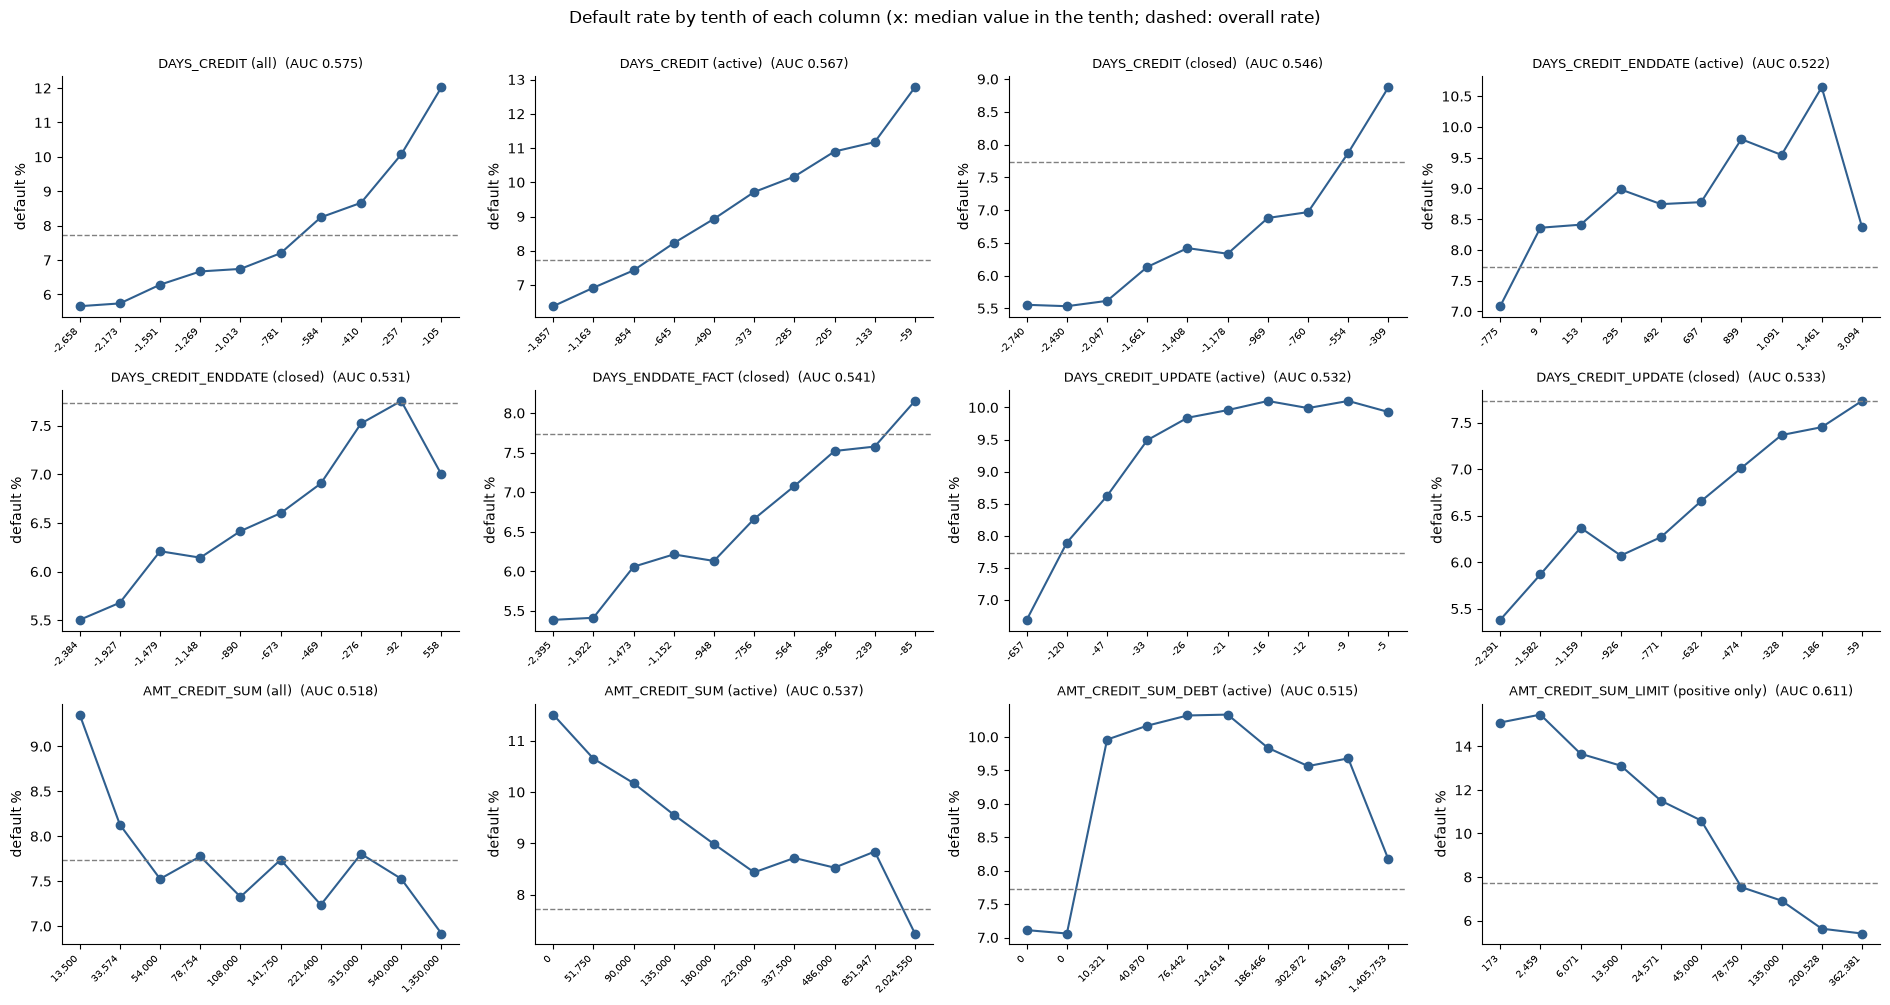

In [30]:
def decile_curve(values, frame, bins=10):
    ok = values.notna()
    v, f = values[ok], frame[ok]
    order = np.argsort(v.values, kind='stable')
    cum = np.cumsum(f['w'].values[order]) / f['w'].sum()
    group = np.minimum((cum * bins).astype(int), bins - 1)
    d = pd.DataFrame({'g': group, 'v': v.values[order], 'y': f['y'].values[order], 'w': f['w'].values[order]})
    return d.groupby('g').apply(lambda x: pd.Series({'median_value': x['v'].median(), 'default_pct': (x['y'] * x['w']).sum() / x['w'].sum() * 100}), include_groups=False)

act, clo = rows['STATUS'] == 'Active', rows['STATUS'] == 'Closed'
views = {
    'DAYS_CREDIT (all)': (rows['DAYS_CREDIT'], rows.index == rows.index),
    'DAYS_CREDIT (active)': (rows['DAYS_CREDIT'], act),
    'DAYS_CREDIT (closed)': (rows['DAYS_CREDIT'], clo),
    'DAYS_CREDIT_ENDDATE (active)': (rows['DAYS_CREDIT_ENDDATE'], act),
    'DAYS_CREDIT_ENDDATE (closed)': (rows['DAYS_CREDIT_ENDDATE'], clo),
    'DAYS_ENDDATE_FACT (closed)': (rows['DAYS_ENDDATE_FACT'], clo),
    'DAYS_CREDIT_UPDATE (active)': (rows['DAYS_CREDIT_UPDATE'], act),
    'DAYS_CREDIT_UPDATE (closed)': (rows['DAYS_CREDIT_UPDATE'], clo),
    'AMT_CREDIT_SUM (all)': (rows['AMT_CREDIT_SUM'], rows.index == rows.index),
    'AMT_CREDIT_SUM (active)': (rows['AMT_CREDIT_SUM'], act),
    'AMT_CREDIT_SUM_DEBT (active)': (rows['AMT_CREDIT_SUM_DEBT'], act),
    'AMT_CREDIT_SUM_LIMIT (positive only)': (rows['AMT_CREDIT_SUM_LIMIT'], rows['AMT_CREDIT_SUM_LIMIT'].notna()),
}
numeric_signal, curves = {}, {}
for label, (values, mask) in views.items():
    mask = np.asarray(mask)
    v, f = values[mask], rows[mask]
    auc, direction = weighted_auc(v, f)
    curves[label] = decile_curve(v, f)
    c = curves[label]['default_pct']
    steps = np.sign(np.diff(c.values))
    numeric_signal[label] = {'credits_with_a_value': int(v.notna().sum()), 'auc': auc, 'higher_value_means': direction, 'lowest_decile_pct': c.iloc[0], 'highest_decile_pct': c.iloc[-1],
                             'min_pct': c.min(), 'max_pct': c.max(), 'shape': 'monotone' if abs(steps.sum()) >= len(steps) - 1 else 'not monotone'}
numeric_signal = pd.DataFrame(numeric_signal).T
print(numeric_signal.to_string(float_format=lambda v: f'{v:,.3f}'))

fig, axes = plt.subplots(3, 4, figsize=(19, 10))
for ax, (label, curve) in zip(axes.ravel(), curves.items()):
    ax.plot(range(len(curve)), curve['default_pct'], marker='o', color='#2f5f8f')
    ax.axhline(RECORD_RATE * 100, color='grey', linestyle='--', linewidth=1)
    ax.set_xticks(range(len(curve)))
    ax.set_xticklabels([f'{v:,.0f}' for v in curve['median_value']], rotation=45, ha='right', fontsize=7)
    ax.set_title(f"{label}  (AUC {numeric_signal.loc[label, 'auc']:.3f})", fontsize=9); ax.set_ylabel('default %')
fig.suptitle('Default rate by tenth of each column (x: median value in the tenth; dashed: overall rate)', y=1.0)
sns.despine(); plt.tight_layout(); plt.show()

### 5.4 Columns that are mostly zero or blank

Five columns are zero or blank for almost every credit, so a curve over tenths says nothing. What matters is whether the rare non-zero values mark out riskier applicants, and whether a blank means the same as a zero. Stage 3 left that last question open for `AMT_CREDIT_MAX_OVERDUE`.

In [31]:
def state(column, edges=None, labels=None):
    v = rows[column]
    out = pd.Series('blank', index=rows.index, dtype=object)
    out[v == 0] = 'zero'
    if edges is None:
        out[v > 0] = 'above zero'
    else:
        banded = pd.cut(v[v > 0], edges, labels=labels).astype(object)
        out[v > 0] = banded
    return out

sparse = {
    'AMT_CREDIT_MAX_OVERDUE': (state('AMT_CREDIT_MAX_OVERDUE', [0, 1000, 10000, 1e12], ['up to 1,000', '1,000 to 10,000', 'over 10,000']), ['blank', 'zero', 'up to 1,000', '1,000 to 10,000', 'over 10,000']),
    'AMT_CREDIT_SUM_OVERDUE': (state('AMT_CREDIT_SUM_OVERDUE'), ['blank', 'zero', 'above zero']),
    'CREDIT_DAY_OVERDUE': (state('CREDIT_DAY_OVERDUE', [0, 30, 90, 1e6], ['1 to 30 days', '31 to 90 days', 'over 90 days']), ['blank', 'zero', '1 to 30 days', '31 to 90 days', 'over 90 days']),
    'CNT_CREDIT_PROLONG': (state('CNT_CREDIT_PROLONG', [0, 1, 100], ['once', 'twice or more']), ['blank', 'zero', 'once', 'twice or more']),
    'AMT_CREDIT_SUM_DEBT, active credits': (state('AMT_CREDIT_SUM_DEBT')[act], ['blank', 'zero', 'above zero']),
    'AMT_CREDIT_SUM_DEBT, closed credits': (state('AMT_CREDIT_SUM_DEBT')[clo], ['blank', 'zero', 'above zero']),
    'AMT_CREDIT_SUM_LIMIT, credit cards': (state('AMT_CREDIT_SUM_LIMIT')[rows['TYPE'] == 'Credit card'], ['blank', 'above zero']),
    'DAYS_CREDIT_ENDDATE, active credits': (pd.Series(np.where(rows['DAYS_CREDIT_ENDDATE'].isna(), 'blank', np.where(rows['DAYS_CREDIT_ENDDATE'] < 0, 'already passed', 'in the future')), index=rows.index)[act],
                                            ['blank', 'already passed', 'in the future']),
}
for label, (groups, order) in sparse.items():
    print(f'\n{label}:')
    print(weighted_rate(groups, frame=rows.loc[groups.index], order=order, min_weight=50)[SHOW].round(2).to_string())

# blank against zero for the largest amount ever overdue, holding status fixed
mo = state('AMT_CREDIT_MAX_OVERDUE')
print('\nAMT_CREDIT_MAX_OVERDUE, default rate (%) by status:')
print(pd.DataFrame({s: weighted_rate(mo[rows['STATUS'] == s], frame=rows[rows['STATUS'] == s], order=['blank', 'zero', 'above zero'])['default_pct'] for s in ['Active', 'Closed']}).round(2).to_string())


AMT_CREDIT_MAX_OVERDUE:


                  credits  applicants  share_of_weight_pct  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                       
blank            757720.0    189415.0                65.08         7.54     7.40      7.68              0.98
zero             326990.0    132730.0                27.48         7.47     7.25      7.68              0.97
up to 1,000        9029.0      8621.0                 0.78         7.80     6.50      9.09              1.01
1,000 to 10,000   44513.0     34092.0                 3.78        10.78    10.10     11.46              1.39
over 10,000       31772.0     25100.0                 2.88        10.44     9.68     11.21              1.35

AMT_CREDIT_SUM_OVERDUE:


              credits  applicants  share_of_weight_pct  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                   
blank          1028.0       801.0                 0.09         4.75     1.65      7.85              0.61
zero        1166086.0    210618.0                99.62         7.71     7.59      7.82              1.00
above zero     2910.0      2664.0                 0.29        17.21    14.23     20.19              2.23

CREDIT_DAY_OVERDUE:


                 credits  applicants  share_of_weight_pct  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                      
zero           1167059.0    210648.0                99.70         7.70     7.59      7.82              1.00
1 to 30 days      1344.0      1251.0                 0.13        19.02    14.40     23.64              2.46
31 to 90 days      671.0       641.0                 0.07        17.62    11.53     23.70              2.28
over 90 days       935.0       881.0                 0.09        13.62     8.86     18.39              1.76

CNT_CREDIT_PROLONG:


                 credits  applicants  share_of_weight_pct  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                      
zero           1162942.0    210525.0                99.34         7.72     7.61      7.84              1.00
once              5922.0      5752.0                 0.55         8.88     7.24     10.52              1.15
twice or more     1145.0      1137.0                 0.11         7.26     3.89     10.64              0.94

AMT_CREDIT_SUM_DEBT, active credits:


             credits  applicants  share_of_weight_pct  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                  
blank        52347.0     37180.0                10.96         9.60      9.0     10.19              1.24
zero         89804.0     64253.0                19.22         6.98      6.6      7.37              0.90
above zero  290397.0    147105.0                69.81         9.84      9.6     10.07              1.27

AMT_CREDIT_SUM_DEBT, closed credits:


             credits  applicants  share_of_weight_pct  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                  
blank       124000.0     71077.0                16.87         6.05     5.72      6.37              0.78
zero        604425.0    174257.0                82.61         6.72     6.57      6.88              0.87
above zero    4504.0      4046.0                 0.52         8.36     6.21     10.52              1.08

AMT_CREDIT_SUM_LIMIT, credit cards:
             credits  applicants  share_of_weight_pct  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                  
blank       222398.0    125698.0                82.26         8.32     8.05      8.58              1.08
above zero   51544.0     38841.0                17.74        10.49     9.86     11.12              1.36

DAYS_CREDIT_ENDDATE, activ

                 credits  applicants  share_of_weight_pct  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                      
blank            72058.0     54780.0                15.87        11.32    10.79     11.85              1.46
already passed   54530.0     44390.0                11.63         7.35     6.85      7.86              0.95
in the future   305960.0    151831.0                72.50         9.12     8.89      9.34              1.18

AMT_CREDIT_MAX_OVERDUE, default rate (%) by status:


            Active  Closed
group                     
blank         8.83    6.60
zero          9.35    6.12
above zero   13.27    8.44


### 5.5 Quantities built from two columns of the same credit

Some of the most natural facts about a credit are not in any single column: how much of it is still owed, how long it was meant to run, whether it was repaid early or ran over. Each is computed here for one credit from its own row, and none uses anything but that row.

In [32]:
d = pd.DataFrame(index=rows.index)
d['share of the credit still owed (active, non-card)'] = (rows['AMT_CREDIT_SUM_DEBT'] / rows['AMT_CREDIT_SUM'].where(rows['AMT_CREDIT_SUM'] > 0)).where(act & (rows['TYPE'] != 'Credit card'))
d['debt as a share of the limit (cards with a limit)'] = (rows['AMT_CREDIT_SUM_DEBT'] / (rows['AMT_CREDIT_SUM_DEBT'] + rows['AMT_CREDIT_SUM_LIMIT'])).where(rows['AMT_CREDIT_SUM_LIMIT'].notna())
d['planned length in years'] = (rows['DAYS_CREDIT_ENDDATE'] - rows['DAYS_CREDIT']) / 365.25
d['actual length in years (closed)'] = ((rows['DAYS_ENDDATE_FACT'] - rows['DAYS_CREDIT']) / 365.25).where(clo)
d['closed early (+) or late (-), in days'] = (rows['DAYS_CREDIT_ENDDATE'] - rows['DAYS_ENDDATE_FACT']).where(clo)
d['share of the planned term used (closed)'] = ((rows['DAYS_ENDDATE_FACT'] - rows['DAYS_CREDIT']) / (rows['DAYS_CREDIT_ENDDATE'] - rows['DAYS_CREDIT']).where(lambda s: s > 0)).where(clo)
d['years of term remaining (active, end in the future)'] = (rows['DAYS_CREDIT_ENDDATE'] / 365.25).where(act & (rows['DAYS_CREDIT_ENDDATE'] > 0))
d['largest overdue as a share of the credit (where above zero)'] = (rows['AMT_CREDIT_MAX_OVERDUE'] / rows['AMT_CREDIT_SUM'].where(rows['AMT_CREDIT_SUM'] > 0)).where(rows['AMT_CREDIT_MAX_OVERDUE'] > 0)

derived_signal, derived_curves = {}, {}
for c in d.columns:
    ok = d[c].notna() & np.isfinite(d[c])
    auc, direction = weighted_auc(d.loc[ok, c], rows[ok])
    curve = decile_curve(d.loc[ok, c], rows[ok], bins=5)
    derived_curves[c] = curve
    derived_signal[c] = {'credits': int(ok.sum()), 'auc': auc, 'higher_value_means': direction, **{f'fifth_{i + 1}_pct': curve['default_pct'].iloc[i] for i in range(5)}}
derived_signal = pd.DataFrame(derived_signal).T
print('default rate by fifth of each quantity, lowest values first:')
print(derived_signal.to_string(float_format=lambda v: f'{v:,.2f}'))
print('\nmedian value in each fifth:')
print(pd.DataFrame({c: derived_curves[c]['median_value'].values for c in d.columns}, index=[f'fifth_{i + 1}' for i in range(5)]).T.round(2).to_string())

# three yes-or-no facts suggested by stages 3 and 4
age_update = -rows['DAYS_CREDIT_UPDATE']
kind = pd.Series(np.select([clo, act & (age_update <= 365), act & (age_update > 365)], ['closed', 'active, updated within a year', 'active, not updated for over a year'], 'sold or bad debt'), index=rows.index)
print('\nlive against stale active credits:')
print(weighted_rate(kind, order=['closed', 'active, updated within a year', 'active, not updated for over a year', 'sold or bad debt'])[SHOW].round(2).to_string())
timing = pd.Series(np.select([d['closed early (+) or late (-), in days'] > 30, d['closed early (+) or late (-), in days'] < -30, d['closed early (+) or late (-), in days'].notna()],
                             ['closed more than 30 days early', 'closed more than 30 days late', 'closed on time'], 'not applicable'), index=rows.index)
print('\nclosed credits by when they closed against the plan:')
print(weighted_rate(timing[clo], frame=rows[clo], order=['closed more than 30 days early', 'closed on time', 'closed more than 30 days late', 'not applicable'])[SHOW].round(2).to_string())
overrun = pd.Series(np.select([act & (rows['DAYS_CREDIT_ENDDATE'] < 0) & (rows['AMT_CREDIT_SUM_DEBT'] > 0), act & (rows['DAYS_CREDIT_ENDDATE'] < 0)],
                              ['past planned end, debt above zero', 'past planned end, no debt recorded'], 'other active'), index=rows.index)
print('\nactive credits past their planned end:')
print(weighted_rate(overrun[act], frame=rows[act], order=['other active', 'past planned end, no debt recorded', 'past planned end, debt above zero'])[SHOW].round(2).to_string())

default rate by fifth of each quantity, lowest values first:
                                                             credits  auc higher_value_means fifth_1_pct fifth_2_pct fifth_3_pct fifth_4_pct fifth_5_pct
share of the credit still owed (active, non-card)             201581 0.56          more risk        7.54        7.48        8.11       10.19       12.52
debt as a share of the limit (cards with a limit)              51508 0.61          more risk        7.65        6.87        8.52       13.24       16.21
planned length in years                                      1069962 0.51          more risk        7.48        6.70        7.42        7.87        7.87
actual length in years (closed)                               732851 0.52          less risk        7.53        6.64        6.22        6.67        6.03
closed early (+) or late (-), in days                         705309 0.51          less risk        6.90        6.74        6.76        6.00        6.47
share of the planned 


live against stale active credits:


                                      credits  applicants  share_of_weight_pct  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                                           
closed                               732929.0    184165.0                58.30         6.62     6.48      6.76              0.86
active, updated within a year        374281.0    165477.0                36.98         9.56     9.36      9.77              1.24
active, not updated for over a year   58222.0     39875.0                 4.32         6.68     6.17      7.19              0.86
sold or bad debt                       4592.0      4240.0                 0.40        11.83     9.64     14.02              1.53



closed credits by when they closed against the plan:


                                 credits  applicants  share_of_weight_pct  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                                      
closed more than 30 days early  232165.0    106889.0                30.24         6.30     6.05      6.55              0.81
closed on time                  416259.0    150900.0                57.84         6.62     6.44      6.80              0.86
closed more than 30 days late    56885.0     42305.0                 8.49         7.24     6.74      7.74              0.94
not applicable                   27620.0     21134.0                 3.44         7.88     7.07      8.69              1.02



active credits past their planned end:


                                     credits  applicants  share_of_weight_pct  default_pct  low_pct  high_pct  ratio_to_overall
group                                                                                                                          
other active                        378018.0    165154.0                88.37         9.51     9.31      9.72              1.23
past planned end, no debt recorded   32054.0     27792.0                 6.89         7.16     6.51      7.81              0.93
past planned end, debt above zero    22476.0     20291.0                 4.74         7.63     6.82      8.44              0.99


### 5.6 Does a credit's age change what it says?

A credit opened last month and one opened seven years ago are both "a credit". If recent credits say more about the applicant today, summaries should weight or separate them.

In [33]:
opened = pd.cut(-rows['DAYS_CREDIT'] / 365.25, [-0.01, 0.25, 0.5, 1, 2, 4, 8.01], labels=['last 3 months', '3 to 6 months', '6 to 12 months', '1 to 2 years', '2 to 4 years', '4 to 8 years'])
by_age = pd.DataFrame({'all credits': weighted_rate(opened)['default_pct'],
                       'active': weighted_rate(opened[act], frame=rows[act])['default_pct'],
                       'closed': weighted_rate(opened[clo], frame=rows[clo])['default_pct'],
                       'credit cards': weighted_rate(opened[rows['TYPE'] == 'Credit card'], frame=rows[rows['TYPE'] == 'Credit card'])['default_pct'],
                       'consumer credit': weighted_rate(opened[rows['TYPE'] == 'Consumer credit'], frame=rows[rows['TYPE'] == 'Consumer credit'])['default_pct'],
                       'credits': opened.value_counts()}).reindex(list(opened.cat.categories))
print('default rate (%) by when the credit was opened:')
print(by_age.round(2).to_string())

# at applicant level: how many credits were opened recently?
recent_counts = pd.DataFrame({f'opened in the last {label}': (rows['DAYS_CREDIT'] >= -days).groupby(rows['SK_ID_CURR']).sum() for label, days in {'3 months': 91, '6 months': 183, '12 months': 365, '24 months': 730}.items()})
y_r = y_dev.reindex(recent_counts.index)
print('\ndefault rate (%) by number of credits opened recently (applicants with a record):')
print(pd.DataFrame({c: y_r.groupby(recent_counts[c].clip(upper=4)).mean() * 100 for c in recent_counts.columns}).rename(index={4: '4 or more'}).round(2).to_string())
print('\neach count alone as a score:')
print(pd.Series({c: roc_auc_score(y_r, recent_counts[c]) for c in recent_counts.columns}).round(4).to_string())

# does an old overdue still matter?
had_overdue = rows['AMT_CREDIT_MAX_OVERDUE'] > 0
print('\ndefault rate (%) for credits that were ever overdue, by when the credit was opened:')
print(pd.DataFrame({'ever overdue': weighted_rate(opened[had_overdue], frame=rows[had_overdue])['default_pct'],
                    'never overdue, or blank': weighted_rate(opened[~had_overdue], frame=rows[~had_overdue])['default_pct'],
                    'ratio': weighted_rate(opened[had_overdue], frame=rows[had_overdue])['default_pct'] / weighted_rate(opened[~had_overdue], frame=rows[~had_overdue])['default_pct']}
                   ).reindex(list(opened.cat.categories)).round(2).to_string())

default rate (%) by when the credit was opened:
                all credits  active  closed  credit cards  consumer credit  credits
last 3 months         13.35   13.02   16.78         14.02            12.64    39640
3 to 6 months         11.10   11.08   11.02         12.18            10.68    57777
6 to 12 months         9.79   10.27    8.25         10.96             9.35   125729
1 to 2 years           8.32    8.90    7.69          9.47             7.97   226635
2 to 4 years           6.80    7.15    6.62          7.37             6.70   351779
4 to 8 years           5.87    6.36    5.74          5.54             6.00   368464



default rate (%) by number of credits opened recently (applicants with a record):
           opened in the last 3 months  opened in the last 6 months  opened in the last 12 months  opened in the last 24 months
0                                 7.04                         6.54                          5.81                          5.55
1                                10.74                         9.03                          7.76                          6.98
2                                14.06                        11.66                          9.04                          7.53
3                                20.02                        14.38                         11.22                          8.25
4 or more                        25.04                        21.25                         15.49                         10.92

each count alone as a score:


opened in the last 3 months     0.5427
opened in the last 6 months     0.5632
opened in the last 12 months    0.5802
opened in the last 24 months    0.5697

default rate (%) for credits that were ever overdue, by when the credit was opened:


                ever overdue  never overdue, or blank  ratio
group                                                       
last 3 months            NaN                    13.29    NaN
3 to 6 months          20.80                    10.80   1.93
6 to 12 months         16.20                     9.45   1.71
1 to 2 years           13.38                     7.97   1.68
2 to 4 years           10.24                     6.54   1.57
4 to 8 years            7.46                     5.67   1.32


### 5.7 Is any of this new?

The application model already has three external scores, and stage 2 found that `EXT_SOURCE_3` is very probably built from credit bureau data. If the scores already summarise everything in this table, bureau features will add little however well they look on their own.

A simple check: split applicants into five groups by `EXT_MEAN`, the model's strongest feature, and see whether a bureau fact still separates risk **inside** each group. If the default rates are the same with and without the fact once the score is held fixed, the score already knew.

This is a rough check with one feature held fixed. The real test is notebook 04, where the bureau features are added to the full model.

In [34]:
per = pd.DataFrame(index=pd.Index(rows['SK_ID_CURR'].unique(), name='SK_ID_CURR')).sort_index()
live = act & (age_update <= 365)
per['has a credit overdue now'] = (rows['CREDIT_DAY_OVERDUE'] > 0).groupby(rows['SK_ID_CURR']).any()
per['was ever overdue on a credit'] = had_overdue.groupby(rows['SK_ID_CURR']).any()
per['three or more live active credits'] = live.groupby(rows['SK_ID_CURR']).sum() >= 3
per['no closed credit'] = ~clo.groupby(rows['SK_ID_CURR']).any()
per['opened two or more credits in the last year'] = (rows['DAYS_CREDIT'] >= -365).groupby(rows['SK_ID_CURR']).sum() >= 2
per['has a microloan'] = (rows['TYPE'] == 'Microloan').groupby(rows['SK_ID_CURR']).any()
per['has an active credit past its planned end with debt'] = (act & (rows['DAYS_CREDIT_ENDDATE'] < 0) & (rows['AMT_CREDIT_SUM_DEBT'] > 0)).groupby(rows['SK_ID_CURR']).any()
per['y'] = y_dev.reindex(per.index)
per['EXT_MEAN'] = dev['EXT_MEAN'].reindex(per.index)
per['score_group'] = pd.qcut(per['EXT_MEAN'], 5, labels=['lowest fifth (riskiest)', 'second', 'third', 'fourth', 'highest fifth (safest)'])
print(f"applicants: {len(per):,}; with an EXT_MEAN: {int(per['EXT_MEAN'].notna().sum()):,}")
print('default rate (%) by fifth of EXT_MEAN:', (per.groupby('score_group', observed=True)['y'].mean() * 100).round(2).to_dict())

facts = [c for c in per.columns if c not in ('y', 'EXT_MEAN', 'score_group')]
summary = {}
for c in facts:
    overall_with, overall_without = per.loc[per[c], 'y'].mean() * 100, per.loc[~per[c], 'y'].mean() * 100
    inside = per.dropna(subset=['score_group']).groupby(['score_group', c], observed=True)['y'].mean().unstack() * 100
    sizes = per.dropna(subset=['score_group']).groupby('score_group', observed=True).size()
    ratio_inside = float(((inside[True] / inside[False]) * sizes / sizes.sum()).sum())
    summary[c] = {'applicants_pct': per[c].mean() * 100, 'default_pct_with': overall_with, 'default_pct_without': overall_without, 'ratio_overall': overall_with / overall_without,
                  'ratio_within_score_groups': ratio_inside, 'mean_EXT_MEAN_with': per.loc[per[c], 'EXT_MEAN'].mean(), 'mean_EXT_MEAN_without': per.loc[~per[c], 'EXT_MEAN'].mean()}
summary = pd.DataFrame(summary).T
summary['share_of_excess_risk_left'] = (summary['ratio_within_score_groups'] - 1) / (summary['ratio_overall'] - 1)
print('\nrisk ratio of each fact, overall and with EXT_MEAN held fixed:')
print(summary.round(3).to_string())

example = 'opened two or more credits in the last year'
print(f"\nin detail, '{example}': default rate (%) inside each fifth of EXT_MEAN")
print((per.dropna(subset=['score_group']).groupby(['score_group', example], observed=True)['y'].mean().unstack() * 100).rename(columns={True: 'with', False: 'without'}).round(2).to_string())

# which external score moves with bureau history?
link = pd.DataFrame({s: {'correlation with the number of credits': dev[s].reindex(per.index).corr(rows.groupby('SK_ID_CURR').size().reindex(per.index), method='spearman'),
                         'correlation with the share of credits that are active': dev[s].reindex(per.index).corr(act.groupby(rows['SK_ID_CURR']).mean().reindex(per.index), method='spearman'),
                         'correlation with days since the most recent credit was opened': dev[s].reindex(per.index).corr((-rows.groupby('SK_ID_CURR')['DAYS_CREDIT'].max()).reindex(per.index), method='spearman')}
                     for s in ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']})
print('\nrank correlation of each external score with three bureau facts:')
print(link.round(3).to_string())

applicants: 210,764; with an EXT_MEAN: 210,696
default rate (%) by fifth of EXT_MEAN: {'lowest fifth (riskiest)': 18.24, 'second': 8.9, 'third': 5.74, 'fourth': 3.57, 'highest fifth (safest)': 2.2}



risk ratio of each fact, overall and with EXT_MEAN held fixed:
                                                     applicants_pct  default_pct_with  default_pct_without  ratio_overall  ratio_within_score_groups  mean_EXT_MEAN_with  mean_EXT_MEAN_without  share_of_excess_risk_left
has a credit overdue now                                      1.284            15.521                7.629          2.034                      1.363               0.400                  0.514                      0.351
was ever overdue on a credit                                 26.654             9.465                7.100          1.333                      1.165               0.485                  0.522                      0.495
three or more live active credits                            26.411            10.292                6.811          1.511                      1.115               0.469                  0.528                      0.225
no closed credit                                            


rank correlation of each external score with three bureau facts:
                                                               EXT_SOURCE_1  EXT_SOURCE_2  EXT_SOURCE_3
correlation with the number of credits                                0.099         0.028        -0.167
correlation with the share of credits that are active                -0.089        -0.035        -0.384
correlation with days since the most recent credit was opened         0.087         0.071         0.440


### Stage 5 findings

Development applicants with a bureau record only (210,764 applicants, 1,170,024 credits). Every rate counts each applicant once. The overall rate for this group is 7.73%.

**How recently a credit was opened is the strongest single signal**

| Credit opened | Default rate of its holder |
|---|---:|
| In the last 3 months | 13.4% |
| 3 to 6 months ago | 11.1% |
| 6 to 12 months ago | 9.8% |
| 1 to 2 years ago | 8.3% |
| 2 to 4 years ago | 6.8% |
| 4 to 8 years ago | 5.9% |

- `DAYS_CREDIT` is the best raw column (AUC 0.575), and the relationship is monotone: the more recent the credit, the riskier the applicant.
- Counting recent credits sharpens it. Applicants who opened no credit in the last year default at 5.8%; those who opened four or more, at 15.5%. The 12-month count scores 0.580 alone, better than the 3, 6 or 24-month versions.
- Recent borrowing from several lenders shortly before a new application is a classic sign of someone short of money, and the data agrees.

**Status and type**

| | Default rate | Against overall |
|---|---:|---:|
| Closed | 6.6% | 0.86 |
| Active | 9.3% | 1.20 |
| Sold or bad debt | 11.8% | 1.52 |
| Mortgage | 4.5% | 0.59 |
| Car loan | 5.2% | 0.68 |
| Consumer credit | 7.5% | 0.97 |
| Credit card | 8.7% | 1.13 |
| Microloan | 20.4% | 2.64 |

- Secured loans mark safer applicants. Holding a mortgage or a car loan goes with a default rate 2 to 2.7 points lower.
- **Microloans are the strongest marker in the table.** The 1.3% of applicants who hold one default at 19.9%, and those with an active one at 24.0%. But stage 3 found microloans are twice as common in test as in train, so this feature is strong and shifted at the same time. Stage 8 has to weigh that.

**"Active" means two different things, and stage 4's suspicion is confirmed**

| | Default rate |
|---|---:|
| Closed | 6.6% |
| Active, updated within a year | 9.6% |
| Active, not updated for over a year | 6.7% |

- Stale active credits behave exactly like closed ones. They are closed credits that were never reported as closed.
- So the right split is not active against closed. It is **live** (active and updated within a year) against everything else. This also removes the train-test difference in stale records from the features.

**Does a blank mean zero? It depends on the column**
- `AMT_CREDIT_MAX_OVERDUE`: yes. Blank and zero give the same rate (7.5% and 7.5% overall; within one status the two differ by half a point in opposite directions). Above 1,000 the rate rises to about 10.6%. Below 1,000 there is no effect, so a trivial overdue amount is not a warning. A blank is treated as "never overdue".
- `AMT_CREDIT_SUM_DEBT` on active credits: **no.** A blank (9.6%) behaves like debt above zero (9.8%), not like zero (7.0%). Filling blanks with zero would be wrong. The useful fact is "active with a recorded debt of exactly zero", which marks a credit that is open but unused or repaid.
- `DAYS_CREDIT_ENDDATE` on active credits: a blank goes with the highest rate (11.3%). These are mostly credit cards.

**Being behind now, and having been behind before**
- A credit that is overdue at the application carries a default rate of 17% to 19%, more than twice the overall rate. It applies to 1.3% of applicants.
- How long it has been overdue adds nothing. Over 90 days is, if anything, lower (13.6%) than 1 to 30 days (19.0%), with wide intervals. A yes-or-no feature is enough.
- A past overdue matters more the more recent the credit: 20.8% for credits opened 3 to 6 months ago, against 7.5% for credits opened 4 to 8 years ago.
- **Prolongations carry almost nothing**: 8.9% after one, 7.3% after two or more, against 7.7% with none, and the intervals overlap. Together with the fivefold difference between train and test found in stage 3, that settles it. `CNT_CREDIT_PROLONG` is dropped.

**How much is owed**
- Share of a loan still owed (active, not credit cards): 7.5% in the lowest fifth, 12.5% in the highest, where almost the whole loan is outstanding (AUC 0.56). This is partly recency again, since a new loan is mostly unpaid.
- Credit card use against the limit: 7.7% for unused cards, 16.2% for cards used to the limit (AUC 0.61). It is the strongest quantity in this stage, but a limit is recorded for only 18% of cards.
- The raw amounts are weak (0.52 to 0.54). Larger credits go with slightly safer applicants, which is probably income showing through.

**What does not matter much**
- Whether a closed credit ended early, on time or late: 6.3%, 6.6% and 7.2%. A small effect.
- The planned or actual length of a credit (0.51 to 0.52).
- An active credit past its planned end, with or without debt: 7.2% to 7.6%, the same as the overall rate. Stage 3 flagged these as worth counting. They are not, because most are the stale records above.

**Is any of this new? Partly.**

Holding `EXT_MEAN` fixed, by comparing applicants within the same fifth of the score:

| Bureau fact | Risk ratio overall | With `EXT_MEAN` fixed | Share of the excess risk left |
|---|---:|---:|---:|
| Has a microloan | 2.62 | 2.26 | 78% |
| Was ever overdue on a credit | 1.33 | 1.17 | 50% |
| Has no closed credit | 1.52 | 1.19 | 36% |
| Has a credit overdue now | 2.03 | 1.36 | 35% |
| Three or more live active credits | 1.51 | 1.12 | 23% |
| Opened two or more credits in the last year | 1.62 | 1.11 | 18% |

- The external scores already know most of what this table says about recent borrowing and active credits. Only about a fifth of that signal is left once the score is fixed.
- `EXT_SOURCE_3` is the reason. Its rank correlation is 0.44 with the time since the most recent credit was opened and -0.38 with the share of credits that are active. The other two scores are near zero on both. This supports stage 2's conclusion that `EXT_SOURCE_3` is a bureau-based score.
- What the scores know least about is the content of the history: microloans (78% left), past overdue (50%) and current overdue (35%).
- **The expectation for notebook 04 should therefore be modest.** The strongest raw signals in `bureau` are the ones the application model largely has already. A gain is likely, because every fact keeps a ratio above 1, but it will be smaller than the raw figures in this stage suggest. This was a rough check with one feature held fixed, and notebook 04 is the real test.

**Leakage check for this stage**
- Only development applicants were used, and an assertion confirms that no holdout or test applicant is among the rows.
- Nothing was fitted. The bins are cuts of the development rows used for display only, and no feature was selected or dropped on the strength of a score, with one exception stated openly: `CNT_CREDIT_PROLONG` is dropped, on two grounds, of which the shift found without the target in stage 3 is the first.

**Decisions for stage 6**
- Define three kinds of credit: **live** (active, updated within a year), **finished** (closed, or active but stale), and **sold or bad debt**. Build summaries on those, not on raw status.
- Recency first: time since the most recent credit, and counts of credits opened in the last 3, 6, 12 and 24 months.
- Overdue as yes-or-no and counts: overdue now, ever overdue above 1,000, and how recently. A blank `AMT_CREDIT_MAX_OVERDUE` counts as never overdue.
- Debt: share still owed on live loans, card use against the limit where a limit exists, and a count of live credits with zero debt. Blank debt is left blank.
- Type: counts and shares for mortgage, car loan, credit card and microloan, with microloan flagged for the shift screen.
- Dropped: `CNT_CREDIT_PROLONG`.
- Low priority: early or late closing, credit length, credits past their planned end.


## Stage 6: Aggregation design

Which summaries per applicant are worth building?

The table has many credits per applicant and the model needs one row. There are endless ways to summarise. The usual approach in this competition was to compute every statistic of every column (minimum, maximum, mean, sum, variance) and let the model sort it out, which produces hundreds of features, most of them noise or copies of each other. This stage does the opposite: it builds a short list, each feature there for a reason found in stages 2 to 5, and tests the main design choices before committing to them.

**Design rules, and where each comes from**

| Rule | From |
|---|---|
| Three kinds of credit: **live** (active and updated within the last year), **finished** (closed, or active but not updated for over a year), and **sold or bad debt** | Stages 4 and 5: stale active credits behave like closed ones, and their share differs between train and test |
| Recency gets its own family of features | Stage 5: the strongest signal in the table |
| Overdue is recorded as yes-or-no facts and counts, never as sums or means of amounts | Stage 3: ten rows hold 30% of all overdue amount |
| A blank largest-overdue amount means never overdue. A blank debt stays blank | Stage 5 |
| Ratios are computed as a ratio of sums across an applicant's credits, and credit cards are kept apart from loans | Stage 3: 16% of cards have a credit amount of zero |
| Applicants with no bureau record get a credit count of 0 and missing values everywhere else | Stage 2 |
| No feature uses the target, another applicant's rows, or a number estimated from the data | The rules of this notebook |

**Not used:** `bureau_balance`, `AMT_ANNUITY` and currency (supplied on different terms in train and test), and `CNT_CREDIT_PROLONG` (no signal, and five times rarer in test).

| Section | What it does |
|---|---|
| 6.1 | The feature list |
| 6.2 | The function that builds it |
| 6.3 | Design test: live and finished, against active and closed |
| 6.4 | Design test: how to summarise amounts |
| 6.5 | Design test: which recency windows |
| 6.6 | Design test: how reliable are shares for applicants with few credits? |
| 6.7 | A first look at every feature |

The design tests use the outcomes of development applicants only. Comparisons between train and test use no outcomes.

### 6.1 The feature list

46 features in six families. Every name starts with `BUREAU_` so that its source is clear once it sits next to the application features.

| Family | Features | Why |
|---|---|---|
| **Volume** (5) | `N_CREDITS`, `N_LIVE`, `N_FINISHED`, `N_SOLD_OR_BAD`, `SHARE_LIVE` | Stage 2: the total says little, the split says a lot |
| **Recency** (11) | `DAYS_SINCE_LAST_OPENED`, `DAYS_SINCE_FIRST_OPENED`, `HISTORY_REACHES_WINDOW_EDGE`, `N_OPENED_3M`, `N_OPENED_6M`, `N_OPENED_12M`, `N_OPENED_24M`, `MEAN_DAYS_BETWEEN_OPENINGS`, `DAYS_SINCE_LAST_LIVE_OPENED`, `DAYS_SINCE_LAST_CLOSED`, `DAYS_SINCE_LAST_UPDATE` | Stage 5: recent borrowing is the strongest signal. Stage 4: the history is cut at eight years |
| **Type** (9) | `N_CREDIT_CARDS`, `N_MORTGAGES`, `N_CAR_LOANS`, `N_MICROLOANS`, `N_LIVE_CREDIT_CARDS`, `N_LIVE_LOANS`, `N_LIVE_MICROLOANS`, `SHARE_CREDIT_CARDS`, `N_TYPES` | Stage 5: secured loans mark safer applicants, microloans much riskier ones |
| **Overdue** (6) | `N_OVERDUE_NOW`, `N_EVER_OVERDUE`, `N_EVER_OVERDUE_1000`, `SHARE_EVER_OVERDUE_1000`, `N_EVER_OVERDUE_1000_24M`, `DAYS_SINCE_LAST_OVERDUE_CREDIT_OPENED` | Stage 5: overdue now doubles the default rate; a past overdue matters more when recent, and not at all below 1,000 |
| **Debt and amounts** (11) | `LIVE_DEBT_SUM`, `LIVE_DEBT_MAX`, `LIVE_LOAN_AMOUNT_SUM`, `LIVE_LOAN_SHARE_OWED`, `LIVE_LOAN_MAX_SHARE_OWED`, `N_LIVE_ZERO_DEBT`, `N_LIVE_DEBT_BLANK`, `CARD_LIMIT_SUM`, `CARD_USE_OF_LIMIT`, `AMOUNT_MAX`, `AMOUNT_MEDIAN` | Stage 5: share owed and card use against the limit carry signal; raw amounts carry little |
| **Term** (4) | `LIVE_MAX_DAYS_REMAINING`, `N_LIVE_NO_END_DATE`, `SHARE_CLOSED_LATE`, `SHARE_CLOSED_EARLY` | Stage 5: small effects. Included at low priority so that stage 8 can judge them |

One threshold in this list, 1,000 for "ever overdue", was read off the development applicants in stage 5. It is a fixed constant from here on, and `N_EVER_OVERDUE` (any amount above zero) is built alongside it so that the choice can be checked.

`LIVE_LOAN_MAX_SHARE_OWED` was not in the first draft of this list. It was added after the design test in section 6.4 showed that the most heavily owed loan says more than the overall share.

**Left for notebook 04.** The most natural debt feature needs a column from the application table: existing live debt divided by income. It is built there, after the two tables are joined, from the applicant's own row.

### 6.2 The function

In [35]:
WINDOW_EDGE_DAYS = 7 * 365.25           # an oldest credit beyond this is treated as reaching the edge of the eight-year history
LIVE_WITHIN_DAYS = 365                  # an active credit not updated for longer than this is treated as finished
OVERDUE_FLOOR = 1000                    # a largest-ever overdue amount at or below this is not counted in the "_1000" features
RECENT_WINDOWS = {'3M': 91, '6M': 183, '12M': 365, '24M': 730}

def build_bureau_features(ready, applicant_ids):
    # ready: the output of prepare_bureau. Returns one row per applicant in applicant_ids, in that order.
    # Every feature is computed from the applicant's own credits only.
    r = ready
    since_open, since_update = -r['DAYS_CREDIT'], -r['DAYS_CREDIT_UPDATE']
    active, closed, sold = r['STATUS'] == 'Active', r['STATUS'] == 'Closed', r['STATUS'] == 'Sold or bad debt'
    live = active & ~(since_update > LIVE_WITHIN_DAYS)          # a missing update date counts as live
    finished = ~live & ~sold
    card = r['TYPE'] == 'Credit card'
    debt, amount, limit = r['AMT_CREDIT_SUM_DEBT'], r['AMT_CREDIT_SUM'], r['AMT_CREDIT_SUM_LIMIT']
    overdue_now = (r['CREDIT_DAY_OVERDUE'] > 0) | (r['AMT_CREDIT_SUM_OVERDUE'] > 0)
    ever_overdue = r['AMT_CREDIT_MAX_OVERDUE'] > 0
    ever_overdue_big = r['AMT_CREDIT_MAX_OVERDUE'] > OVERDUE_FLOOR
    live_loan = live & ~card & (amount > 0) & debt.notna()      # loans where a share owed can be computed
    live_card_limit = live & card & limit.notna() & debt.notna()
    closed_dated = closed & r['DAYS_CREDIT_ENDDATE'].notna() & r['DAYS_ENDDATE_FACT'].notna()
    early_by = r['DAYS_CREDIT_ENDDATE'] - r['DAYS_ENDDATE_FACT']

    key = r['SK_ID_CURR']
    count = lambda flag: flag.astype(float).groupby(key).sum()
    total = lambda values, flag: values.where(flag).groupby(key).sum(min_count=1)       # missing when the applicant has no such credit
    smallest = lambda values, flag: values.where(flag).groupby(key).min()
    largest = lambda values, flag: values.where(flag).groupby(key).max()
    everything = pd.Series(True, index=r.index)

    f = pd.DataFrame(index=pd.Index(np.sort(key.unique()), name='SK_ID_CURR'))
    # volume
    f['N_CREDITS'] = count(everything)
    f['N_LIVE'], f['N_FINISHED'], f['N_SOLD_OR_BAD'] = count(live), count(finished), count(sold)
    f['SHARE_LIVE'] = f['N_LIVE'] / f['N_CREDITS']
    # recency
    f['DAYS_SINCE_LAST_OPENED'] = smallest(since_open, everything)
    f['DAYS_SINCE_FIRST_OPENED'] = largest(since_open, everything)
    f['HISTORY_REACHES_WINDOW_EDGE'] = (f['DAYS_SINCE_FIRST_OPENED'] >= WINDOW_EDGE_DAYS).astype(float)
    for label, days in RECENT_WINDOWS.items():
        f[f'N_OPENED_{label}'] = count(since_open <= days)
    f['MEAN_DAYS_BETWEEN_OPENINGS'] = ((f['DAYS_SINCE_FIRST_OPENED'] - f['DAYS_SINCE_LAST_OPENED']) / (f['N_CREDITS'] - 1)).where(f['N_CREDITS'] > 1)
    f['DAYS_SINCE_LAST_LIVE_OPENED'] = smallest(since_open, live)
    f['DAYS_SINCE_LAST_CLOSED'] = smallest(-r['DAYS_ENDDATE_FACT'], closed)
    f['DAYS_SINCE_LAST_UPDATE'] = smallest(since_update, everything)
    # type
    f['N_CREDIT_CARDS'], f['N_MORTGAGES'] = count(card), count(r['TYPE'] == 'Mortgage')
    f['N_CAR_LOANS'], f['N_MICROLOANS'] = count(r['TYPE'] == 'Car loan'), count(r['TYPE'] == 'Microloan')
    f['N_LIVE_CREDIT_CARDS'], f['N_LIVE_LOANS'] = count(live & card), count(live & ~card)
    f['N_LIVE_MICROLOANS'] = count(live & (r['TYPE'] == 'Microloan'))
    f['SHARE_CREDIT_CARDS'] = f['N_CREDIT_CARDS'] / f['N_CREDITS']
    f['N_TYPES'] = r.groupby('SK_ID_CURR')['TYPE'].nunique().astype(float)
    # overdue
    f['N_OVERDUE_NOW'], f['N_EVER_OVERDUE'], f['N_EVER_OVERDUE_1000'] = count(overdue_now), count(ever_overdue), count(ever_overdue_big)
    f['SHARE_EVER_OVERDUE_1000'] = f['N_EVER_OVERDUE_1000'] / f['N_CREDITS']
    f['N_EVER_OVERDUE_1000_24M'] = count(ever_overdue_big & (since_open <= RECENT_WINDOWS['24M']))
    f['DAYS_SINCE_LAST_OVERDUE_CREDIT_OPENED'] = smallest(since_open, ever_overdue_big)
    # debt and amounts
    f['LIVE_DEBT_SUM'], f['LIVE_DEBT_MAX'] = total(debt, live), largest(debt, live)
    f['LIVE_LOAN_AMOUNT_SUM'] = total(amount, live_loan)
    f['LIVE_LOAN_SHARE_OWED'] = total(debt, live_loan) / f['LIVE_LOAN_AMOUNT_SUM']
    f['LIVE_LOAN_MAX_SHARE_OWED'] = largest(debt / amount, live_loan)             # added after the design test in section 6.4
    f['N_LIVE_ZERO_DEBT'], f['N_LIVE_DEBT_BLANK'] = count(live & (debt == 0)), count(live & debt.isna())
    f['CARD_LIMIT_SUM'] = total(limit, live_card_limit)
    f['CARD_USE_OF_LIMIT'] = total(debt, live_card_limit) / (total(debt, live_card_limit) + f['CARD_LIMIT_SUM'])
    f['AMOUNT_MAX'] = largest(amount, everything)
    f['AMOUNT_MEDIAN'] = amount.groupby(key).median()
    # term
    f['LIVE_MAX_DAYS_REMAINING'] = largest(r['DAYS_CREDIT_ENDDATE'], live & (r['DAYS_CREDIT_ENDDATE'] > 0))
    f['N_LIVE_NO_END_DATE'] = count(live & r['DAYS_CREDIT_ENDDATE'].isna())
    f['SHARE_CLOSED_LATE'] = count(closed_dated & (early_by < -30)) / count(closed_dated).where(lambda s: s > 0)
    f['SHARE_CLOSED_EARLY'] = count(closed_dated & (early_by > 30)) / count(closed_dated).where(lambda s: s > 0)

    f = f.add_prefix('BUREAU_').reindex(applicant_ids)
    f['BUREAU_N_CREDITS'] = f['BUREAU_N_CREDITS'].fillna(0)          # no bureau record: a count of 0, everything else missing
    return f

FAMILIES = {
    'volume': ['N_CREDITS', 'N_LIVE', 'N_FINISHED', 'N_SOLD_OR_BAD', 'SHARE_LIVE'],
    'recency': ['DAYS_SINCE_LAST_OPENED', 'DAYS_SINCE_FIRST_OPENED', 'HISTORY_REACHES_WINDOW_EDGE', 'N_OPENED_3M', 'N_OPENED_6M', 'N_OPENED_12M', 'N_OPENED_24M',
                'MEAN_DAYS_BETWEEN_OPENINGS', 'DAYS_SINCE_LAST_LIVE_OPENED', 'DAYS_SINCE_LAST_CLOSED', 'DAYS_SINCE_LAST_UPDATE'],
    'type': ['N_CREDIT_CARDS', 'N_MORTGAGES', 'N_CAR_LOANS', 'N_MICROLOANS', 'N_LIVE_CREDIT_CARDS', 'N_LIVE_LOANS', 'N_LIVE_MICROLOANS', 'SHARE_CREDIT_CARDS', 'N_TYPES'],
    'overdue': ['N_OVERDUE_NOW', 'N_EVER_OVERDUE', 'N_EVER_OVERDUE_1000', 'SHARE_EVER_OVERDUE_1000', 'N_EVER_OVERDUE_1000_24M', 'DAYS_SINCE_LAST_OVERDUE_CREDIT_OPENED'],
    'debt and amounts': ['LIVE_DEBT_SUM', 'LIVE_DEBT_MAX', 'LIVE_LOAN_AMOUNT_SUM', 'LIVE_LOAN_SHARE_OWED', 'LIVE_LOAN_MAX_SHARE_OWED', 'N_LIVE_ZERO_DEBT', 'N_LIVE_DEBT_BLANK', 'CARD_LIMIT_SUM', 'CARD_USE_OF_LIMIT',
                         'AMOUNT_MAX', 'AMOUNT_MEDIAN'],
    'term': ['LIVE_MAX_DAYS_REMAINING', 'N_LIVE_NO_END_DATE', 'SHARE_CLOSED_LATE', 'SHARE_CLOSED_EARLY'],
}
FAMILY_OF = {f'BUREAU_{name}': family for family, names in FAMILIES.items() for name in names}

started = time.time()
ALL_IDS = DEV_IDS.append(HOLDOUT_IDS).append(TEST_IDS)
features = build_bureau_features(bureau_ready, ALL_IDS)
print(f"built {features.shape[1]} features for {len(features):,} applicants in {time.time() - started:.1f} seconds")
assert sorted(features.columns) == sorted(FAMILY_OF) and features.index.equals(ALL_IDS)
assert not np.isinf(features.to_numpy(dtype=float)).any()

no_record = features['BUREAU_N_CREDITS'] == 0
print(f"applicants with no bureau record: {int(no_record.sum()):,}; every other feature is missing for them: {bool(features.loc[no_record].drop(columns='BUREAU_N_CREDITS').isna().all().all())}")
print(f"live + finished + sold or bad debt equals the number of credits for every applicant: "
      f"{bool((features.loc[~no_record, ['BUREAU_N_LIVE', 'BUREAU_N_FINISHED', 'BUREAU_N_SOLD_OR_BAD']].sum(axis=1) == features.loc[~no_record, 'BUREAU_N_CREDITS']).all())}")

# one applicant by hand: the credits, then the features built from them
example_id = int(features.index[(features['BUREAU_N_CREDITS'] == 5) & (features['BUREAU_N_EVER_OVERDUE_1000'] >= 1) & (features['BUREAU_N_LIVE_CREDIT_CARDS'] >= 1)][0])
shown = bureau_ready[bureau_ready['SK_ID_CURR'] == example_id].sort_values('DAYS_CREDIT', ascending=False)
print(f"\napplicant {example_id}: {len(shown)} credits")
print(shown[['STATUS', 'TYPE', 'DAYS_CREDIT', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'DAYS_CREDIT_UPDATE', 'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT',
             'AMT_CREDIT_MAX_OVERDUE', 'CREDIT_DAY_OVERDUE']].to_string(index=False))
print('\nits features:')
print(features.loc[example_id].rename(lambda c: c.replace('BUREAU_', '')).round(3).to_string())

built 46 features for 356,255 applicants in 12.3 seconds
applicants with no bureau record: 50,444; every other feature is missing for them: True


live + finished + sold or bad debt equals the number of credits for every applicant: True

applicant 100047: 5 credits
STATUS            TYPE  DAYS_CREDIT  DAYS_CREDIT_ENDDATE  DAYS_ENDDATE_FACT  DAYS_CREDIT_UPDATE  AMT_CREDIT_SUM  AMT_CREDIT_SUM_DEBT  AMT_CREDIT_SUM_LIMIT  AMT_CREDIT_MAX_OVERDUE  CREDIT_DAY_OVERDUE
Active Consumer credit         -420               2137.0                NaN               -24.0       2697300.0            2528203.5                   NaN               13518.675                 0.0
Closed Consumer credit         -898                928.0             -420.0              -420.0       1479834.0                  0.0                   NaN                   0.000                 0.0
Active     Credit card         -956                116.0                NaN               -20.0        630000.0             692253.0                   NaN                     NaN                 0.0
Active        Mortgage        -1195               4284.0                NaN          

### 6.3 Design test: live and finished, against active and closed

Stage 5 argued that stale active credits should be counted with closed ones. This section checks that the change earns its place, on two counts: does it predict default at least as well, and is it more alike in train and test?

Two helper measures are used from here on. **Signal** is the AUC of a feature used alone against default, on development applicants. **Shift** is the AUC of the same feature at telling a test applicant from a train applicant; 0.50 means no difference between the files.

In [36]:
y_all_dev = y_dev                                   # development outcomes only
dev_features = features.loc[DEV_IDS]
train_test = TRAIN_IDS.append(TEST_IDS)
in_test = np.r_[np.zeros(len(TRAIN_IDS)), np.ones(len(TEST_IDS))]

def signal(values):
    # values: a Series indexed by applicant. Development applicants with a value only.
    v = values.reindex(DEV_IDS)
    ok = v.notna().values
    auc = roc_auc_score(y_all_dev.values[ok], v.values[ok])
    return max(auc, 1 - auc), ('more risk' if auc > 0.5 else 'less risk')

def shift(values):
    v = values.reindex(train_test)
    ok = v.notna().values
    auc = roc_auc_score(in_test[ok], v.values[ok])
    return max(auc, 1 - auc), ('higher in test' if auc > 0.5 else 'higher in train')

def describe(candidates):
    out = {}
    for label, values in candidates.items():
        (s, direction), (h, where) = signal(values), shift(values)
        out[label] = {'signal_auc': s, 'higher_value_means': direction, 'shift_auc': h, 'shift_direction': where, 'has_a_value_pct': values.reindex(DEV_IDS).notna().mean() * 100}
    return pd.DataFrame(out).T

key_all = bureau_ready['SK_ID_CURR']
raw_active = (bureau_ready['STATUS'] == 'Active').astype(float).groupby(key_all).sum().reindex(ALL_IDS)
raw_closed = (bureau_ready['STATUS'] == 'Closed').astype(float).groupby(key_all).sum().reindex(ALL_IDS)
stale = raw_active - features['BUREAU_N_LIVE']
comparison = describe({
    'number of active credits (raw status)': raw_active,
    'number of live credits': features['BUREAU_N_LIVE'],
    'number of closed credits (raw status)': raw_closed,
    'number of finished credits': features['BUREAU_N_FINISHED'],
    'share of credits that are active (raw status)': raw_active / features['BUREAU_N_CREDITS'].where(features['BUREAU_N_CREDITS'] > 0),
    'share of credits that are live': features['BUREAU_SHARE_LIVE'],
    'number of stale active credits (the difference)': stale,
})
print(comparison.to_string(float_format=lambda v: f'{v:.4f}'))
with_record_dev = dev_features['BUREAU_N_CREDITS'] > 0
print(f"\napplicants with at least one stale active credit: train {(stale.reindex(TRAIN_IDS) > 0).mean():.1%}, test {(stale.reindex(TEST_IDS) > 0).mean():.1%}")

                                                signal_auc higher_value_means shift_auc  shift_direction has_a_value_pct
number of active credits (raw status)               0.5603          more risk    0.5049   higher in test         85.6736
number of live credits                              0.5703          more risk    0.5244   higher in test         85.6736
number of closed credits (raw status)               0.5462          less risk    0.5251   higher in test         85.6736
number of finished credits                          0.5465          less risk    0.5153   higher in test         85.6736
share of credits that are active (raw status)       0.5834          more risk    0.5177  higher in train         85.6736
share of credits that are live                      0.5879          more risk    0.5046   higher in test         85.6736
number of stale active credits (the difference)     0.5126          less risk    0.5345  higher in train         85.6736

applicants with at least one st

### 6.4 Design test: how to summarise amounts

Three questions. Is the total of an applicant's live debt better than the largest single debt? Is the share of loans still owed better computed as one ratio of totals, or as the average of each loan's own ratio? And do the raw amounts need the application's income beside them to mean anything?

In [37]:
r = bureau_ready
since_update_all = -r['DAYS_CREDIT_UPDATE']
live_all = (r['STATUS'] == 'Active') & ~(since_update_all > LIVE_WITHIN_DAYS)
card_all = r['TYPE'] == 'Credit card'
loan_ok = live_all & ~card_all & (r['AMT_CREDIT_SUM'] > 0) & r['AMT_CREDIT_SUM_DEBT'].notna()
each_ratio = (r['AMT_CREDIT_SUM_DEBT'] / r['AMT_CREDIT_SUM']).where(loan_ok)

amount_options = describe({
    'live debt: total': features['BUREAU_LIVE_DEBT_SUM'],
    'live debt: largest single credit': features['BUREAU_LIVE_DEBT_MAX'],
    'live debt: average per live credit': features['BUREAU_LIVE_DEBT_SUM'] / features['BUREAU_N_LIVE'].where(features['BUREAU_N_LIVE'] > 0),
    'share of live loans owed: ratio of totals': features['BUREAU_LIVE_LOAN_SHARE_OWED'],
    'share of live loans owed: average of each loan': each_ratio.groupby(key_all).mean().reindex(ALL_IDS),
    'share of live loans owed: the highest loan': features['BUREAU_LIVE_LOAN_MAX_SHARE_OWED'],
    'card use of limit: ratio of totals': features['BUREAU_CARD_USE_OF_LIMIT'],
    'card limit: total': features['BUREAU_CARD_LIMIT_SUM'],
    'credit amount: largest': features['BUREAU_AMOUNT_MAX'],
    'credit amount: median': features['BUREAU_AMOUNT_MEDIAN'],
    'credit amount: total over all credits': r['AMT_CREDIT_SUM'].groupby(key_all).sum(min_count=1).reindex(ALL_IDS),
})
print(amount_options.to_string(float_format=lambda v: f'{v:.4f}'))

# the same debt, set against income from the application (development applicants; a preview of what notebook 04 will build)
income = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet', columns=['AMT_INCOME_TOTAL', 'AMT_CREDIT']).loc[DEV_IDS]
debt_dev = features.loc[DEV_IDS, 'BUREAU_LIVE_DEBT_SUM']
with_income = {}
for label, values in {'live debt: total': debt_dev, 'live debt divided by income': debt_dev / income['AMT_INCOME_TOTAL'],
                      'live debt plus the new loan, divided by income': (debt_dev.fillna(0) + income['AMT_CREDIT']) / income['AMT_INCOME_TOTAL'],
                      'the new loan divided by income (application only)': income['AMT_CREDIT'] / income['AMT_INCOME_TOTAL']}.items():
    ok = values.notna().values
    auc = roc_auc_score(y_all_dev.values[ok], values.values[ok])
    with_income[label] = {'signal_auc': max(auc, 1 - auc), 'higher_value_means': 'more risk' if auc > 0.5 else 'less risk', 'applicants': int(ok.sum())}
print('\nwith income from the application table beside it:')
print(pd.DataFrame(with_income).T.to_string())
assert np.allclose(features['BUREAU_LIVE_LOAN_MAX_SHARE_OWED'].dropna(), each_ratio.groupby(key_all).max().reindex(ALL_IDS).dropna())     # the function agrees with a separate calculation
print(f"\nrank correlation between the overall share owed and the highest loan's share: {features['BUREAU_LIVE_LOAN_SHARE_OWED'].corr(features['BUREAU_LIVE_LOAN_MAX_SHARE_OWED'], method='spearman'):.3f}")
print(f"rank correlation between total live debt and the largest live debt: {features['BUREAU_LIVE_DEBT_SUM'].corr(features['BUREAU_LIVE_DEBT_MAX'], method='spearman'):.3f}")

                                               signal_auc higher_value_means shift_auc  shift_direction has_a_value_pct
live debt: total                                   0.5287          more risk    0.5199   higher in test         63.7134
live debt: largest single credit                   0.5205          more risk    0.5155   higher in test         63.7134
live debt: average per live credit                 0.5080          more risk    0.5098   higher in test         63.7134
share of live loans owed: ratio of totals          0.5678          more risk    0.5420  higher in train         48.8801
share of live loans owed: average of each loan     0.5686          more risk    0.5432  higher in train         48.8801
share of live loans owed: the highest loan         0.5822          more risk    0.5354  higher in train         48.8801
card use of limit: ratio of totals                 0.6119          more risk    0.5133   higher in test         13.0032
card limit: total                       


with income from the application table beside it:
                                                  signal_auc higher_value_means applicants
live debt: total                                    0.528726          more risk     156740
live debt divided by income                         0.536031          more risk     156739
live debt plus the new loan, divided by income      0.517361          more risk     246007
the new loan divided by income (application only)   0.501898          less risk     246007



rank correlation between the overall share owed and the highest loan's share: 0.842
rank correlation between total live debt and the largest live debt: 0.979


### 6.5 Design test: which recency windows

Four windows were built (3, 6, 12 and 24 months) alongside the time since the most recent credit. They overlap by construction, so some are bound to be near-copies.

In [38]:
recency = ['BUREAU_DAYS_SINCE_LAST_OPENED', 'BUREAU_N_OPENED_3M', 'BUREAU_N_OPENED_6M', 'BUREAU_N_OPENED_12M', 'BUREAU_N_OPENED_24M', 'BUREAU_MEAN_DAYS_BETWEEN_OPENINGS',
           'BUREAU_DAYS_SINCE_LAST_LIVE_OPENED', 'BUREAU_DAYS_SINCE_FIRST_OPENED', 'BUREAU_DAYS_SINCE_LAST_CLOSED', 'BUREAU_DAYS_SINCE_LAST_UPDATE']
short = lambda c: c.replace('BUREAU_', '')
print(describe({short(c): features[c] for c in recency}).to_string(float_format=lambda v: f'{v:.4f}'))
print('\nrank correlation between them (development applicants with a record):')
print(dev_features.loc[with_record_dev, recency].rename(columns=short).corr(method='spearman').round(2).to_string())

# does a window count add anything once the time since the last credit is known?
last = pd.cut(dev_features['BUREAU_DAYS_SINCE_LAST_OPENED'], [-1, 91, 183, 365, 730, 3000], labels=['last 3 months', '3 to 6 months', '6 to 12 months', '1 to 2 years', 'over 2 years'])
n12 = dev_features['BUREAU_N_OPENED_12M'].clip(upper=3)
inside = (y_all_dev.groupby([last.values, n12.values], observed=True).mean().unstack() * 100).rename(columns={0.0: 'none in 12 months', 1.0: 'one', 2.0: 'two', 3.0: 'three or more'})
print('\ndefault rate (%) by time since the most recent credit (rows) and credits opened in the last 12 months (columns):')
print(inside.round(2).to_string())

                            signal_auc higher_value_means shift_auc  shift_direction has_a_value_pct
DAYS_SINCE_LAST_OPENED          0.5815          less risk    0.5280   higher in test         85.6736
N_OPENED_3M                     0.5427          more risk    0.5136  higher in train         85.6736
N_OPENED_6M                     0.5632          more risk    0.5388  higher in train         85.6736
N_OPENED_12M                    0.5802          more risk    0.5133  higher in train         85.6736
N_OPENED_24M                    0.5697          more risk    0.5059   higher in test         85.6736
MEAN_DAYS_BETWEEN_OPENINGS      0.5613          less risk    0.5201  higher in train         73.9651
DAYS_SINCE_LAST_LIVE_OPENED     0.5782          less risk    0.5495   higher in test         67.2702
DAYS_SINCE_FIRST_OPENED         0.5765          less risk    0.5050   higher in test         85.6736
DAYS_SINCE_LAST_CLOSED          0.5255          less risk    0.5030  higher in train       

                             DAYS_SINCE_LAST_OPENED  N_OPENED_3M  N_OPENED_6M  N_OPENED_12M  N_OPENED_24M  MEAN_DAYS_BETWEEN_OPENINGS  DAYS_SINCE_LAST_LIVE_OPENED  DAYS_SINCE_FIRST_OPENED  DAYS_SINCE_LAST_CLOSED  DAYS_SINCE_LAST_UPDATE
DAYS_SINCE_LAST_OPENED                         1.00        -0.62        -0.81         -0.84         -0.70                        0.06                         0.96                     0.13                    0.45                    0.50
N_OPENED_3M                                   -0.62         1.00         0.63          0.43          0.31                       -0.06                        -0.65                    -0.06                   -0.21                   -0.24
N_OPENED_6M                                   -0.81         0.63         1.00          0.66          0.48                       -0.09                        -0.82                    -0.08                   -0.30                   -0.34
N_OPENED_12M                                  -0.84     

### 6.6 Design test: how reliable are shares for applicants with few credits?

A share computed over two credits can only be 0, 0.5 or 1. For an applicant with one credit it is 0 or 1. If shares are only informative for applicants with long histories, the model needs the credit count beside them to know when to trust them. A tree model can do that on its own, but it is worth knowing how large the effect is.

In [39]:
size_band = pd.cut(dev_features['BUREAU_N_CREDITS'], [0, 1, 2, 5, 10, 500], labels=['1 credit', '2', '3 to 5', '6 to 10', 'over 10'])
shares = ['BUREAU_SHARE_LIVE', 'BUREAU_SHARE_CREDIT_CARDS', 'BUREAU_SHARE_EVER_OVERDUE_1000', 'BUREAU_SHARE_CLOSED_LATE', 'BUREAU_SHARE_CLOSED_EARLY', 'BUREAU_LIVE_LOAN_SHARE_OWED']
by_size = {}
for c in shares:
    row = {}
    for band in size_band.cat.categories:
        ok = (size_band == band).values & dev_features[c].notna().values
        if ok.sum() > 500 and dev_features.loc[ok, c].nunique() > 1:
            auc = roc_auc_score(y_all_dev.values[ok], dev_features.loc[ok, c].values)
            row[band] = max(auc, 1 - auc)
    ok = dev_features[c].notna().values
    auc = roc_auc_score(y_all_dev.values[ok], dev_features.loc[ok, c].values)
    row['all applicants'] = max(auc, 1 - auc)
    by_size[short(c)] = row
print('signal (AUC) of each share, by how many credits the applicant has:')
print(pd.DataFrame(by_size).T.round(4).to_string())
print('\napplicants in each band:', size_band.value_counts().sort_index().to_dict())
print(f"distinct values of SHARE_LIVE: {dev_features['BUREAU_SHARE_LIVE'].nunique():,}; share of applicants at exactly 0 or 1: {dev_features.loc[with_record_dev, 'BUREAU_SHARE_LIVE'].isin([0, 1]).mean():.1%}")

signal (AUC) of each share, by how many credits the applicant has:
                         1 credit       2  3 to 5  6 to 10  over 10  all applicants
SHARE_LIVE                 0.5564  0.5825  0.5981   0.6098   0.6230          0.5879
SHARE_CREDIT_CARDS         0.5131  0.5301  0.5455   0.5513   0.5628          0.5365
SHARE_EVER_OVERDUE_1000    0.5175  0.5318  0.5458   0.5394   0.5346          0.5366
SHARE_CLOSED_LATE          0.5206  0.5142  0.5002   0.5159   0.5238          0.5032
SHARE_CLOSED_EARLY         0.5274  0.5300  0.5146   0.5007   0.5084          0.5104
LIVE_LOAN_SHARE_OWED       0.5512  0.5595  0.5710   0.5623   0.5840          0.5678

applicants in each band: {'1 credit': 28804, '2': 28641, '3 to 5': 69619, '6 to 10': 58004, 'over 10': 25696}
distinct values of SHARE_LIVE: 256; share of applicants at exactly 0 or 1: 32.8%


### 6.7 A first look at every feature

How often each feature has a value, how strongly it relates to default on its own, and how much it moves between train and test. This is a first look to confirm that the design produced what was intended. The decision on which features go forward is stage 8, which also looks at redundancy between them.

In [40]:
overview = {}
for c in features.columns:
    (s, direction), (h, where) = signal(features[c]), shift(features[c])
    values = dev_features.loc[with_record_dev, c]
    overview[short(c)] = {'family': FAMILY_OF[c], 'has_a_value_pct': values.notna().mean() * 100, 'zero_pct': (values == 0).mean() * 100, 'median': values.median(),
                          'signal_auc': s, 'higher_value_means': direction, 'shift_auc': h, 'shift_direction': where}
overview = pd.DataFrame(overview).T
print("'has_a_value_pct', 'zero_pct' and 'median' are among development applicants with a bureau record.\n")
print(overview.sort_values('signal_auc', ascending=False).to_string(float_format=lambda v: f'{v:,.3f}'))
by_family = overview.astype({'signal_auc': float, 'shift_auc': float}).groupby('family').agg(features=('signal_auc', 'size'), best_signal=('signal_auc', 'max'), median_signal=('signal_auc', 'median'),
                                                                                             largest_shift=('shift_auc', 'max'))
print('\nby family:')
print(by_family.round(3).sort_values('best_signal', ascending=False).to_string())
print(f"\nfeatures with signal above 0.55: {int((overview['signal_auc'] > 0.55).sum())}; with shift above 0.55: {overview.index[overview['shift_auc'] > 0.55].tolist()}")

'has_a_value_pct', 'zero_pct' and 'median' are among development applicants with a bureau record.

                                                 family has_a_value_pct zero_pct      median signal_auc higher_value_means shift_auc  shift_direction
CARD_LIMIT_SUM                         debt and amounts          15.178    0.000  44,149.140      0.616          less risk     0.509  higher in train
CARD_USE_OF_LIMIT                      debt and amounts          15.178    3.889       0.661      0.612          more risk     0.513   higher in test
DAYS_SINCE_LAST_OVERDUE_CREDIT_OPENED           overdue          24.283    0.000   1,133.000      0.604          less risk     0.549  higher in train
SHARE_LIVE                                       volume         100.000   21.481       0.333      0.588          more risk     0.505   higher in test
LIVE_LOAN_MAX_SHARE_OWED               debt and amounts          57.054    1.745       0.824      0.582          more risk     0.535  higher in train
D

### Stage 6 findings

**What was built**
- `build_bureau_features` turns the prepared table into 46 features in six families, one row per applicant, in a few seconds for all 356,255 applicants.
- The 50,444 applicants with no bureau record have a credit count of 0 and a missing value for every other feature.
- For every applicant with a record, live, finished and sold-or-bad-debt credits add up to the total.
- One applicant was checked by hand in section 6.2. Their five credits include an active mortgage last updated 1,140 days ago, which is correctly counted as finished, and every feature shown matches the credits above it.

**Design test 1: live and finished are better than active and closed, with one caveat**

| | Signal | Shift between train and test |
|---|---:|---:|
| Number of active credits (raw status) | 0.560 | 0.505 |
| Number of live credits | 0.570 | 0.524 |
| Share of credits that are active (raw status) | 0.583 | 0.518 |
| Share of credits that are live | 0.588 | 0.505 |
| Number of stale active credits | 0.513 | 0.535 |

- Signal improves for both the count and the share. The stale credits on their own carry almost none (0.513), so separating them out removes noise.
- The share becomes more alike in train and test (0.518 to 0.505), as intended.
- **The count becomes less alike (0.505 to 0.524).** This is not the change making things worse. Stage 2 found that test applicants have more credits overall. The raw active count hid that, because train had extra stale records that happened to make up the difference. Removing the stale records uncovers a real, small difference between the two populations. 16.2% of train applicants have at least one stale active credit, against 10.7% in test.
- The live and finished definitions are kept.

**Design test 2: amounts**
- Total live debt and the largest single live debt are nearly the same feature (rank correlation 0.98), and the total is slightly better. Only one is needed.
- For the share of loans still owed, the ratio of totals and the average of each loan's ratio are level (0.568 and 0.569). The **most heavily owed loan** does better (0.582). That was not in the first list, so `LIVE_LOAN_MAX_SHARE_OWED` was added. Choosing it this way is a selection made on the development applicants, and it is recorded as such.
- Credit card limit and use of limit are the strongest features built (0.616 and 0.612), but exist for only 15% of applicants with a record.
- Raw amounts are weak (0.51 to 0.53), as stage 5 found.
- Dividing live debt by income, a column from the application table, lifts it from 0.529 to 0.536. Adding the new loan to the debt before dividing makes it worse (0.517). So existing debt against income is worth building in notebook 04, and the combined version is not.

**Design test 3: recency windows**
- The 12-month count is the best window (0.580), level with the time since the most recent credit (0.582). The 3-month and 6-month counts are weaker (0.543 and 0.563) because most applicants have none.
- Time since the most recent credit and time since the most recent **live** credit are almost the same feature (rank correlation 0.96), and the live version has the largest shift of any feature here (0.549). It is a candidate to drop in stage 8.
- The count adds to the recency. Among applicants whose most recent credit was opened in the last three months, the default rate is 9.6% if that was their only one in the year and 14.6% if there were three or more.

**Design test 4: shares mean more for longer histories**
- The share of live credits scores 0.556 for applicants with one credit, where it can only be 0 or 1, and rises steadily to 0.623 for those with more than ten.
- A third of applicants with a record have a live share of exactly 0 or 1.
- So the same share value means different things at different history lengths. The credit count sits beside it in the feature set, and a tree model can use the two together. A linear model could not, which is one more reason the boosted model is the right one for these features.

**A first look at all 46**
- 17 features score above 0.55 alone. The best families are debt and amounts (best 0.616), overdue (0.604), volume (0.588) and recency (0.582).
- **No feature has a shift above 0.55.** The largest are 0.549 (time since the most recent live credit, and time since the last overdue credit was opened) and 0.542 (share of live loans owed). For comparison, `bureau_balance` scored 0.82 and `AMT_ANNUITY` 0.78 before they were removed. The cleaning and the design have produced features that look alike in the two files.
- The rare-event features score close to 0.50 alone even when the event matters a great deal: microloans (0.511), overdue now (0.507), sold or bad debt (0.503). AUC measures how well a feature orders everyone, and these say nothing about the 98% of applicants who do not have the event. Stage 5 showed that those who do default two to three times as often. Stage 8 must not judge these by AUC alone.
- The term family is weak, as expected, apart from the count of live credits with no end date (0.556), which is largely a count of live credit cards.

**Leakage check for this stage**
- Every feature is computed from the applicant's own credits. No value is taken across applicants.
- The function contains three fixed constants: 365 days for "live", 7 years for the window edge, and 1,000 for the overdue floor. The first two come from stages 4 and 1 without the target. The third was read off development outcomes in stage 5.
- Two choices in this stage used development outcomes: adding `LIVE_LOAN_MAX_SHARE_OWED`, and confirming the live definition. Both are small, both are stated, and neither touched the holdout. Any optimism they introduce will show up as a gap between cross-validation and the final holdout check.
- The shift measures use no outcomes.

**Decisions**
- The feature list stands at 46. Stage 7 builds it formally for train and test and verifies it with an independent calculation.
- Likely to go in stage 8, on redundancy: `LIVE_DEBT_MAX` and `DAYS_SINCE_LAST_LIVE_OPENED`.
- To be judged in stage 8 by rate ratios as well as AUC: the microloan, overdue-now and sold-or-bad-debt counts.
- For notebook 04: live debt divided by income.


## Stage 7: Candidate features

Build the 46 features for every train and test applicant, and prove that they are what they claim to be.

Stage 6 designed the features and looked at them. This stage is about trust. A feature table is easy to get subtly wrong: a filter applied in the wrong order, a missing value counted as zero, a join that silently drops applicants. A model trained on such a table still produces a score, so the error never announces itself. The checks here are designed to catch that class of mistake.

**No target is used anywhere in this stage.**

| Section | Check |
|---|---|
| 7.1 | Build from the raw file in one pass, and confirm it reproduces stage 6 |
| 7.2 | Rebuild the features a second way, one applicant at a time with plain loops from the raw rows, and compare |
| 7.3 | Rules every row must obey (shares between 0 and 1, counts that nest, and so on) |
| 7.4 | An applicant's features depend on that applicant's rows only |
| 7.5 | The finished tables, aligned to the application tables |

### 7.1 One pass from the raw file

The raw file is read again from disk and taken through the whole chain: the ten cleaning rules, then the 46 features. Nothing computed earlier in the notebook is reused, so this is exactly what a fresh process would produce.

In [41]:
started = time.time()
raw_again = pd.read_csv(f'{RAW}/bureau.csv')
bureau_features = build_bureau_features(prepare_bureau(raw_again), ALL_IDS)
print(f"raw file to features in {time.time() - started:.1f} seconds: {bureau_features.shape[0]:,} applicants, {bureau_features.shape[1]} features")

FEATURE_NAMES = list(bureau_features.columns)
build_checks = {
    '46 features, all named BUREAU_': len(FEATURE_NAMES) == 46 and all(c.startswith('BUREAU_') for c in FEATURE_NAMES),
    'one row per applicant, none missing, none repeated': bureau_features.index.equals(ALL_IDS) and bureau_features.index.is_unique,
    'every train and test applicant is present': len(bureau_features) == 246008 + 61503 + 48744,
    'identical to the table built in stage 6': bureau_features.equals(features),
    'every column is numeric': all(pd.api.types.is_float_dtype(bureau_features[c]) for c in FEATURE_NAMES),
    'no infinite value': not np.isinf(bureau_features.to_numpy()).any(),
    'the credit count is never missing': bool(bureau_features['BUREAU_N_CREDITS'].notna().all()),
}
for name, ok in build_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(build_checks.values())
del raw_again

raw file to features in 24.2 seconds: 356,255 applicants, 46 features
PASS  46 features, all named BUREAU_
PASS  one row per applicant, none missing, none repeated
PASS  every train and test applicant is present
PASS  identical to the table built in stage 6
PASS  every column is numeric
PASS  no infinite value
PASS  the credit count is never missing


### 7.2 An independent rebuild

The function in section 6.2 works on the whole table at once with grouped operations. That is fast, and it is also where mistakes hide: a mask that is one condition short still returns a number for everyone.

So the features are computed a second time by a completely different route. For a sample of applicants, their rows are taken from the **raw** file, the ten cleaning rules are applied again in plain Python, one credit at a time, and each feature is computed with ordinary loops. This second version shares no code with the first. If the two agree on every feature of every sampled applicant, both the cleaning and the aggregation are confirmed.

The sample is 2,000 applicants drawn at random, plus applicants chosen because they exercise a rule that few rows touch: the records updated after the application, other currencies, repeated rows, sold or bad debt, microloans, card limits, negative debt, impossible dates, and applicants with no record at all.

In [42]:
import math

NAN = float('nan')
isnan = lambda v: v is None or (isinstance(v, float) and math.isnan(v))

def by_hand(credits):
    # credits: the raw rows of one applicant, as a list of dicts. Applies the ten rules and computes the 46 features with plain loops.
    out = {name: NAN for name in FEATURE_NAMES}
    out['BUREAU_N_CREDITS'] = 0.0
    if not credits:
        return out
    # rule 1: of rows identical in everything but the ID, keep the lowest ID
    seen, kept = set(), []
    for c in sorted(credits, key=lambda c: c['SK_ID_BUREAU']):
        signature = tuple('blank' if isnan(v) else v for k, v in sorted(c.items()) if k != 'SK_ID_BUREAU')
        if signature not in seen:
            seen.add(signature)
            kept.append(dict(c))
    clean = []
    for c in kept:
        status = c['CREDIT_ACTIVE'] if c['CREDIT_ACTIVE'] in ('Active', 'Closed') else 'Sold or bad debt'                                     # rule 2
        kind = c['CREDIT_TYPE'] if c['CREDIT_TYPE'] in ('Consumer credit', 'Credit card', 'Car loan', 'Mortgage', 'Microloan') else 'Other'    # rule 3
        amount, debt, limit = c['AMT_CREDIT_SUM'], c['AMT_CREDIT_SUM_DEBT'], c['AMT_CREDIT_SUM_LIMIT']
        overdue_amount, max_overdue = c['AMT_CREDIT_SUM_OVERDUE'], c['AMT_CREDIT_MAX_OVERDUE']
        if c['CREDIT_CURRENCY'] != 'currency 1':                                                                                              # rule 4
            amount = debt = limit = overdue_amount = max_overdue = NAN
        opened, end, fact, update, days_overdue = c['DAYS_CREDIT'], c['DAYS_CREDIT_ENDDATE'], c['DAYS_ENDDATE_FACT'], float(c['DAYS_CREDIT_UPDATE']), float(c['CREDIT_DAY_OVERDUE'])
        if not isnan(end) and end > 365.25 * 30: end = NAN                                                                                    # rule 6
        if not isnan(end) and end < opened: end = NAN                                                                                         # rule 7
        if not isnan(fact) and fact < opened: fact = NAN
        if update < opened: update = NAN
        if not isnan(debt) and debt < 0: debt = 0.0                                                                                           # rule 8
        if not isnan(limit) and limit <= 0: limit = NAN                                                                                       # rule 9
        if not isnan(update) and update > 0:                                                                                                  # rule 10
            update = debt = limit = overdue_amount = max_overdue = days_overdue = NAN
        clean.append(dict(status=status, kind=kind, amount=amount, debt=debt, limit=limit, overdue_amount=overdue_amount, max_overdue=max_overdue,
                          opened=opened, end=end, fact=fact, update=update, days_overdue=days_overdue))

    n = len(clean)
    def is_live(c):
        return c['status'] == 'Active' and not (not isnan(c['update']) and -c['update'] > 365)
    live = [c for c in clean if is_live(c)]
    sold = [c for c in clean if c['status'] == 'Sold or bad debt']
    closed = [c for c in clean if c['status'] == 'Closed']
    ages = [-c['opened'] for c in clean]
    least = lambda values: min(values) if values else NAN
    most = lambda values: max(values) if values else NAN
    add = lambda values: float(sum(values)) if values else NAN

    out['BUREAU_N_CREDITS'], out['BUREAU_N_LIVE'], out['BUREAU_N_SOLD_OR_BAD'] = float(n), float(len(live)), float(len(sold))
    out['BUREAU_N_FINISHED'] = float(n - len(live) - len(sold))
    out['BUREAU_SHARE_LIVE'] = len(live) / n
    out['BUREAU_DAYS_SINCE_LAST_OPENED'], out['BUREAU_DAYS_SINCE_FIRST_OPENED'] = float(min(ages)), float(max(ages))
    out['BUREAU_HISTORY_REACHES_WINDOW_EDGE'] = float(max(ages) >= 7 * 365.25)
    for label, days in {'3M': 91, '6M': 183, '12M': 365, '24M': 730}.items():
        out[f'BUREAU_N_OPENED_{label}'] = float(sum(1 for a in ages if a <= days))
    out['BUREAU_MEAN_DAYS_BETWEEN_OPENINGS'] = (max(ages) - min(ages)) / (n - 1) if n > 1 else NAN
    out['BUREAU_DAYS_SINCE_LAST_LIVE_OPENED'] = float(least([-c['opened'] for c in live]))
    out['BUREAU_DAYS_SINCE_LAST_CLOSED'] = float(least([-c['fact'] for c in closed if not isnan(c['fact'])]))
    out['BUREAU_DAYS_SINCE_LAST_UPDATE'] = float(least([-c['update'] for c in clean if not isnan(c['update'])]))

    kinds = [c['kind'] for c in clean]
    out['BUREAU_N_CREDIT_CARDS'], out['BUREAU_N_MORTGAGES'] = float(kinds.count('Credit card')), float(kinds.count('Mortgage'))
    out['BUREAU_N_CAR_LOANS'], out['BUREAU_N_MICROLOANS'] = float(kinds.count('Car loan')), float(kinds.count('Microloan'))
    out['BUREAU_N_LIVE_CREDIT_CARDS'] = float(sum(1 for c in live if c['kind'] == 'Credit card'))
    out['BUREAU_N_LIVE_LOANS'] = float(sum(1 for c in live if c['kind'] != 'Credit card'))
    out['BUREAU_N_LIVE_MICROLOANS'] = float(sum(1 for c in live if c['kind'] == 'Microloan'))
    out['BUREAU_SHARE_CREDIT_CARDS'] = kinds.count('Credit card') / n
    out['BUREAU_N_TYPES'] = float(len(set(kinds)))

    big = [c for c in clean if not isnan(c['max_overdue']) and c['max_overdue'] > 1000]
    out['BUREAU_N_OVERDUE_NOW'] = float(sum(1 for c in clean if (not isnan(c['days_overdue']) and c['days_overdue'] > 0) or (not isnan(c['overdue_amount']) and c['overdue_amount'] > 0)))
    out['BUREAU_N_EVER_OVERDUE'] = float(sum(1 for c in clean if not isnan(c['max_overdue']) and c['max_overdue'] > 0))
    out['BUREAU_N_EVER_OVERDUE_1000'] = float(len(big))
    out['BUREAU_SHARE_EVER_OVERDUE_1000'] = len(big) / n
    out['BUREAU_N_EVER_OVERDUE_1000_24M'] = float(sum(1 for c in big if -c['opened'] <= 730))
    out['BUREAU_DAYS_SINCE_LAST_OVERDUE_CREDIT_OPENED'] = float(least([-c['opened'] for c in big]))

    live_debts = [c['debt'] for c in live if not isnan(c['debt'])]
    out['BUREAU_LIVE_DEBT_SUM'], out['BUREAU_LIVE_DEBT_MAX'] = add(live_debts), most(live_debts)
    loans = [c for c in live if c['kind'] != 'Credit card' and not isnan(c['amount']) and c['amount'] > 0 and not isnan(c['debt'])]
    out['BUREAU_LIVE_LOAN_AMOUNT_SUM'] = add([c['amount'] for c in loans])
    out['BUREAU_LIVE_LOAN_SHARE_OWED'] = sum(c['debt'] for c in loans) / sum(c['amount'] for c in loans) if loans else NAN
    out['BUREAU_LIVE_LOAN_MAX_SHARE_OWED'] = most([c['debt'] / c['amount'] for c in loans])
    out['BUREAU_N_LIVE_ZERO_DEBT'] = float(sum(1 for c in live if not isnan(c['debt']) and c['debt'] == 0))
    out['BUREAU_N_LIVE_DEBT_BLANK'] = float(sum(1 for c in live if isnan(c['debt'])))
    cards = [c for c in live if c['kind'] == 'Credit card' and not isnan(c['limit']) and not isnan(c['debt'])]
    out['BUREAU_CARD_LIMIT_SUM'] = add([c['limit'] for c in cards])
    out['BUREAU_CARD_USE_OF_LIMIT'] = sum(c['debt'] for c in cards) / (sum(c['debt'] for c in cards) + sum(c['limit'] for c in cards)) if cards else NAN
    amounts = sorted(c['amount'] for c in clean if not isnan(c['amount']))
    out['BUREAU_AMOUNT_MAX'] = most(amounts)
    out['BUREAU_AMOUNT_MEDIAN'] = NAN if not amounts else (amounts[len(amounts) // 2] if len(amounts) % 2 else (amounts[len(amounts) // 2 - 1] + amounts[len(amounts) // 2]) / 2)

    out['BUREAU_LIVE_MAX_DAYS_REMAINING'] = most([c['end'] for c in live if not isnan(c['end']) and c['end'] > 0])
    out['BUREAU_N_LIVE_NO_END_DATE'] = float(sum(1 for c in live if isnan(c['end'])))
    dated = [c['end'] - c['fact'] for c in closed if not isnan(c['end']) and not isnan(c['fact'])]
    out['BUREAU_SHARE_CLOSED_LATE'] = sum(1 for d in dated if d < -30) / len(dated) if dated else NAN
    out['BUREAU_SHARE_CLOSED_EARLY'] = sum(1 for d in dated if d > 30) / len(dated) if dated else NAN
    return out

# the sample: random applicants, plus applicants that exercise the rarely used rules
rng = np.random.default_rng(SEED)
def some(ids, k=40):
    ids = np.unique(np.asarray(ids))
    return list(rng.choice(ids, size=min(k, len(ids)), replace=False))
b = bureau
special = {
    'record updated after the application': b.loc[b['DAYS_CREDIT_UPDATE'] > 0, 'SK_ID_CURR'],
    'credit in another currency': b.loc[b['CREDIT_CURRENCY'] != 'currency 1', 'SK_ID_CURR'],
    'repeated rows': b.loc[twins, 'SK_ID_CURR'],
    'sold or bad debt': b.loc[b['CREDIT_ACTIVE'].isin(['Sold', 'Bad debt']), 'SK_ID_CURR'],
    'microloan': b.loc[b['CREDIT_TYPE'] == 'Microloan', 'SK_ID_CURR'],
    'a rare credit type': b.loc[~b['CREDIT_TYPE'].isin(MAIN_TYPES), 'SK_ID_CURR'],
    'positive card limit': b.loc[b['AMT_CREDIT_SUM_LIMIT'] > 0, 'SK_ID_CURR'],
    'negative debt': b.loc[b['AMT_CREDIT_SUM_DEBT'] < 0, 'SK_ID_CURR'],
    'negative or zero limit': b.loc[b['AMT_CREDIT_SUM_LIMIT'] <= 0, 'SK_ID_CURR'],
    'planned end over 30 years ahead': b.loc[b['DAYS_CREDIT_ENDDATE'] > 365.25 * 30, 'SK_ID_CURR'],
    'a date before the credit was opened': b.loc[(b['DAYS_CREDIT_ENDDATE'] < b['DAYS_CREDIT']) | (b['DAYS_ENDDATE_FACT'] < b['DAYS_CREDIT']) | (b['DAYS_CREDIT_UPDATE'] < b['DAYS_CREDIT']), 'SK_ID_CURR'],
    'overdue at the application': b.loc[b['CREDIT_DAY_OVERDUE'] > 0, 'SK_ID_CURR'],
    'stale active credit': b.loc[(b['CREDIT_ACTIVE'] == 'Active') & (b['DAYS_CREDIT_UPDATE'] < -365), 'SK_ID_CURR'],
    'more than 30 credits': n_credits.index[n_credits > 30],
    'a single credit': n_credits.index[n_credits == 1],
    'no bureau record': ALL_IDS[~ALL_IDS.isin(n_credits.index)],
}
picked = {label: some(ids) for label, ids in special.items()}
sample_ids = sorted(set(rng.choice(ALL_IDS.values, size=2000, replace=False)) | {i for ids in picked.values() for i in ids})
print(f"applicants rebuilt by hand: {len(sample_ids):,} (2,000 at random and {len(sample_ids) - 2000:,} more chosen for the cases below)")
print(pd.Series({label: len(ids) for label, ids in picked.items()}, name='applicants chosen').to_string())

started = time.time()
raw_rows = bureau[bureau['SK_ID_CURR'].isin(sample_ids)]
grouped_rows = {applicant: frame.to_dict('records') for applicant, frame in raw_rows.groupby('SK_ID_CURR')}
hand = pd.DataFrame([by_hand(grouped_rows.get(applicant, [])) for applicant in sample_ids], index=pd.Index(sample_ids, name='SK_ID_CURR'))[FEATURE_NAMES]
print(f"\nrebuilt from {len(raw_rows):,} raw rows in {time.time() - started:.1f} seconds")

fast = bureau_features.loc[sample_ids]
same_missing = hand.isna().values == fast.isna().values
close = np.isclose(hand.to_numpy(dtype=float), fast.to_numpy(dtype=float), rtol=1e-9, atol=1e-9, equal_nan=True)
agreement = pd.DataFrame({'applicants_with_a_value': fast.notna().sum().values, 'same_missing_pattern': same_missing.all(axis=0), 'values_agree': close.all(axis=0),
                          'disagreements': (~close).sum(axis=0), 'largest_difference': np.nanmax(np.abs(hand.to_numpy(dtype=float) - fast.to_numpy(dtype=float)), axis=0)},
                         index=[c.replace('BUREAU_', '') for c in FEATURE_NAMES])
print(f"\nvalues compared: {close.size:,}; disagreements: {int((~close).sum())}; features that agree for every sampled applicant: {int(agreement['values_agree'].sum())} of {len(agreement)}")
print(f"applicants in the sample with no record: {int((fast['BUREAU_N_CREDITS'] == 0).sum())}; with one credit: {int((fast['BUREAU_N_CREDITS'] == 1).sum())}; with more than 30: {int((fast['BUREAU_N_CREDITS'] > 30).sum())}")
print()
print(agreement.to_string(float_format=lambda v: f'{v:.2e}'))
assert close.all() and same_missing.all()

applicants rebuilt by hand: 2,611 (2,000 at random and 611 more chosen for the cases below)
record updated after the application    17
credit in another currency              40
repeated rows                           40
sold or bad debt                        40
microloan                               40
a rare credit type                      40
positive card limit                     40
negative debt                           40
negative or zero limit                  40
planned end over 30 years ahead         40
a date before the credit was opened     40
overdue at the application              40
stale active credit                     40
more than 30 credits                    40
a single credit                         40
no bureau record                        40



rebuilt from 15,722 raw rows in 5.9 seconds

values compared: 120,106; disagreements: 0; features that agree for every sampled applicant: 46 of 46
applicants in the sample with no record: 302; with one credit: 304; with more than 30: 41

                                       applicants_with_a_value  same_missing_pattern  values_agree  disagreements  largest_difference
N_CREDITS                                                 2611                  True          True              0            0.00e+00
N_LIVE                                                    2309                  True          True              0            0.00e+00
N_FINISHED                                                2309                  True          True              0            0.00e+00
N_SOLD_OR_BAD                                             2309                  True          True              0            0.00e+00
SHARE_LIVE                                                2309                  True       

### 7.3 Rules every row must obey

The rebuild covers a sample in depth. These checks cover every applicant, but only for properties that can be stated without recomputing the feature: a share lies between 0 and 1, a count of credits opened in three months cannot exceed the count for six, and so on. They would catch an error that affects a kind of applicant the sample happened to miss.

In [43]:
F = bureau_features.rename(columns=lambda c: c.replace('BUREAU_', ''))
has_record = F['N_CREDITS'] > 0
R = F[has_record]
counts = [c for c in F.columns if c.startswith('N_')]
shares = ['SHARE_LIVE', 'SHARE_CREDIT_CARDS', 'SHARE_EVER_OVERDUE_1000', 'SHARE_CLOSED_LATE', 'SHARE_CLOSED_EARLY', 'CARD_USE_OF_LIMIT']
days = [c for c in F.columns if c.startswith('DAYS_SINCE') or c == 'MEAN_DAYS_BETWEEN_OPENINGS']
le = lambda a, b: bool(((R[a] <= R[b] + 1e-9) | R[a].isna() | R[b].isna()).all())

rules = {
    'no record: count is 0 and every other feature is missing': bool(F.loc[~has_record].drop(columns='N_CREDITS').isna().all().all()),
    'with a record: no count is missing': bool(R[counts].notna().all().all()),
    'counts are whole numbers and not negative': bool(((R[counts] >= 0) & (R[counts] == R[counts].round())).all().all()),
    'shares lie between 0 and 1': bool(((R[shares] >= 0) & (R[shares] <= 1) | R[shares].isna()).all().all()),
    'day counts are not negative and at most eight years': bool(((R[days] >= 0) & (R[days] <= 2922) | R[days].isna()).all().all()),
    'amounts and debts are not negative': bool(((R[['LIVE_DEBT_SUM', 'LIVE_DEBT_MAX', 'LIVE_LOAN_AMOUNT_SUM', 'CARD_LIMIT_SUM', 'AMOUNT_MAX', 'AMOUNT_MEDIAN']] >= 0)
                                                 | R[['LIVE_DEBT_SUM', 'LIVE_DEBT_MAX', 'LIVE_LOAN_AMOUNT_SUM', 'CARD_LIMIT_SUM', 'AMOUNT_MAX', 'AMOUNT_MEDIAN']].isna()).all().all()),
    'live + finished + sold or bad debt = credits': bool((R[['N_LIVE', 'N_FINISHED', 'N_SOLD_OR_BAD']].sum(axis=1) == R['N_CREDITS']).all()),
    'live credit cards + live loans = live credits': bool((R['N_LIVE_CREDIT_CARDS'] + R['N_LIVE_LOANS'] == R['N_LIVE']).all()),
    'opened in 3 months <= 6 <= 12 <= 24 <= all credits': le('N_OPENED_3M', 'N_OPENED_6M') and le('N_OPENED_6M', 'N_OPENED_12M') and le('N_OPENED_12M', 'N_OPENED_24M') and le('N_OPENED_24M', 'N_CREDITS'),
    'most recent credit is not older than the first': le('DAYS_SINCE_LAST_OPENED', 'DAYS_SINCE_FIRST_OPENED'),
    'most recent credit of any kind is not older than the most recent live one': le('DAYS_SINCE_LAST_OPENED', 'DAYS_SINCE_LAST_LIVE_OPENED'),
    'type counts do not exceed the credit count': bool((R[['N_CREDIT_CARDS', 'N_MORTGAGES', 'N_CAR_LOANS', 'N_MICROLOANS']].sum(axis=1) <= R['N_CREDITS']).all()),
    'live counts do not exceed their totals': le('N_LIVE_CREDIT_CARDS', 'N_CREDIT_CARDS') and le('N_LIVE_MICROLOANS', 'N_MICROLOANS') and le('N_LIVE_ZERO_DEBT', 'N_LIVE') and le('N_LIVE_DEBT_BLANK', 'N_LIVE') and le('N_LIVE_NO_END_DATE', 'N_LIVE'),
    'overdue counts nest: over 1,000 in 24 months <= over 1,000 <= any amount <= credits': le('N_EVER_OVERDUE_1000_24M', 'N_EVER_OVERDUE_1000') and le('N_EVER_OVERDUE_1000', 'N_EVER_OVERDUE') and le('N_EVER_OVERDUE', 'N_CREDITS'),
    'number of types is between 1 and 6': bool(R['N_TYPES'].between(1, 6).all()),
    'largest live debt <= total live debt': le('LIVE_DEBT_MAX', 'LIVE_DEBT_SUM'),
    'overall share owed <= the most heavily owed loan': le('LIVE_LOAN_SHARE_OWED', 'LIVE_LOAN_MAX_SHARE_OWED'),
    'median amount <= largest amount': le('AMOUNT_MEDIAN', 'AMOUNT_MAX'),
    'no live credit: every live feature is missing': bool(R.loc[R['N_LIVE'] == 0, ['DAYS_SINCE_LAST_LIVE_OPENED', 'LIVE_DEBT_SUM', 'LIVE_DEBT_MAX', 'LIVE_LOAN_AMOUNT_SUM', 'LIVE_LOAN_SHARE_OWED',
                                                                                    'LIVE_LOAN_MAX_SHARE_OWED', 'CARD_LIMIT_SUM', 'CARD_USE_OF_LIMIT', 'LIVE_MAX_DAYS_REMAINING']].isna().all().all()),
    'never overdue above 1,000: the time since such a credit is missing, and the reverse': bool((R['DAYS_SINCE_LAST_OVERDUE_CREDIT_OPENED'].isna() == (R['N_EVER_OVERDUE_1000'] == 0)).all()),
    'one credit: the gap between openings is missing, and the reverse': bool((R['MEAN_DAYS_BETWEEN_OPENINGS'].isna() == (R['N_CREDITS'] == 1)).all()),
    'the window-edge flag matches the age of the first credit': bool((R['HISTORY_REACHES_WINDOW_EDGE'] == (R['DAYS_SINCE_FIRST_OPENED'] >= WINDOW_EDGE_DAYS)).all()),
    'share of live credits = live / credits': bool(np.allclose(R['SHARE_LIVE'], R['N_LIVE'] / R['N_CREDITS'])),
}
for name, ok in rules.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
print(f"\n{sum(rules.values())} of {len(rules)} rules hold for all {len(F):,} applicants")
assert all(rules.values())

# totals that must match the prepared table
totals = pd.Series({
    'credits counted in the features': int(F['N_CREDITS'].sum()), 'rows in the prepared table': len(bureau_ready),
    'applicants with a record in the features': int(has_record.sum()), 'applicants in the prepared table': bureau_ready['SK_ID_CURR'].nunique(),
    'microloans counted': int(F['N_MICROLOANS'].sum()), 'microloans in the prepared table': int((bureau_ready['TYPE'] == 'Microloan').sum()),
    'sold or bad debt counted': int(F['N_SOLD_OR_BAD'].sum()), 'sold or bad debt in the prepared table': int((bureau_ready['STATUS'] == 'Sold or bad debt').sum()),
})
print()
print(totals.to_string())
assert totals.iloc[0] == totals.iloc[1] and totals.iloc[2] == totals.iloc[3] and totals.iloc[4] == totals.iloc[5] and totals.iloc[6] == totals.iloc[7]

PASS  no record: count is 0 and every other feature is missing
PASS  with a record: no count is missing
PASS  counts are whole numbers and not negative
PASS  shares lie between 0 and 1
PASS  day counts are not negative and at most eight years
PASS  amounts and debts are not negative
PASS  live + finished + sold or bad debt = credits
PASS  live credit cards + live loans = live credits
PASS  opened in 3 months <= 6 <= 12 <= 24 <= all credits
PASS  most recent credit is not older than the first
PASS  most recent credit of any kind is not older than the most recent live one
PASS  type counts do not exceed the credit count
PASS  live counts do not exceed their totals
PASS  overdue counts nest: over 1,000 in 24 months <= over 1,000 <= any amount <= credits
PASS  number of types is between 1 and 6
PASS  largest live debt <= total live debt
PASS  overall share owed <= the most heavily owed loan
PASS  median amount <= largest amount
PASS  no live credit: every live feature is missing
PASS  neve

### 7.4 An applicant's features depend on that applicant's rows only

This is the property that makes the features safe to build once, before any cross-validation. If each applicant's features are a function of their own credits and nothing else, then building them for the validation fold together with the training folds cannot pass information between the two, and there is nothing to fit inside the folds.

Three direct tests: build each part of the data alone; delete half of all applicants from the raw file and check that the other half is unchanged; and shuffle the raw rows.

In [44]:
raw_part = bureau['SK_ID_CURR'].map(part_of)
alone = {}
for label, ids in {'train: development': DEV_IDS, 'train: holdout': HOLDOUT_IDS, 'test': TEST_IDS}.items():
    built = build_bureau_features(prepare_bureau(bureau[raw_part == label]), ids)
    alone[f'{label}, built alone, equals its rows in the full table'] = built.equals(bureau_features.loc[ids])

rng = np.random.default_rng(SEED)
keep_ids = pd.Index(rng.choice(ALL_IDS.values, size=len(ALL_IDS) // 2, replace=False))
half = build_bureau_features(prepare_bureau(bureau[bureau['SK_ID_CURR'].isin(keep_ids)]), keep_ids)
alone['with half of all applicants deleted from the raw file, the rest are unchanged'] = half.equals(bureau_features.loc[keep_ids])
alone['with the raw rows in random order, nothing changes'] = build_bureau_features(prepare_bureau(bureau.sample(frac=1, random_state=SEED)), ALL_IDS).equals(bureau_features)
alone['with the applicants requested in a different order, each gets the same row'] = build_bureau_features(bureau_ready, ALL_IDS[::-1]).equals(bureau_features.iloc[::-1])
for name, ok in alone.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(alone.values())

import inspect
source = inspect.getsource(build_bureau_features) + inspect.getsource(prepare_bureau) + inspect.getsource(clean_bureau)
print(f"\nthe three functions mention TARGET: {'TARGET' in source}; mention y_dev: {'y_dev' in source}")
assert 'TARGET' not in source and 'y_dev' not in source

PASS  train: development, built alone, equals its rows in the full table
PASS  train: holdout, built alone, equals its rows in the full table
PASS  test, built alone, equals its rows in the full table
PASS  with half of all applicants deleted from the raw file, the rest are unchanged
PASS  with the raw rows in random order, nothing changes
PASS  with the applicants requested in a different order, each gets the same row

the three functions mention TARGET: False; mention y_dev: False


### 7.5 The finished tables

The features are split into a train table and a test table, in the same row order as the application feature tables from notebook 01, so that they can be joined by position or by `SK_ID_CURR` with the same result.

In [45]:
application_train_ids = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet', columns=[]).index
application_test_ids = pd.read_parquet(f'{PROCESSED}/application_test_features.parquet', columns=[]).index
bureau_train = bureau_features.loc[application_train_ids]
bureau_test = bureau_features.loc[application_test_ids]

table_checks = {
    'train: 307,511 rows in the order of the application table': bureau_train.index.equals(application_train_ids) and len(bureau_train) == 307511,
    'test: 48,744 rows in the order of the application table': bureau_test.index.equals(application_test_ids) and len(bureau_test) == 48744,
    'same columns and types in both': list(bureau_train.columns) == list(bureau_test.columns) and (bureau_train.dtypes == bureau_test.dtypes).all(),
    'no applicant in both': len(bureau_train.index.intersection(bureau_test.index)) == 0,
    'no column name clashes with an application feature': len(set(bureau_train.columns) & set(pd.read_parquet(f'{PROCESSED}/application_test_features.parquet').columns)) == 0,
}
for name, ok in table_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(table_checks.values())

summary = pd.DataFrame({
    'family': [FAMILY_OF[c] for c in FEATURE_NAMES],
    'has_a_value_train_pct': bureau_train.notna().mean().values * 100,
    'has_a_value_test_pct': bureau_test.notna().mean().values * 100,
    'median_train': bureau_train.median().values, 'median_test': bureau_test.median().values,
    'p99_train': bureau_train.quantile(0.99).values, 'max_train': bureau_train.max().values, 'distinct_values': bureau_train.nunique().values,
}, index=[c.replace('BUREAU_', '') for c in FEATURE_NAMES])
print(f"\ntrain {bureau_train.shape}, test {bureau_test.shape}; memory {bureau_train.memory_usage(deep=True).sum() / 1e6:.0f} MB and {bureau_test.memory_usage(deep=True).sum() / 1e6:.0f} MB")
print(f"cells missing: train {bureau_train.isna().values.mean():.1%}, test {bureau_test.isna().values.mean():.1%} "
      f"(among applicants with a record: train {bureau_train[bureau_train['BUREAU_N_CREDITS'] > 0].isna().values.mean():.1%}, test {bureau_test[bureau_test['BUREAU_N_CREDITS'] > 0].isna().values.mean():.1%})")
print()
print(summary.to_string(float_format=lambda v: f'{v:,.2f}'))
gap = (summary['has_a_value_train_pct'] - summary['has_a_value_test_pct']).abs()
print(f"\nlargest difference between train and test in how often a feature has a value: {gap.max():.1f} points ({gap.idxmax()})")

PASS  train: 307,511 rows in the order of the application table
PASS  test: 48,744 rows in the order of the application table
PASS  same columns and types in both
PASS  no applicant in both
PASS  no column name clashes with an application feature



train (307511, 46), test (48744, 46); memory 116 MB and 18 MB


cells missing: train 23.9%, test 22.5% (among applicants with a record: train 11.5%, test 11.0%)

                                                 family  has_a_value_train_pct  has_a_value_test_pct  median_train  median_test    p99_train      max_train  distinct_values
N_CREDITS                                        volume                 100.00                100.00          4.00         4.00        20.00         116.00               61
N_LIVE                                           volume                  85.69                 86.82          1.00         2.00         7.00          25.00               22
N_FINISHED                                       volume                  85.69                 86.82          3.00         3.00        16.00         108.00               55
N_SOLD_OR_BAD                                    volume                  85.69                 86.82          0.00         0.00         1.00           9.00                8
SHARE_LIVE                           

### Stage 7 findings

No target was used in this stage.

**The tables**
- 46 features for every applicant: 307,511 in train and 48,744 in test, in the same row order as the application feature tables.
- Read from the raw file and built in one pass, the result is identical to the table from stage 6.
- No feature name clashes with an application feature, so the two tables can be joined without renaming.

**The independent rebuild agrees on everything**
- 2,611 applicants were rebuilt from 15,722 raw rows by a second implementation: plain loops, one credit at a time, re-applying all ten cleaning rules from scratch. It shares no code with the function from stage 6.
- 120,106 values were compared and none disagrees. The pattern of missing values is identical for all 46 features. The largest numerical difference anywhere is 9e-10 on a debt total in the millions, which is the order in which the numbers were added up.
- The sample was built to reach the rare paths: all 17 applicants with a record updated after the application, and 40 each with another currency, repeated rows, sold or bad debt, a microloan, a rare credit type, negative debt, a placeholder end date, an impossible date, a credit overdue at the application, a stale active credit, more than 30 credits, a single credit, and no record at all.
- Two separate implementations arriving at the same 120,106 numbers is strong evidence that the features are what their definitions say. It is not evidence that the definitions are the best ones. That is what stage 8 and notebook 04 are for.

**Rules that hold for all 356,255 applicants**
- All 23 pass. Shares lie between 0 and 1, counts are whole and non-negative, the recent-opening counts nest (3 months within 6 within 12 within 24), live, finished and sold-or-bad-debt add up to the total, and every "live" feature is missing exactly when the applicant has no live credit.
- The features account for every credit: 1,714,369 credits counted against 1,714,369 rows in the prepared table, and the same match for applicants, microloans and sold-or-bad-debt credits. Nothing was dropped or double-counted in the grouping.

**Each applicant's features depend on their own rows only**
- Building development, holdout and test separately gives exactly the rows of the full table.
- Deleting half of all applicants from the raw file leaves the other half unchanged.
- Shuffling the raw rows, or asking for the applicants in a different order, changes nothing.
- The source of the three functions contains no reference to the target.
- This is what allows the features to be built once, here, and then used inside cross-validation in notebook 04 without being rebuilt in each fold. There is nothing in them to fit, so there is nothing a validation fold could leak into.

**What the tables look like**
- 23.9% of cells are missing in train and 22.5% in test. Most of that is the 14% of applicants with no bureau record. Among applicants with a record it is 11.5% and 11.0%.
- How often a feature has a value is close in the two files. The largest gap is 3.2 points, for total live debt (63.7% in train, 66.9% in test).
- Coverage varies a lot by feature. Counts exist for everyone with a record (86%). Debt on live credits exists for about 64%, the share of live loans owed for 49%, time since an overdue credit for 21%, and the two card-limit features for only 13%.

**Extreme values worth knowing about**
- One applicant holds 79 microloans, and one opened 80 credits in a year. These are real rows, not errors in the features, and a tree model is not disturbed by them.
- The share of a live loan still owed reaches 91 for the most heavily owed loan and 19 overall, where a value above 1 already means the recorded debt exceeds the recorded credit amount. Stage 3 found debt above the credit amount on 1.7% of rows. The values are left as they are: capping would need a number chosen from the data, and trees split on order, not size.
- Amounts have long tails (a largest credit of 396 million against a 99th percentile of 8.5 million). The same reasoning applies.

**One correction made during this stage**
- The agreement table first showed a blank column for the number of applicants with a value, because of a labelling mismatch in the display code. The comparison itself was unaffected. The column is now filled in.

**Decisions**
- The 46 features are verified and go forward as the candidate set.
- Stage 8 screens them: signal, redundancy between features, and shift between train and test, with rare-event features judged by rate ratios as well as AUC.


## Stage 8: Screening

Which of the 46 candidates go forward to the model?

**What screening is for, and what it must not become.** Choosing features by how well they predict the outcome, on the same rows the model is later scored on, makes the score look better than it is. Notebook 02 measured that effect at 0.0005 to 0.0020 of ROC AUC. So this stage removes features mainly on grounds that do not involve the outcome at all: they differ between train and test, or they repeat another feature. A feature is removed for lack of signal only when three separate measures agree that it has none. The fine selection, which features the model actually needs, is left to notebook 04, where it is done inside the cross-validation folds.

**The rules, fixed before the numbers are looked at**

| Rule | Uses the outcome? | Test | Action |
|---|---|---|---|
| 1. Shift | No | PSI of 0.10 or more between train and test, or a shift AUC of 0.55 or more, or, for a rare event, a rate in test outside 0.67 to 1.5 times the rate in train | Flag. A flagged feature is **dropped** if the cause is how the data was supplied, and **kept with a warning** if it is a real difference between the two groups of applicants |
| 2. Redundancy | No | A rank correlation of 0.90 or more with another candidate | Keep one of each group: the one with a value for the most applicants, then the lower PSI |
| 3. No signal | Yes | Alone, an out-of-fold AUC under 0.51; **and** beyond the application model, an interval that includes 0.50; **and**, for a count that is mostly zero, a risk ratio between 0.9 and 1.1 once the application score is held fixed | Drop only if all three hold |

Rule 1 needs a judgement in its second half, and that judgement is stated wherever it is made. `bureau_balance` and `AMT_ANNUITY` were dropped because they were supplied on different terms. `ANNUITY_TO_CREDIT` in notebook 02 was kept despite a much larger shift, because it was a real property of the loans, and it held up on Kaggle's test set.

| Section | What it does |
|---|---|
| 8.1 | Shift between train and test |
| 8.2 | Redundancy |
| 8.3 | Signal of each feature alone |
| 8.4 | Signal beyond the application model |
| 8.5 | The rules applied, and the list that goes forward |

Sections 8.1 and 8.2 use no outcomes. Sections 8.3 and 8.4 use the outcomes of development applicants only.

### 8.1 Shift between train and test

Three measures per feature, none of which uses the outcome, among applicants with a bureau record. PSI compares the two distributions in ten bands. The shift AUC asks how well the feature alone tells a test applicant from a train applicant. For features that are zero for most people, the rate of a non-zero value is compared directly, because the other two measures barely move for rare events (section 6.7).

Then one test of all 46 together: can a model tell which file an applicant came from, given every bureau feature at once?

In [46]:
from sklearn.ensemble import HistGradientBoostingClassifier
import json
from pathlib import Path
from sklearn.model_selection import StratifiedKFold

BF = bureau_features
short = lambda c: c.replace('BUREAU_', '')
train_rec = TRAIN_IDS[(BF.loc[TRAIN_IDS, 'BUREAU_N_CREDITS'] > 0).values]
test_rec = TEST_IDS[(BF.loc[TEST_IDS, 'BUREAU_N_CREDITS'] > 0).values]
A, B = BF.loc[train_rec], BF.loc[test_rec]

def psi(a, b, bins=10):
    # population stability index between two samples of one feature; missing values form their own band
    if a.nunique() <= 12:
        code_of = lambda s: s.fillna(-1).values
    else:
        edges = np.unique(np.nanquantile(a.values, np.linspace(0, 1, bins + 1)[1:-1]))          # interior cut points; a feature that is mostly zero keeps a 'zero' band
        code_of = lambda s: np.where(s.isna(), -1, np.digitize(s.values, edges, right=True))
    shares = pd.DataFrame({'a': pd.Series(code_of(a)).value_counts(normalize=True), 'b': pd.Series(code_of(b)).value_counts(normalize=True)}).fillna(0) + 1e-4
    return float(((shares['b'] - shares['a']) * np.log(shares['b'] / shares['a'])).sum())

both_rec = train_rec.append(test_rec)
is_test_rec = np.r_[np.zeros(len(train_rec)), np.ones(len(test_rec))]
shift_table = {}
for c in FEATURE_NAMES:
    ok = BF.loc[both_rec, c].notna().values
    auc = roc_auc_score(is_test_rec[ok], BF.loc[both_rec, c].values[ok])
    mostly_zero = (A[c] == 0).mean() >= 0.70
    rate_a, rate_b = (A[c] > 0).mean(), (B[c] > 0).mean()
    shift_table[short(c)] = {'family': FAMILY_OF[c], 'psi': psi(A[c], B[c]), 'shift_auc': max(auc, 1 - auc), 'missing_train_pct': A[c].isna().mean() * 100, 'missing_test_pct': B[c].isna().mean() * 100,
                             'mostly_zero': mostly_zero, 'above_zero_train_pct': rate_a * 100 if mostly_zero else np.nan, 'above_zero_test_pct': rate_b * 100 if mostly_zero else np.nan,
                             'test_to_train_rate': rate_b / rate_a if mostly_zero else np.nan}
shift_table = pd.DataFrame(shift_table).T
shift_table['flagged'] = (shift_table['psi'].astype(float) >= 0.10) | (shift_table['shift_auc'].astype(float) >= 0.55) | \
                         (shift_table['test_to_train_rate'].astype(float) < 0.67) | (shift_table['test_to_train_rate'].astype(float) > 1.5)
print(f"applicants with a bureau record: train {len(train_rec):,}, test {len(test_rec):,}\n")
print(shift_table.sort_values('psi', ascending=False).to_string(float_format=lambda v: f'{v:,.3f}'))
SHIFT_FLAGGED = ['BUREAU_' + c for c in shift_table.index[shift_table['flagged']]]
print(f"\nflagged by rule 1: {[short(c) for c in SHIFT_FLAGGED]}")
print(f"largest PSI: {shift_table['psi'].max():.4f}; largest shift AUC: {shift_table['shift_auc'].max():.4f}; features with PSI of 0.10 or more: {int((shift_table['psi'] >= 0.10).sum())}")

# all 46 together: can a model tell the two files apart?
X_adv, y_adv = BF.loc[both_rec].to_numpy(), is_test_rec
adv_auc, adv_drop = [], np.zeros(len(FEATURE_NAMES))
rng = np.random.default_rng(SEED)
for fit_idx, val_idx in StratifiedKFold(3, shuffle=True, random_state=SEED).split(X_adv, y_adv):
    adversary = HistGradientBoostingClassifier(max_iter=150, random_state=SEED).fit(X_adv[fit_idx], y_adv[fit_idx])
    reference = roc_auc_score(y_adv[val_idx], adversary.predict_proba(X_adv[val_idx])[:, 1])
    adv_auc.append(reference)
    for j in range(len(FEATURE_NAMES)):
        shuffled = X_adv[val_idx].copy()
        shuffled[:, j] = shuffled[rng.permutation(len(val_idx)), j]
        adv_drop[j] += (reference - roc_auc_score(y_adv[val_idx], adversary.predict_proba(shuffled)[:, 1])) / 3
print(f"\na model given all 46 features, telling test applicants from train applicants: AUC {np.mean(adv_auc):.4f} (folds {np.round(adv_auc, 4).tolist()})")
print('the features it relies on most (fall in that AUC when the feature is shuffled):')
print(pd.Series(adv_drop, index=[short(c) for c in FEATURE_NAMES]).sort_values(ascending=False).head(8).round(4).to_string())

# The joint figure is far above anything a single feature showed. Two follow-ups, neither using the outcome.
# (a) each feature alone, but with a flexible model, so that a difference in the fine detail of a distribution is not missed
def flexible_shift(columns, max_iter=60):
    X = BF.loc[both_rec, columns].to_numpy()
    scores = []
    for fit_idx, val_idx in StratifiedKFold(3, shuffle=True, random_state=SEED).split(X, y_adv):
        m = HistGradientBoostingClassifier(max_iter=max_iter, random_state=SEED).fit(X[fit_idx], y_adv[fit_idx])
        scores.append(roc_auc_score(y_adv[val_idx], m.predict_proba(X[val_idx])[:, 1]))
    return float(np.mean(scores))
shift_table['flexible_shift_auc'] = [flexible_shift([c]) for c in FEATURE_NAMES]
print('\neach feature alone with a flexible model (0.50 = the two files look the same on it):')
print(shift_table[['family', 'psi', 'shift_auc', 'flexible_shift_auc']].sort_values('flexible_shift_auc', ascending=False).head(12).to_string(float_format=lambda v: f'{v:.4f}'))

# (b) for scale: the same joint test on the 36 application features the current model already uses
app_meta = json.loads(Path('../artifacts/final_model/metadata.json').read_text(encoding='utf-8'))
app_both = pd.concat([pd.read_parquet(f'{PROCESSED}/application_train_features.parquet', columns=app_meta['features']),
                      pd.read_parquet(f'{PROCESSED}/application_test_features.parquet', columns=app_meta['features'])]).loc[both_rec]
for c in app_meta['features']:
    app_both[c] = pd.Categorical(app_both[c], categories=app_meta['text_feature_levels'][c]).codes.astype(float) if c in app_meta['text_feature_levels'] else app_both[c].astype(float)
def joint_shift(X):
    scores = []
    for fit_idx, val_idx in StratifiedKFold(3, shuffle=True, random_state=SEED).split(X, y_adv):
        m = HistGradientBoostingClassifier(max_iter=150, random_state=SEED).fit(X[fit_idx], y_adv[fit_idx])
        scores.append(roc_auc_score(y_adv[val_idx], m.predict_proba(X[val_idx])[:, 1]))
    return float(np.mean(scores))
no_ratio = [c for c in app_meta['features'] if c != 'ANNUITY_TO_CREDIT']
reference = pd.Series({
    'the 46 bureau features': float(np.mean(adv_auc)),
    'the 36 application features in the current model': joint_shift(app_both.to_numpy()),
    'the application features without ANNUITY_TO_CREDIT': joint_shift(app_both[no_ratio].to_numpy()),
})
print('\ntelling test from train, all features of a set together (same applicants):')
print(reference.round(4).to_string())


applicants with a bureau record: train 263,491, test 42,320

                                                 family   psi shift_auc missing_train_pct missing_test_pct mostly_zero above_zero_train_pct above_zero_test_pct test_to_train_rate  flagged
DAYS_SINCE_LAST_LIVE_OPENED                     recency 0.053     0.549            21.484           20.180       False                  NaN                 NaN                NaN    False
DAYS_SINCE_LAST_OPENED                          recency 0.045     0.528             0.000            0.000       False                  NaN                 NaN                NaN    False
N_OPENED_6M                                     recency 0.030     0.539             0.000            0.000       False                  NaN                 NaN                NaN    False
DAYS_SINCE_FIRST_OPENED                         recency 0.030     0.505             0.000            0.000       False                  NaN                 NaN                NaN    False


a model given all 46 features, telling test applicants from train applicants: AUC 0.6903 (folds [0.69, 0.6914, 0.6894])
the features it relies on most (fall in that AUC when the feature is shuffled):
DAYS_SINCE_LAST_UPDATE                   0.0695
DAYS_SINCE_LAST_LIVE_OPENED              0.0310
DAYS_SINCE_FIRST_OPENED                  0.0265
N_LIVE_DEBT_BLANK                        0.0200
LIVE_MAX_DAYS_REMAINING                  0.0187
DAYS_SINCE_LAST_CLOSED                   0.0159
DAYS_SINCE_LAST_OVERDUE_CREDIT_OPENED    0.0084
DAYS_SINCE_LAST_OPENED                   0.0080



each feature alone with a flexible model (0.50 = the two files look the same on it):
                                       family    psi shift_auc  flexible_shift_auc
DAYS_SINCE_FIRST_OPENED               recency 0.0297    0.5050              0.5690
DAYS_SINCE_LAST_LIVE_OPENED           recency 0.0532    0.5495              0.5647
DAYS_SINCE_LAST_OPENED                recency 0.0450    0.5280              0.5624
DAYS_SINCE_LAST_UPDATE                recency 0.0220    0.5245              0.5575
LIVE_MAX_DAYS_REMAINING                  term 0.0158    0.5068              0.5545
LIVE_LOAN_MAX_SHARE_OWED     debt and amounts 0.0185    0.5354              0.5457
N_OPENED_6M                           recency 0.0302    0.5388              0.5429
LIVE_LOAN_SHARE_OWED         debt and amounts 0.0196    0.5420              0.5372
DAYS_SINCE_LAST_CLOSED                recency 0.0073    0.5030              0.5354
LIVE_DEBT_SUM                debt and amounts 0.0101    0.5199              0.5268
N


telling test from train, all features of a set together (same applicants):
the 46 bureau features                                0.6903
the 36 application features in the current model      0.9244
the application features without ANNUITY_TO_CREDIT    0.9020


### 8.2 Redundancy

Features that rank applicants in nearly the same order carry the same information. Keeping both does not hurt a tree model's accuracy, but it splits the credit between them when the model is explained (notebook 02, stage 12, found exactly this for the external scores) and lengthens the list of inputs that have to be collected and monitored.

No outcome is used. Rank correlations are computed on applicants with a bureau record, train and test together.

In [47]:
rec_all = BF.loc[both_rec]
corr = rec_all.rename(columns=short).corr(method='spearman')
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
high = pairs[pairs.abs() >= 0.90].sort_values(key=np.abs, ascending=False)
print(f"pairs of features with a rank correlation of 0.90 or more: {len(high)} of {len(pairs)}")
print(high.round(3).to_string())
print(f"\npairs between 0.80 and 0.90: {int(((pairs.abs() >= 0.80) & (pairs.abs() < 0.90)).sum())}")
print(pairs[(pairs.abs() >= 0.80) & (pairs.abs() < 0.90)].sort_values(key=np.abs, ascending=False).round(3).to_string())

# groups: features linked directly or through another feature
parent = {c: c for c in corr.index}
def find(c):
    while parent[c] != c:
        c = parent[c]
    return c
for (a, b), value in high.items():
    parent[find(a)] = find(b)
groups = {}
for c in corr.index:
    groups.setdefault(find(c), []).append(c)
groups = [members for members in groups.values() if len(members) > 1]

coverage = rec_all.notna().mean().rename(index=short)
REDUNDANT_DROPPED, group_rows = [], []
for members in groups:
    ranked = sorted(members, key=lambda c: (-round(coverage[c], 3), shift_table.loc[c, 'psi']))
    keep = ranked[0]
    REDUNDANT_DROPPED += ['BUREAU_' + c for c in ranked[1:]]
    group_rows.append({'kept': keep, 'dropped': ', '.join(ranked[1:]), 'coverage_of_kept_pct': coverage[keep] * 100,
                       'lowest_correlation_in_group': float(corr.loc[members, members].abs().values[np.triu_indices(len(members), 1)].min())})
print(f"\ngroups: {len(groups)}")
print(pd.DataFrame(group_rows).to_string(index=False, float_format=lambda v: f'{v:.2f}'))
print(f"\ndropped by rule 2: {[short(c) for c in REDUNDANT_DROPPED]}")

pairs of features with a rank correlation of 0.90 or more: 5 of 2116
N_EVER_OVERDUE_1000     SHARE_EVER_OVERDUE_1000        0.987
LIVE_DEBT_SUM           LIVE_DEBT_MAX                  0.979
DAYS_SINCE_LAST_OPENED  DAYS_SINCE_LAST_LIVE_OPENED    0.960
N_EVER_OVERDUE          N_EVER_OVERDUE_1000            0.948
                        SHARE_EVER_OVERDUE_1000        0.933

pairs between 0.80 and 0.90: 10
N_CREDITS                N_FINISHED                               0.900
LIVE_DEBT_SUM            LIVE_LOAN_AMOUNT_SUM                     0.887
LIVE_DEBT_MAX            LIVE_LOAN_AMOUNT_SUM                     0.879
DAYS_SINCE_LAST_OPENED   N_OPENED_12M                            -0.844
LIVE_LOAN_SHARE_OWED     LIVE_LOAN_MAX_SHARE_OWED                 0.842
LIVE_LOAN_AMOUNT_SUM     AMOUNT_MAX                               0.840
N_OPENED_6M              DAYS_SINCE_LAST_LIVE_OPENED             -0.810
N_EVER_OVERDUE_1000_24M  DAYS_SINCE_LAST_OVERDUE_CREDIT_OPENED   -0.810
N_CREDIT_CARDS   

### 8.3 Signal of each feature alone

Development applicants with a bureau record. Each feature is cut into ten bands, with one more for missing values, and each band is given the default rate observed in it. That rate is then used as a score. The bands and their rates are learned on four folds and applied to the fifth, using the same five folds as notebook 02, so a feature cannot score well by memorising the rows it is scored on. Unlike the plain AUC used in stage 6, this gives credit to a feature whose relationship with default is U-shaped.

In [48]:
dev_rec = DEV_IDS[(BF.loc[DEV_IDS, 'BUREAU_N_CREDITS'] > 0).values]
D = BF.loc[dev_rec]
y_rec = y_dev.loc[dev_rec].values
fold_rec = split.loc[dev_rec, 'fold'].values
assert set(np.unique(fold_rec)) == {0, 1, 2, 3, 4} and not pd.Index(dev_rec).isin(HOLDOUT_IDS).any()

def banded_auc(values, y, fold, bins=10):
    # out-of-fold: band edges and band default rates come from the other four folds
    v = np.asarray(values, dtype=float)
    scores, per_fold = np.zeros(len(v)), []
    for k in range(5):
        fit, val = fold != k, fold == k
        edges = np.unique(np.nanquantile(v[fit], np.linspace(0, 1, bins + 1)[1:-1]))             # interior cut points, so a mostly-zero feature keeps a 'zero' band
        band = np.where(np.isnan(v), -1, np.digitize(v, edges, right=True))
        rates = pd.Series(y[fit]).groupby(band[fit]).mean()
        scores[val] = pd.Series(band[val]).map(rates).fillna(y[fit].mean()).values
        per_fold.append(roc_auc_score(y[val], scores[val]))
    return float(np.mean(per_fold)), float(np.std(per_fold, ddof=1))

alone = {}
for c in FEATURE_NAMES:
    mean, sd = banded_auc(D[c].values, y_rec, fold_rec)
    ok = D[c].notna().values
    plain = roc_auc_score(y_rec[ok], D[c].values[ok])
    alone[short(c)] = {'family': FAMILY_OF[c], 'banded_auc': mean, 'fold_sd': sd, 'plain_auc': max(plain, 1 - plain), 'gain_from_banding': mean - max(plain, 1 - plain),
                       'higher_value_means': 'more risk' if plain > 0.5 else 'less risk'}
alone = pd.DataFrame(alone).T
print(f"development applicants with a bureau record: {len(dev_rec):,}; default rate {y_rec.mean():.2%}\n")
print(alone.sort_values('banded_auc', ascending=False).to_string(float_format=lambda v: f'{v:.4f}'))
print(f"\nfeatures under 0.51 alone: {alone.index[alone['banded_auc'] < 0.51].tolist()}")

development applicants with a bureau record: 210,764; default rate 7.73%

                                                 family banded_auc fold_sd plain_auc gain_from_banding higher_value_means
SHARE_LIVE                                       volume     0.5891  0.0055    0.5879            0.0012          more risk
DAYS_SINCE_LAST_LIVE_OPENED                     recency     0.5846  0.0057    0.5782            0.0063          less risk
DAYS_SINCE_LAST_OPENED                          recency     0.5812  0.0048    0.5815           -0.0003          less risk
N_OPENED_12M                                    recency     0.5799  0.0059    0.5802           -0.0002          more risk
DAYS_SINCE_FIRST_OPENED                         recency     0.5751  0.0052    0.5765           -0.0014          less risk
N_LIVE                                           volume     0.5700  0.0046    0.5703           -0.0004          more risk
N_OPENED_24M                                    recency     0.5691  0.00

### 8.4 Signal beyond the application model

Stage 5 warned that the external scores already hold much of what `bureau` says. The question that decides whether a feature is worth adding is therefore not "does it predict default" but "does it predict default among applicants the application model already rates as equally risky".

To answer it, the application model is rebuilt here in a simple form: LightGBM on the 36 features chosen in notebook 02, fitted on four development folds and used to score the fifth, so every development applicant has a score from a model that did not see them. Applicants are then cut into twenty groups by that score. Inside each group the application model sees them as alike, so anything a bureau feature can still tell apart is new information.

- **Signal beyond the model** is the feature's AUC inside each of the twenty groups, averaged. 0.50 means it adds nothing. The interval comes from the spread across the groups.
- **Risk ratio beyond the model**, for features that are zero for most applicants: the default rate of applicants with a non-zero value over the rate of those with zero, inside each group, averaged.

This is a screen. It measures one feature at a time against a fixed model, and features can also help in combination. Notebook 04 adds them to the model properly.

In [49]:
import json, warnings
from lightgbm import LGBMClassifier

meta = json.loads(Path('../artifacts/final_model/metadata.json').read_text(encoding='utf-8'))
APP_FEATURES, APP_TEXT = meta['features'], meta['text_feature_levels']
app = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet', columns=APP_FEATURES).loc[DEV_IDS]
for c in APP_FEATURES:
    app[c] = pd.Categorical(app[c], categories=APP_TEXT[c]) if c in APP_TEXT else app[c].astype(float)     # levels are a fixed list, nothing is learned here
dev_fold_all = split.loc[DEV_IDS, 'fold'].values

started = time.time()
app_score = np.zeros(len(app))
for k in range(5):
    fit, val = dev_fold_all != k, dev_fold_all == k
    model = LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=10, min_child_samples=800, colsample_bytree=0.3, random_state=SEED, verbose=-1)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        model.fit(app.loc[fit], y_dev.values[fit])
        app_score[val] = model.predict_proba(app.loc[val])[:, 1]
app_auc = roc_auc_score(y_dev.values, app_score)
print(f"application model, 36 features, out-of-fold on the development set: ROC AUC {app_auc:.4f} (notebook 02's tuned model: 0.7685), fitted in {time.time() - started:.0f} seconds")
app_score = pd.Series(app_score, index=DEV_IDS)

score_rec = app_score.loc[dev_rec].values
print(f"among applicants with a bureau record: ROC AUC {roc_auc_score(y_rec, score_rec):.4f}")
group = pd.qcut(score_rec, 20, labels=False)
group_rate = pd.Series(y_rec).groupby(group).mean()
print(f"default rate across the twenty score groups: {group_rate.min():.2%} to {group_rate.max():.2%}")

def beyond(values, direction):
    # AUC of the feature inside each score group, oriented by its overall direction, then averaged with the group sizes as weights
    v = np.asarray(values, dtype=float)
    inside, weight = [], []
    for g in range(20):
        m = (group == g) & ~np.isnan(v)
        if m.sum() < 200 or y_rec[m].min() == y_rec[m].max() or np.unique(v[m]).size < 2:
            continue
        a = roc_auc_score(y_rec[m], v[m])
        inside.append(a if direction == 'more risk' else 1 - a)
        weight.append(m.sum())
    inside, weight = np.array(inside), np.array(weight)
    mean = float(np.average(inside, weights=weight))
    return mean, float(inside.std(ddof=1) / np.sqrt(len(inside))), len(inside)

def ratio_beyond(values):
    v = np.asarray(values, dtype=float)
    ratios, weight = [], []
    for g in range(20):
        m = (group == g) & ~np.isnan(v)
        with_event, without = y_rec[m & (v > 0)], y_rec[m & (v == 0)]
        if len(with_event) >= 30 and with_event.sum() > 0 and without.sum() > 0:
            ratios.append(with_event.mean() / without.mean())
            weight.append(len(with_event))
    return (float(np.average(ratios, weights=weight)), int(np.sum(weight))) if ratios else (np.nan, 0)

new = {}
for c in FEATURE_NAMES:
    mean, se, used = beyond(D[c].values, alone.loc[short(c), 'higher_value_means'])
    mostly_zero = bool(shift_table.loc[short(c), 'mostly_zero'])
    overall_ratio = y_rec[(D[c] > 0).values].mean() / y_rec[(D[c] == 0).values].mean() if mostly_zero else np.nan
    inside_ratio, n_event = ratio_beyond(D[c].values) if mostly_zero else (np.nan, 0)
    new[short(c)] = {'family': FAMILY_OF[c], 'alone': alone.loc[short(c), 'banded_auc'], 'beyond_model': mean, 'low': mean - 1.96 * se, 'high': mean + 1.96 * se,
                     'correlation_with_score': float(pd.Series(D[c].values).corr(pd.Series(score_rec), method='spearman')),
                     'mostly_zero': mostly_zero, 'applicants_above_zero_pct': (D[c] > 0).mean() * 100 if mostly_zero else np.nan,
                     'risk_ratio_overall': overall_ratio, 'risk_ratio_beyond_model': inside_ratio}
new = pd.DataFrame(new).T
print()
print(new.sort_values('beyond_model', ascending=False).to_string(float_format=lambda v: f'{v:.3f}'))
print(f"\nfeatures whose interval beyond the model lies wholly above 0.50: {int((new['low'] > 0.50).sum())} of {len(new)}")

application model, 36 features, out-of-fold on the development set: ROC AUC 0.7649 (notebook 02's tuned model: 0.7685), fitted in 20 seconds
among applicants with a bureau record: ROC AUC 0.7672
default rate across the twenty score groups: 0.80% to 32.95%



                                                 family alone beyond_model   low  high correlation_with_score mostly_zero applicants_above_zero_pct risk_ratio_overall risk_ratio_beyond_model
CARD_USE_OF_LIMIT                      debt and amounts 0.537        0.570 0.552 0.588                  0.229       False                       NaN                NaN                     NaN
CARD_LIMIT_SUM                         debt and amounts 0.539        0.561 0.537 0.586                 -0.246       False                       NaN                NaN                     NaN
LIVE_LOAN_MAX_SHARE_OWED               debt and amounts 0.565        0.548 0.535 0.560                  0.128       False                       NaN                NaN                     NaN
LIVE_LOAN_SHARE_OWED                   debt and amounts 0.559        0.541 0.529 0.553                  0.103       False                       NaN                NaN                     NaN
DAYS_SINCE_LAST_OVERDUE_CREDIT_OPENED       

### 8.5 The rules applied

In [50]:
decision = pd.DataFrame(index=[short(c) for c in FEATURE_NAMES])
decision['family'] = [FAMILY_OF[c] for c in FEATURE_NAMES]
decision['psi'] = shift_table['psi'].astype(float)
decision['shift_auc'] = shift_table['shift_auc'].astype(float)
decision['test_to_train_rate'] = shift_table['test_to_train_rate'].astype(float)
decision['alone'] = alone['banded_auc'].astype(float)
decision['beyond_model'] = new['beyond_model'].astype(float)
decision['beyond_low'] = new['low'].astype(float)
decision['risk_ratio_beyond_model'] = new['risk_ratio_beyond_model'].astype(float)

rule1 = decision.index.isin([short(c) for c in SHIFT_FLAGGED])
rule2 = decision.index.isin([short(c) for c in REDUNDANT_DROPPED])
ratio_flat = decision['risk_ratio_beyond_model'].between(0.9, 1.1) | decision['risk_ratio_beyond_model'].isna()
rule3 = (decision['alone'] < 0.51) & (decision['beyond_low'] <= 0.50) & ratio_flat

# Rule 1, second half: the judgement on each flagged feature, made by hand after reading section 8.1. The reasons are in the findings.
SHIFT_JUDGEMENT = {
    'N_MICROLOANS': 'keep with a warning: a kind of credit applicants hold, not a difference in how the data was supplied',
    'N_LIVE_MICROLOANS': 'keep with a warning: the same',
}
assert set(SHIFT_JUDGEMENT) == set(decision.index[rule1])
# Not part of the rules fixed in advance: features whose distribution differs in fine detail (section 8.1, flexible model). Recorded as a warning only.
FINE_DETAIL_WARNING = shift_table.index[shift_table['flexible_shift_auc'].astype(float) >= 0.55].tolist()
decision['rule_1_shift'] = np.where(rule1, 'flagged', '')
decision['rule_2_redundant'] = np.where(rule2, 'drop', '')
decision['rule_3_no_signal'] = np.where(rule3, 'drop', '')
print('flagged by rule 1 and awaiting a judgement:', decision.index[rule1].tolist())
print('dropped by rule 2:', decision.index[rule2].tolist())
print('dropped by rule 3:', decision.index[rule3 & ~rule2].tolist())
print()
print(decision.sort_values(['family', 'beyond_model'], ascending=[True, False]).to_string(float_format=lambda v: f'{v:.3f}'))

decision['outcome'] = np.select([rule2, rule3, rule1], ['dropped: redundant', 'dropped: no signal', 'kept, shift warning'], 'kept')
decision.loc[decision.index.isin(FINE_DETAIL_WARNING) & (decision['outcome'] == 'kept'), 'outcome'] = 'kept, fine-detail warning'
SCREENED_FEATURES = ['BUREAU_' + c for c in decision.index[decision['outcome'].str.startswith('kept')]]
DROPPED_FEATURES = {'BUREAU_' + c: o for c, o in decision['outcome'].items() if o.startswith('dropped')}
assert len(SCREENED_FEATURES) + len(DROPPED_FEATURES) == 46 and 'BUREAU_N_CREDITS' in SCREENED_FEATURES

print('\noutcome:')
print(decision['outcome'].value_counts().to_string())
print(f"\nfeatures going forward: {len(SCREENED_FEATURES)} of 46")
print(pd.DataFrame({'kept': decision[decision['outcome'].str.startswith('kept')].groupby('family').size(), 'of': decision.groupby('family').size()}).to_string())
print(f"\ndropped using the outcome (rule 3): {int((decision['outcome'] == 'dropped: no signal').sum())}; dropped without using it (rule 2): {int((decision['outcome'] == 'dropped: redundant').sum())}")
print(f"fine-detail warning: {FINE_DETAIL_WARNING}")

kept = decision[decision['outcome'].str.startswith('kept')]
print(f"\nof the {len(kept)} kept: interval beyond the application model wholly above 0.50 for {int((kept['beyond_low'] > 0.50).sum())}; "
      f"wholly below 0.50 (the direction reverses once the application score is fixed) for {int((new.loc[kept.index, 'high'].astype(float) < 0.50).sum())}: "
      f"{new.loc[kept.index].index[new.loc[kept.index, 'high'].astype(float) < 0.50].tolist()}")
print(f"largest signal beyond the model: {kept['beyond_model'].max():.3f} ({kept['beyond_model'].idxmax()}); median {kept['beyond_model'].median():.3f}; "
      f"largest signal alone: {kept['alone'].max():.3f} ({kept['alone'].idxmax()})")
by_family = pd.DataFrame({'best alone': decision.groupby('family')['alone'].max(), 'best beyond the model': decision.groupby('family')['beyond_model'].max(),
                          'median beyond the model': decision.groupby('family')['beyond_model'].median()})
print()
print(by_family.round(3).sort_values('best beyond the model', ascending=False).to_string())

# does removing the dropped features change how different the two files look?
print(f"\ntelling test from train with the {len(SCREENED_FEATURES)} kept features together: AUC {joint_shift(BF.loc[both_rec, SCREENED_FEATURES].to_numpy()):.4f} (all 46: {np.mean(adv_auc):.4f})")


flagged by rule 1 and awaiting a judgement: ['N_MICROLOANS', 'N_LIVE_MICROLOANS']
dropped by rule 2: ['DAYS_SINCE_LAST_LIVE_OPENED', 'N_EVER_OVERDUE_1000', 'SHARE_EVER_OVERDUE_1000', 'LIVE_DEBT_SUM']
dropped by rule 3: ['N_CAR_LOANS', 'N_TYPES']

                                                 family   psi  shift_auc  test_to_train_rate  alone  beyond_model  beyond_low  risk_ratio_beyond_model rule_1_shift rule_2_redundant rule_3_no_signal
CARD_USE_OF_LIMIT                      debt and amounts 0.004      0.513                 NaN  0.537         0.570       0.552                      NaN                                               
CARD_LIMIT_SUM                         debt and amounts 0.004      0.509                 NaN  0.539         0.561       0.537                      NaN                                               
LIVE_LOAN_MAX_SHARE_OWED               debt and amounts 0.018      0.535                 NaN  0.565         0.548       0.535                      NaN         


telling test from train with the 40 kept features together: AUC 0.6898 (all 46: 0.6903)


### Stage 8 findings

**The outcome: 40 of the 46 candidates go forward**

| Outcome | Features | Uses the outcome? |
|---|---:|---|
| Kept | 34 | |
| Kept, with a warning about fine detail in the dates | 4 | No |
| Kept, with a shift warning (the two microloan counts) | 2 | No |
| Dropped as redundant | 4 | No |
| Dropped for no signal | 2 | Yes |

Only two features were removed using the outcome. The other four removals, and both kinds of warning, rest on comparisons that never look at who defaulted.

**Rule 1, shift: nothing fails on the standard measures**
- The largest PSI is 0.053 and the largest shift AUC is 0.549. No feature reaches either threshold (0.10 and 0.55).
- The two microloan counts are flagged by the rare-event test: 1.3% of train applicants hold a microloan against 2.5% in test.
- **Judgement: kept, with a warning.** A microloan is a kind of credit that applicants hold. Nothing suggests it was supplied differently in the two files, which is what removed `bureau_balance` and `AMT_ANNUITY`. It is also the feature with the most information the application model lacks: with the application score held fixed, holders of a microloan still default 1.9 times as often, and holders of a live one 2.2 times.
- The risk in keeping it is that the relationship itself differs in test, where microloans are more common. That cannot be checked without test outcomes. Notebook 04 should report the model with and without the two microloan features so that the size of the dependence is known.

**A joint difference between the files, and why it is not treated as a problem**
- A model given all 46 features can tell a test applicant from a train applicant with an AUC of 0.69, although no single feature exceeds 0.55 on the standard measure.
- The difference is in the fine detail of the date features. With a flexible model, five of them score 0.55 to 0.57 alone: time since the first credit, the most recent credit, the most recent live credit, the last update, and the longest remaining term. In ten coarse bands they look level. This points to the two sets of applications having been made at different times, so that events in the bureau fall on different days relative to the application.
- For scale, the 36 application features already in the model score **0.92** on the same test, and 0.90 without `ANNUITY_TO_CREDIT`. That model's validation score carried over to Kaggle (0.7685 against 0.7638). The bureau features are far less distinguishable than inputs the project already relies on.
- So these features are kept with a warning, not dropped. The flexible measure was not one of the rules fixed in advance. It was added after the joint figure came as a surprise, and it is used only to record a warning.
- Dropping the six features changes nothing here: the 40 kept score 0.690 together.

**Rule 2, redundancy: three groups, four features dropped**

| Kept | Dropped | Rank correlation |
|---|---|---:|
| `DAYS_SINCE_LAST_OPENED` | `DAYS_SINCE_LAST_LIVE_OPENED` | 0.96 |
| `N_EVER_OVERDUE` | `N_EVER_OVERDUE_1000`, `SHARE_EVER_OVERDUE_1000` | 0.93 to 0.99 |
| `LIVE_DEBT_MAX` | `LIVE_DEBT_SUM` | 0.98 |

- The rule (widest coverage, then lower PSI) was applied as written, and in two cases it did not pick the feature I would have picked by signal. Stage 5 found that overdue amounts under 1,000 carry nothing, and stage 6 found the debt total slightly better than the largest debt. The differences are small (0.534 against 0.535, and 0.556 against 0.554), the features are near-copies, and overriding a rule fixed in advance to chase a third decimal would defeat the purpose of fixing it.
- The 1,000 floor is still used by two kept features, the count in the last 24 months and the time since the last such credit.
- Ten more pairs sit between 0.80 and 0.90 and are left for notebook 04.

**Signal alone**
- The strongest features alone are the share of live credits (0.589), time since the most recent credit (0.581) and credits opened in the last 12 months (0.580). Recency and volume lead, as in stages 5 and 6.
- Features with a value for few applicants score lower here than in stage 6, because this measure covers every applicant with a record. Card use against the limit scores 0.612 among the 15% who have a limit and 0.537 across everyone.

**Signal beyond the application model: the picture changes**

| Family | Best alone | Best beyond the application model |
|---|---:|---:|
| Debt and amounts | 0.565 | 0.570 |
| Overdue | 0.545 | 0.538 |
| Term | 0.556 | 0.537 |
| Volume | 0.589 | 0.520 |
| Type | 0.557 | 0.519 |
| Recency | 0.585 | 0.518 |

- **The order reverses.** Recency and volume, the strongest families alone, keep almost nothing once applicants are compared within the same application score: about 0.52 against 0.58 to 0.59. This is the stage 5 finding confirmed feature by feature. The external scores, `EXT_SOURCE_3` above all, already contain it.
- **What the application model does not have is debt and overdue history.** The five features that add most are card use against the limit (0.570), card limit (0.561), the most heavily owed loan (0.548), the overall share owed (0.541) and time since an overdue credit was opened (0.538).
- 27 of the 40 kept features have an interval wholly above 0.50. Most add something. The median is 0.509, so most add little.
- Four features reverse direction once the score is fixed: time since the last closed credit, total live loan amount, largest credit amount and the share of credits closed late. Alone, larger loans go with safer applicants. Among applicants the model rates alike, they go with riskier ones. Income is the likely reason: it drives both loan size and the application score. A reversed signal is still information, so these stay.
- The rebuilt application model scores 0.7649 out-of-fold, a little under notebook 02's tuned 0.7685, as expected from simpler settings. It is used only to group applicants.

**Rule 3, no signal: two dropped**
- `N_CAR_LOANS`: alone 0.510. Holders default less (ratio 0.74), but with the application score fixed the ratio is 0.96. The application table already has the age of the applicant's car.
- `N_TYPES`: 0.510 alone and 0.500 beyond the model.
- Seven features score under 0.51 alone. Five of them survive because rule 3 needs all three conditions. Four are rare events with a risk ratio outside 0.9 to 1.1 once the application score is fixed: live microloans (2.22), mortgages (0.76), overdue now (1.16) and sold or bad debt (1.13). The fifth, live credits with zero debt, has an interval beyond the model just above 0.50. Judging by AUC alone would have removed the live-microloan count, whose holders default at more than twice the rate of comparable applicants.

**Two mistakes in this stage, both corrected before any decision was made**
- A missing import stopped section 8.4 on the first run.
- The banding used for PSI and for the signal measure merged every mostly-zero feature into a single band, which gave eight rare-event features an AUC of exactly 0.5000 and a PSI of zero. Those exact round figures were the sign that something was wrong. The bands now keep a separate zero group. The other two conditions of rule 3 do not use these bands, so most of those features would have survived anyway, but the reported figures would have been wrong.

**Leakage check for this stage**
- Rules 1 and 2 and both warnings use no outcomes.
- Sections 8.3 and 8.4 use development applicants only. Band rates and the application model are fitted on four folds and applied to the fifth, on the same folds as notebook 02.
- Two features were dropped using development outcomes. That is a selection made outside the cross-validation folds, and it can make later cross-validated scores slightly optimistic. With two weak features removed out of 46, the effect should be at the low end of the 0.0005 to 0.0020 measured in notebook 02. The holdout is untouched and remains the check.
- The rules were written down before the numbers. The one judgement they required (keeping the microloan features) and the one measure added afterwards (the flexible shift test) are both stated above.

**What to expect in notebook 04**
- A real but modest gain. The features that look best alone are largely known to the model already, and the ones that are new apply to a minority of applicants: a card limit is recorded for 15% of those with a record, and a past overdue above 1,000 for 24%.
- The gain should come mainly from the debt and overdue families.

**Decisions**
- 40 features go to stage 9 to be saved, with the six dropped features and the reasons recorded alongside.
- Warnings travel with the saved table: shift on the two microloan counts, and fine detail on four date features.
- For notebook 04: test the model with and without the microloan features; do the fine selection inside the folds; build live debt divided by income after the join.


## Stage 9: Save

Write the screened feature tables to disk, and confirm that what is on disk is what was verified in stage 7 and chosen in stage 8.

| File | Contents |
|---|---|
| `data/processed/bureau_train_features.parquet` | 40 features for the 307,511 train applicants, indexed by `SK_ID_CURR`, in the row order of `application_train_features.parquet` |
| `data/processed/bureau_test_features.parquet` | The same 40 features for the 48,744 test applicants |
| `data/processed/bureau_features_metadata.json` | What each feature means, the constants and cleaning rules, the six dropped features and why, the warnings, and checksums of the two tables |
| `src/features/bureau.py` | The cleaning and feature code as a module, so the tables can be rebuilt without this notebook |

The tables hold features only. There is no `TARGET` column in them, and the holdout applicants are included like any others: their outcomes were never used, and notebook 04 keeps them out of every fit as before.

| Section | What it does |
|---|---|
| 9.1 | Write the tables and the metadata |
| 9.2 | Read them back and check them against the verified tables |
| 9.3 | Rebuild them from the raw file in a separate process, using only the module |
| 9.4 | Check that they join to the application tables |

No target is used in this stage.

### 9.1 Write

In [51]:
import hashlib, sys, subprocess, tempfile

DEFINITIONS = {
    'N_CREDITS': 'Number of credits in the bureau. 0 when the applicant has no bureau record, in which case every other feature is missing.',
    'N_LIVE': 'Credits that are active and were updated within the last year.',
    'N_FINISHED': 'Credits that are closed, or active but not updated for over a year.',
    'N_SOLD_OR_BAD': 'Credits sold to a collector or written off as bad debt.',
    'SHARE_LIVE': 'N_LIVE divided by N_CREDITS.',
    'DAYS_SINCE_LAST_OPENED': 'Days from the opening of the most recent credit to the application.',
    'DAYS_SINCE_FIRST_OPENED': 'Days from the opening of the oldest credit to the application. The bureau history stops at eight years.',
    'HISTORY_REACHES_WINDOW_EDGE': '1 if the oldest credit is at least seven years old, so the true length of history is unknown.',
    'N_OPENED_3M': 'Credits opened in the 91 days before the application.',
    'N_OPENED_6M': 'Credits opened in the 183 days before the application.',
    'N_OPENED_12M': 'Credits opened in the 365 days before the application.',
    'N_OPENED_24M': 'Credits opened in the 730 days before the application.',
    'MEAN_DAYS_BETWEEN_OPENINGS': 'Days between the oldest and the most recent credit, divided by the number of gaps. Missing with one credit.',
    'DAYS_SINCE_LAST_LIVE_OPENED': 'Days since the most recent live credit was opened.',
    'DAYS_SINCE_LAST_CLOSED': 'Days since the most recent closing of a closed credit.',
    'DAYS_SINCE_LAST_UPDATE': 'Days since the bureau last received information on any of the credits.',
    'N_CREDIT_CARDS': 'Credit cards.', 'N_MORTGAGES': 'Mortgages.', 'N_CAR_LOANS': 'Car loans.', 'N_MICROLOANS': 'Microloans.',
    'N_LIVE_CREDIT_CARDS': 'Live credit cards.', 'N_LIVE_LOANS': 'Live credits that are not credit cards.', 'N_LIVE_MICROLOANS': 'Live microloans.',
    'SHARE_CREDIT_CARDS': 'N_CREDIT_CARDS divided by N_CREDITS.',
    'N_TYPES': 'Number of different credit types held.',
    'N_OVERDUE_NOW': 'Credits with days overdue or an amount overdue above zero at the application.',
    'N_EVER_OVERDUE': 'Credits whose largest overdue amount ever is above zero. A blank counts as never overdue.',
    'N_EVER_OVERDUE_1000': 'Credits whose largest overdue amount ever is above 1,000.',
    'SHARE_EVER_OVERDUE_1000': 'N_EVER_OVERDUE_1000 divided by N_CREDITS.',
    'N_EVER_OVERDUE_1000_24M': 'Credits opened in the last 730 days whose largest overdue amount ever is above 1,000.',
    'DAYS_SINCE_LAST_OVERDUE_CREDIT_OPENED': 'Days since the opening of the most recent credit whose largest overdue amount ever is above 1,000.',
    'LIVE_DEBT_SUM': 'Total recorded debt on live credits.',
    'LIVE_DEBT_MAX': 'Largest recorded debt on a single live credit.',
    'LIVE_LOAN_AMOUNT_SUM': 'Total credit amount of live loans (not cards) that have a recorded debt.',
    'LIVE_LOAN_SHARE_OWED': 'Total debt on those loans divided by their total credit amount.',
    'LIVE_LOAN_MAX_SHARE_OWED': 'The largest debt-to-amount ratio among those loans.',
    'N_LIVE_ZERO_DEBT': 'Live credits with a recorded debt of exactly zero.',
    'N_LIVE_DEBT_BLANK': 'Live credits with no debt recorded.',
    'CARD_LIMIT_SUM': 'Total credit limit of live cards that have a positive limit and a recorded debt.',
    'CARD_USE_OF_LIMIT': 'Debt on those cards divided by debt plus limit.',
    'AMOUNT_MAX': 'Largest credit amount of any credit.',
    'AMOUNT_MEDIAN': 'Median credit amount across all credits.',
    'LIVE_MAX_DAYS_REMAINING': 'Longest remaining planned term among live credits whose planned end is in the future.',
    'N_LIVE_NO_END_DATE': 'Live credits with no planned end date (mostly credit cards).',
    'SHARE_CLOSED_LATE': 'Share of closed credits that closed more than 30 days after their planned end.',
    'SHARE_CLOSED_EARLY': 'Share of closed credits that closed more than 30 days before their planned end.',
}
assert set(DEFINITIONS) == {c.replace('BUREAU_', '') for c in FEATURE_NAMES}

save_train = bureau_train[SCREENED_FEATURES]
save_test = bureau_test[SCREENED_FEATURES]
assert 'TARGET' not in save_train.columns and save_train.shape == (307511, 40) and save_test.shape == (48744, 40)

TRAIN_PATH = Path(f'{PROCESSED}/bureau_train_features.parquet')
TEST_PATH = Path(f'{PROCESSED}/bureau_test_features.parquet')
META_PATH = Path(f'{PROCESSED}/bureau_features_metadata.json')
save_train.to_parquet(TRAIN_PATH)
save_test.to_parquet(TEST_PATH)
sha = lambda path: hashlib.sha256(path.read_bytes()).hexdigest()

warnings_by_feature = {**{f'BUREAU_{c}': 'About twice as common among test applicants as among train applicants (stage 8, rule 1). Kept as a real difference between the two groups; report the model with and without it.'
                          for c in SHIFT_JUDGEMENT},
                       **{f'BUREAU_{c}': 'Its distribution differs between train and test in fine detail, though not in ten coarse bands (stage 8, section 8.1).'
                          for c in FINE_DETAIL_WARNING if f'BUREAU_{c}' in SCREENED_FEATURES}}
metadata = {
    'description': 'Features from the credit bureau table, one row per applicant. Built in notebooks/03_bureau_eda_features.ipynb.',
    'source': 'data/raw/bureau.csv',
    'not_used': {
        'bureau_balance.csv': 'Monthly history exists for about a third of bureau credits in train and nearly all in test, and having it is related to default inside train (sections 1.6 and 2.6).',
        'AMT_ANNUITY': 'In train it is present only where bureau_balance history exists; in test it is present for most credits (section 3.4).',
        'CREDIT_CURRENCY': 'Used only to blank the amounts of the 0.08% of credits not in currency 1 (rule 4).',
        'CNT_CREDIT_PROLONG': 'Almost no relation to default, and five times rarer in test (stages 3 and 5).',
    },
    'tables': {'train': {'file': TRAIN_PATH.name, 'rows': int(len(save_train)), 'sha256': sha(TRAIN_PATH), 'row_order': 'application_train_features.parquet'},
               'test': {'file': TEST_PATH.name, 'rows': int(len(save_test)), 'sha256': sha(TEST_PATH), 'row_order': 'application_test_features.parquet'}},
    'index': 'SK_ID_CURR',
    'applicants_without_a_bureau_record': 'BUREAU_N_CREDITS is 0 and every other feature is missing.',
    'features': {c: {'family': FAMILY_OF[c], 'definition': DEFINITIONS[c.replace('BUREAU_', '')], **({'warning': warnings_by_feature[c]} if c in warnings_by_feature else {})}
                 for c in SCREENED_FEATURES},
    'dropped_in_screening': {c: {'reason': reason.replace('dropped: ', ''), 'definition': DEFINITIONS[c.replace('BUREAU_', '')]} for c, reason in DROPPED_FEATURES.items()},
    'constants': {'live_within_days': LIVE_WITHIN_DAYS, 'window_edge_days': WINDOW_EDGE_DAYS, 'overdue_floor': OVERDUE_FLOOR, 'recent_windows_days': RECENT_WINDOWS,
                  'far_future_days': FAR_FUTURE_DAYS},
    'cleaning_rules': {rule: int(n) for rule, n in final_report.items()},
    'properties_verified': ['Each applicant\'s features depend on that applicant\'s rows only (section 7.4).',
                            'No function uses the target, and none contains a number estimated from the data.',
                            'An independent rebuild of 2,611 applicants from the raw rows agrees on all 46 features (section 7.2).',
                            'Nothing recorded after the application date is used (stage 4).'],
    'selection_note': 'Two features were dropped using development-set outcomes and one was added (LIVE_LOAN_MAX_SHARE_OWED). The holdout was not used.',
    'code': 'src/features/bureau.py',
    'versions': {'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__},
}
META_PATH.write_text(json.dumps(metadata, indent=2), encoding='utf-8')
for path in [TRAIN_PATH, TEST_PATH, META_PATH]:
    print(f"wrote {path.as_posix().replace('../', '')}  ({path.stat().st_size / 1e6:.2f} MB)")
print(f"\nfeatures saved: {len(SCREENED_FEATURES)}; with a warning attached: {len(warnings_by_feature)}; dropped and recorded: {len(DROPPED_FEATURES)}")

wrote data/processed/bureau_train_features.parquet  (16.06 MB)
wrote data/processed/bureau_test_features.parquet  (2.87 MB)
wrote data/processed/bureau_features_metadata.json  (0.01 MB)

features saved: 40; with a warning attached: 6; dropped and recorded: 6


### 9.2 Read back

In [52]:
disk_train, disk_test = pd.read_parquet(TRAIN_PATH), pd.read_parquet(TEST_PATH)
disk_meta = json.loads(META_PATH.read_text(encoding='utf-8'))
disk_checks = {
    'train on disk equals the verified table, value for value': disk_train.equals(save_train),
    'test on disk equals the verified table, value for value': disk_test.equals(save_test),
    'train: 307,511 rows and 40 columns': disk_train.shape == (307511, 40),
    'test: 48,744 rows and 40 columns': disk_test.shape == (48744, 40),
    'the index is SK_ID_CURR, unique, in both': disk_train.index.name == disk_test.index.name == 'SK_ID_CURR' and disk_train.index.is_unique and disk_test.index.is_unique,
    'row order matches the application tables': disk_train.index.equals(application_train_ids) and disk_test.index.equals(application_test_ids),
    'same columns, same order, same types in both': list(disk_train.columns) == list(disk_test.columns) and (disk_train.dtypes == disk_test.dtypes).all(),
    'every column is a 64-bit float': all(str(t) == 'float64' for t in disk_train.dtypes),
    'no target column, and no column from the raw table': not ({'TARGET', 'SK_ID_BUREAU', 'AMT_ANNUITY', 'CNT_CREDIT_PROLONG'} & set(disk_train.columns)),
    'none of the six dropped features is present': not (set(DROPPED_FEATURES) & set(disk_train.columns)),
    'no applicant is in both tables': len(disk_train.index.intersection(disk_test.index)) == 0,
    'the metadata lists exactly the saved columns': list(disk_meta['features']) == list(disk_train.columns),
    'the checksums in the metadata match the files': disk_meta['tables']['train']['sha256'] == sha(TRAIN_PATH) and disk_meta['tables']['test']['sha256'] == sha(TEST_PATH),
    'no infinite value': not np.isinf(disk_train.to_numpy()).any() and not np.isinf(disk_test.to_numpy()).any(),
}
for name, ok in disk_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(disk_checks.values())
print(f"\ntrain sha256 {sha(TRAIN_PATH)[:16]}...   test sha256 {sha(TEST_PATH)[:16]}...")

PASS  train on disk equals the verified table, value for value
PASS  test on disk equals the verified table, value for value
PASS  train: 307,511 rows and 40 columns
PASS  test: 48,744 rows and 40 columns
PASS  the index is SK_ID_CURR, unique, in both
PASS  row order matches the application tables
PASS  same columns, same order, same types in both
PASS  every column is a 64-bit float
PASS  no target column, and no column from the raw table
PASS  none of the six dropped features is present
PASS  no applicant is in both tables
PASS  the metadata lists exactly the saved columns
PASS  the checksums in the metadata match the files
PASS  no infinite value

train sha256 dc37c48d551b43e7...   test sha256 b1b4d462e413c0c9...


### 9.3 Rebuild in a separate process

A new Python process, which shares nothing with this notebook, runs `src/features/bureau.py` on the raw file and writes its own copy of each table. Those copies must equal the saved files. This confirms that the module is a faithful copy of the code verified here, and that the saved tables can be regenerated by anyone with the raw file.

In [53]:
MODULE = Path('../src/features/bureau.py')
rebuilt = {}
with tempfile.TemporaryDirectory() as tmp:
    for label, application_file, saved in [('train', 'application_train_features.parquet', disk_train), ('test', 'application_test_features.parquet', disk_test)]:
        out = Path(tmp) / f'{label}.parquet'
        started = time.time()
        run = subprocess.run([sys.executable, str(MODULE), f'{RAW}/bureau.csv', f'{PROCESSED}/{application_file}', str(out)], capture_output=True, text=True)
        assert run.returncode == 0, run.stderr[-2000:]
        again = pd.read_parquet(out)
        rebuilt[label] = {'process_output': run.stdout.strip(), 'seconds': round(time.time() - started, 1), 'equal_to_saved_file': again.equals(saved),
                          'largest_difference': float(np.nanmax(np.abs(again.to_numpy() - saved.to_numpy()))), 'same_columns_and_order': list(again.columns) == list(saved.columns)}
print(pd.DataFrame(rebuilt).T.to_string())
assert all(r['equal_to_saved_file'] for r in rebuilt.values())

# the module imported here: all 46 features, and its constants, against the notebook's
sys.path.insert(0, str(MODULE.parent))
import bureau as bureau_module
module_checks = {
    'the module builds the same 46 features as the notebook': bureau_module.bureau_feature_table(bureau, ALL_IDS, screened=False).equals(bureau_features),
    'its list of dropped features matches stage 8': set(bureau_module.DROPPED_FEATURES) == set(DROPPED_FEATURES),
    'its constants match': (bureau_module.LIVE_WITHIN_DAYS, bureau_module.WINDOW_EDGE_DAYS, bureau_module.OVERDUE_FLOOR, bureau_module.RECENT_WINDOWS, bureau_module.FAR_FUTURE_DAYS)
                           == (LIVE_WITHIN_DAYS, WINDOW_EDGE_DAYS, OVERDUE_FLOOR, RECENT_WINDOWS, FAR_FUTURE_DAYS),
    'it does not mention the target': 'TARGET' not in MODULE.read_text(encoding='utf-8'),
}
print()
for name, ok in module_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(module_checks.values())

                       process_output seconds equal_to_saved_file largest_difference same_columns_and_order
train  307511 applicants, 40 features    23.7                True                0.0                   True
test    48744 applicants, 40 features    21.8                True                0.0                   True



PASS  the module builds the same 46 features as the notebook
PASS  its list of dropped features matches stage 8
PASS  its constants match
PASS  it does not mention the target


### 9.4 Joining to the application tables

Notebook 04 will put these features beside the 55 application features. This section confirms the join is exact, by row position and by `SK_ID_CURR` alike, and that nothing is lost or duplicated.

In [54]:
app_train = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet')
app_test = pd.read_parquet(f'{PROCESSED}/application_test_features.parquet')
joined_train = app_train.join(disk_train, how='left')
joined_test = app_test.join(disk_test, how='left')
join_checks = {
    'train: no row gained or lost': len(joined_train) == len(app_train) == 307511,
    'test: no row gained or lost': len(joined_test) == len(app_test) == 48744,
    'train: 55 application features + TARGET + 40 bureau features': joined_train.shape[1] == 55 + 1 + 40,
    'test: 55 application features + 40 bureau features': joined_test.shape[1] == 55 + 40,
    'joining by SK_ID_CURR equals placing the tables side by side': joined_train[SCREENED_FEATURES].reset_index(drop=True).equals(disk_train.reset_index(drop=True)),
    'every applicant found a bureau row (the count is never missing)': bool(joined_train['BUREAU_N_CREDITS'].notna().all() and joined_test['BUREAU_N_CREDITS'].notna().all()),
    'the application columns are unchanged by the join': joined_train[app_train.columns].equals(app_train),
    'the frozen split still covers exactly the train rows': set(split.index) == set(joined_train.index),
}
for name, ok in join_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(join_checks.values())

parts = pd.DataFrame({label: {'applicants': len(ids), 'with a bureau record (%)': (disk.loc[ids, 'BUREAU_N_CREDITS'] > 0).mean() * 100, 'cells missing (%)': disk.loc[ids].isna().values.mean() * 100}
                      for label, ids, disk in [('train: development', DEV_IDS, disk_train), ('train: holdout', HOLDOUT_IDS, disk_train), ('test', TEST_IDS, disk_test)]}).T
print()
print(parts.round(2).to_string())
print(f"\nfeatures in the joined table: {55 + 40} (application 55, bureau 40); the application model in use takes 36 of the 55")
del app_train, app_test, joined_train, joined_test

PASS  train: no row gained or lost
PASS  test: no row gained or lost
PASS  train: 55 application features + TARGET + 40 bureau features
PASS  test: 55 application features + 40 bureau features
PASS  joining by SK_ID_CURR equals placing the tables side by side
PASS  every applicant found a bureau row (the count is never missing)
PASS  the application columns are unchanged by the join
PASS  the frozen split still covers exactly the train rows

                    applicants  with a bureau record (%)  cells missing (%)
train: development    246008.0                     85.67              24.30
train: holdout         61503.0                     85.73              24.26
test                   48744.0                     86.82              22.92

features in the joined table: 95 (application 55, bureau 40); the application model in use takes 36 of the 55


### Stage 9 findings

No target was used in this stage.

**What was written**

| File | Size | Contents |
|---|---:|---|
| `data/processed/bureau_train_features.parquet` | 16.1 MB | 307,511 applicants, 40 features |
| `data/processed/bureau_test_features.parquet` | 2.9 MB | 48,744 applicants, 40 features |
| `data/processed/bureau_features_metadata.json` | 10 KB | Definitions, constants, cleaning rules, dropped features, warnings, checksums |
| `src/features/bureau.py` | | The cleaning and feature code as a module |

**The files are what was verified**
- Read back from disk, both tables equal the tables verified in stage 7, value for value. All 14 checks pass.
- Every column is a 64-bit float, the index is `SK_ID_CURR`, and the rows are in the order of the application tables.
- There is no target column, no column from the raw table, and none of the six dropped features.
- The metadata lists exactly the saved columns, and its checksums match the files.

**The tables can be rebuilt without this notebook**
- A separate Python process ran `src/features/bureau.py` on the raw file and produced both tables again in about 23 seconds each. Each equals the saved file exactly, with a largest difference of zero.
- Imported here, the module builds the same 46 features as the notebook, and its constants and list of dropped features match.
- The module is a copy of code that also lives in this notebook. Section 9.3 is the check that the two have not drifted apart, and it runs every time the notebook runs.

**They join cleanly to the application tables**
- No row is gained, lost or changed. The joined tables have 95 features: 55 from the application and 40 from the bureau.
- Joining by `SK_ID_CURR` gives the same result as placing the tables side by side.
- The frozen split from notebook 02 covers exactly the train rows.
- About 24% of bureau cells are missing in development and holdout, and 23% in test.

---

## Summary of this notebook

**What was built.** 40 features from `bureau.csv`, one row per applicant, saved for all train and test applicants and ready to join to the application model.

**What was left out, and why it matters more than what was put in**

| Source | Finding | Decision |
|---|---|---|
| `bureau_balance.csv` | Monthly history exists for 36% of bureau credits in train and 99.9% in test. Having it is related to default inside train | Not used |
| `AMT_ANNUITY` | In train it is present only where `bureau_balance` history exists. In test it is present for most credits | Dropped |
| `CNT_CREDIT_PROLONG` | Almost no relation to default, and five times rarer in test | Dropped |
| Currency | 0.08% of credits are in other currencies, on a different scale | Their amounts are set to missing |

The first two would have looked excellent in cross-validation, because every fold comes from train, and would have behaved differently on the test file for reasons that have nothing to do with applicants. They were found by asking of every column not only "is the value believable" but "is it supplied on the same terms in both files". That test, one AUC per column, is the most reusable thing in this notebook.

**What the table says about default** (development applicants)
- Applicants with no bureau record default at 10.1%, against 7.7% for the rest. The application model already knows who they are.
- The number of credits says almost nothing. Splitting them does: more live credits means more risk, more finished credits means less.
- A credit marked active but not updated for over a year behaves like a closed one. These stale records are 12.6% of active credits, and more common in train than in test.
- Recent borrowing is the strongest signal alone: 13.4% default among holders of a credit opened in the last three months, against 5.9% for credits four to eight years old.
- Holding a microloan goes with a default rate of about 20%. Being overdue on another credit at the application goes with 17% to 19%.

**What to expect when these features meet the model**
- Much of the signal is already in the application model, through the external scores. With the application score held fixed, the recency features fall from about 0.58 to about 0.51.
- What is new is debt and overdue history: card use against the limit, the share of loans still owed, and how recently an overdue credit was opened. These exist for a minority of applicants.
- So the expected gain is real and modest. The measure used here looks at one feature at a time, and notebook 04 is the proper test.

**How leakage was controlled**

| Risk | Control |
|---|---|
| Information from after the application | Stage 4: no credit opens or closes after day zero; the 17 records updated later have their state columns blanked; a leak screen of 54 crude summaries found none above 0.65 |
| The holdout | Outcomes were read for development applicants only, in every stage that used them. Holdout applicants have features, and their outcomes were never loaded |
| One applicant's outcome reaching another | Every feature depends on the applicant's own rows only. Building each part of the data alone, or deleting half the applicants, changes nothing |
| Fitting to the outcome | The functions contain no reference to the target and no number estimated from the data |
| Features tuned to the development set | Three choices used development outcomes: the 1,000 overdue floor, adding one feature, and dropping two. All are recorded. The holdout remains the check |
| Train and test supplied differently | The supply test in stages 1, 3 and 8 |

**Mistakes made along the way, and caught**
- A check that cleaning twice changes nothing failed for a legitimate reason and was replaced (stage 3).
- A banding defect gave eight rare-event features an AUC of exactly 0.5000 (stage 8).
- I expected the disagreement between models over an applicant's main reason to be swaps between correlated features, in notebook 02. Here the equivalent surprise was the joint shift of 0.69, which no single feature had predicted. In both cases the first explanation was wrong and a further check was needed.

**Limits**
- The monthly repayment record was given up. Published solutions to this competition used it, so this table will add less here than it did for them.
- The bureau history stops at eight years, so the length of a long credit history is unknown for 27% of applicants with a record.
- New credits take weeks to reach the bureau, so the most recent borrowing is under-reported.
- The microloan features are strong and about twice as common in test. Whether their relationship with default holds there cannot be checked.
- Four date features differ between the files in fine detail.

**Next: notebook 04**
1. Join the 40 features to the application table and confirm the application-only model still scores 0.7685 on the same folds.
2. Add the bureau features with the settings unchanged and measure the gain fold by fold.
3. Build live debt divided by income, from the applicant's own row.
4. Select and prune inside the folds, and report the model with and without the microloan features.
5. Re-tune briefly, recalibrate, and check the threshold.
6. Look at whether bureau features replace the opaque external scores as reasons for a decline.
7. Write a Kaggle submission and compare the gain with cross-validation.
